In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import os
import json
import scvi
import seaborn as sns
import matplotlib.cm as cm


from utils import preprocessing
from utils import label_mapping_utils as lmu

BASE_PATH = os.getenv("BASE_PATH_FOR_SAVING")

ADATA =  f'/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned.h5ad'


SAMPLE_VARIABLE = "DONOR"
CONDITION_VARIABLE = "Status"
LOW_QUALITY_LABEL = "-Low_quality"


In [4]:
adata = sc.read_h5ad(ADATA, backed="r")
adata = adata[adata.obs["experiment"] == "deepdive"].to_memory().copy()
print(adata)

AnnData object with n_obs × n_vars = 329791 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 'zon

In [5]:
# Calculate qc
    # attention: need raw counts in .X
adata.var["mt"] = adata.var.gene_symbol.str.startswith("MT-") # mitochondrial genes, ATTNETION: the names are in "gene_symbol"
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], inplace=True)

In [6]:
# Preprocess
leiden_cluster_names = lmu.preprocess_common_pipeline(adata, leiden_name="_all_cells", integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-10-27 13:52:12,434 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 13:52:12 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 13:52:12,436 - harmonypy - INFO -   Parameters:
2026-10-27 13:52:12 | [INFO]   Parameters:
2026-10-27 13:52:12,437 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 13:52:12 | [INFO]     max_iter_harmony: 30
2026-10-27 13:52:12,437 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 13:52:12 | [INFO]     max_iter_kmeans: 20
2026-10-27 13:52:12,438 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 13:52:12 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 13:52:12,439 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 13:52:12 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 13:52:12,440 - harmonypy - INFO -     nclust: 100
2026-10-27 13:52:12 | [INFO]     nclust: 100
2026-10-27 13:52:12,441 - harmonypy - INFO -     block_size: 0.05
2026-10-27 13:52:12 | [INFO]     block_size: 0.05
2026-10-27 13:52:12,442 - harm

Running Harmony batch correction...


2026-10-27 13:52:13,207 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-27 13:52:13 | [INFO] Computing initial centroids with sklearn.KMeans...
2026-10-27 13:52:19,982 - harmonypy - INFO - KMeans initialization complete.
2026-10-27 13:52:19 | [INFO] KMeans initialization complete.
2026-10-27 13:52:20,375 - harmonypy - INFO - Iteration 1 of 30
2026-10-27 13:52:20 | [INFO] Iteration 1 of 30
2026-10-27 13:52:22,278 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 13:52:22 | [INFO] Iteration 2 of 30
2026-10-27 13:52:23,831 - harmonypy - INFO - Iteration 3 of 30
2026-10-27 13:52:23 | [INFO] Iteration 3 of 30
2026-10-27 13:52:25,383 - harmonypy - INFO - Iteration 4 of 30
2026-10-27 13:52:25 | [INFO] Iteration 4 of 30
2026-10-27 13:52:26,609 - harmonypy - INFO - Iteration 5 of 30
2026-10-27 13:52:26 | [INFO] Iteration 5 of 30
2026-10-27 13:52:27,507 - harmonypy - INFO - Iteration 6 of 30
2026-10-27 13:52:27 | [INFO] Iteration 6 of 30
2026-10-27 13:52:28,406 - 

Z_corr shape: (329791, 50), n_obs: 329791
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


In [7]:
adata.obs["Subclass_name"].value_counts()

freq_subclass_neurons = [
                'STR D1 MSN', 'STR D2 MSN', 'STR Hybrid MSN',
                'CN ST18 GABA', 
                'STR SST-CHODL GABA', 
                #'CN VIP GABA', 'CN Cholinergic GABA', 'F GABA', 'ACx MEIS2 GABA', 
                'OT Granular GABA']

freq_group_neurons = adata.obs[adata.obs["Subclass_name"].isin(freq_subclass_neurons)]["Group_name"].cat.remove_unused_categories().value_counts().index.values
freq_group_neurons

['STRd D1 Matrix MSN', 'STRd D2 Matrix MSN', 'STRd D1 Striosome MSN', 'STRv D1 MSN', 'STR FS PTHLH-PVALB GABA', ..., 'STR SST-CHODL GABA', 'STRv D1 NUDAP MSN', 'STRd D2 StrioMat Hybrid MSN', 'STR-BF TAC3-PLPP4-LHX8 GABA', 'OT D1 ICj']
Length: 14
Categories (14, object): ['OT D1 ICj', 'STR D1D2 Hybrid MSN', 'STR FS PTHLH-PVALB GABA', 'STR SST-CHODL GABA', ..., 'STRd D2 Striosome MSN', 'STRv D1 MSN', 'STRv D1 NUDAP MSN', 'STRv D2 MSN']

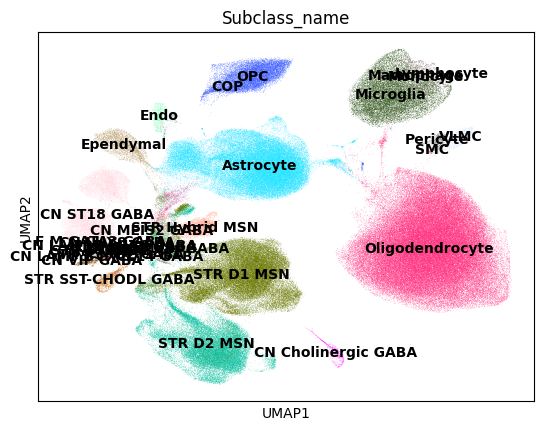

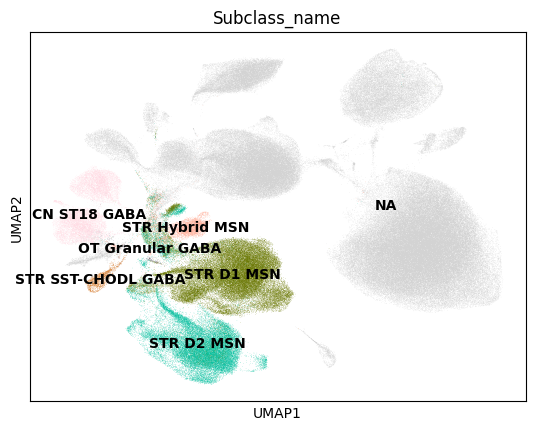

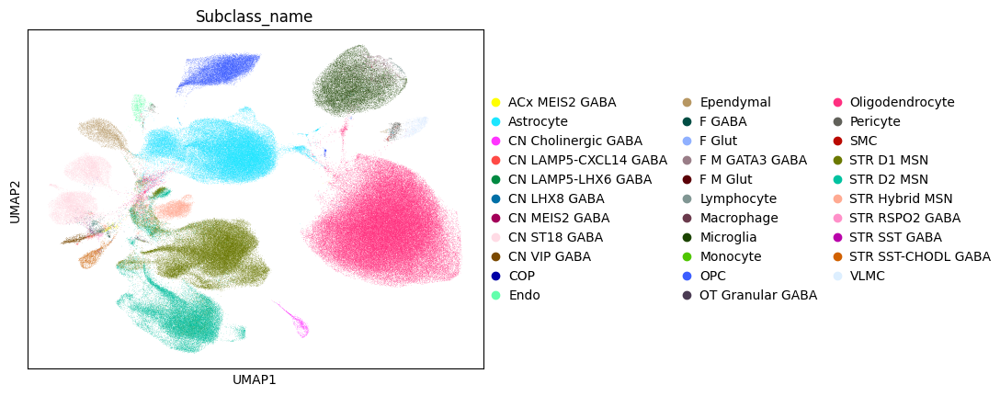

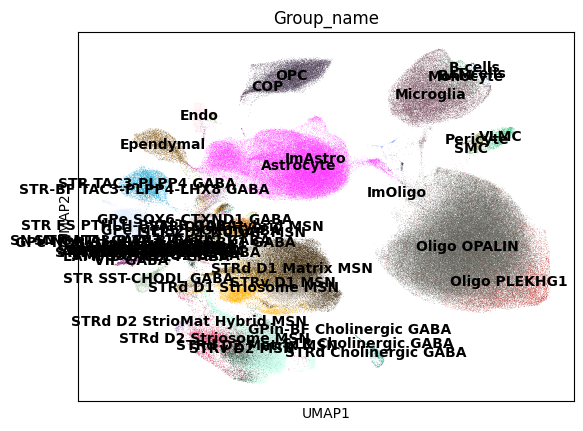

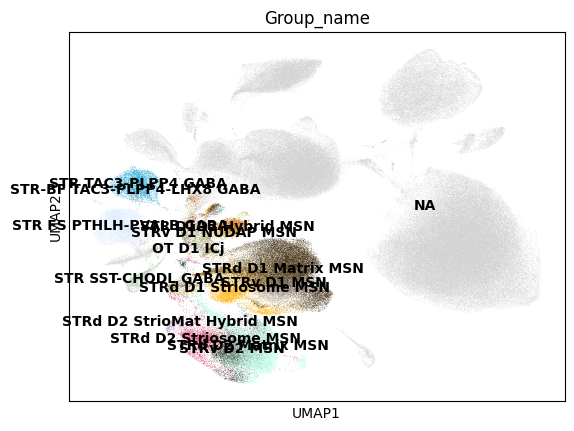

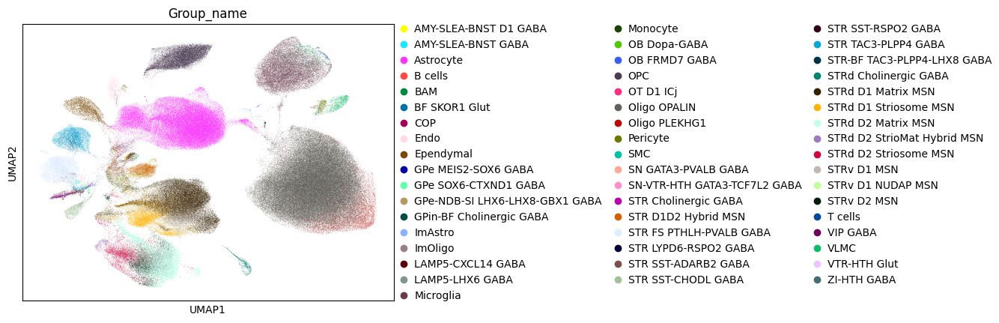

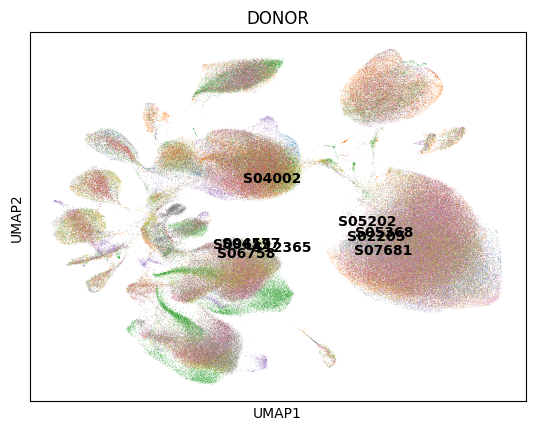

In [8]:
sc.pl.umap(adata, color=["Subclass_name"], legend_loc="on data")
sc.pl.umap(adata, color=["Subclass_name"], legend_loc="on data", groups=freq_subclass_neurons)
sc.pl.umap(adata, color=["Subclass_name"])

sc.pl.umap(adata, color=["Group_name"], legend_loc="on data")
sc.pl.umap(adata, color=["Group_name"], legend_loc="on data", groups=freq_group_neurons)
sc.pl.umap(adata, color=["Group_name"])



sc.pl.umap(adata, color=[SAMPLE_VARIABLE], groups=adata.obs[SAMPLE_VARIABLE].value_counts().index[:10].values,  legend_loc="on data")


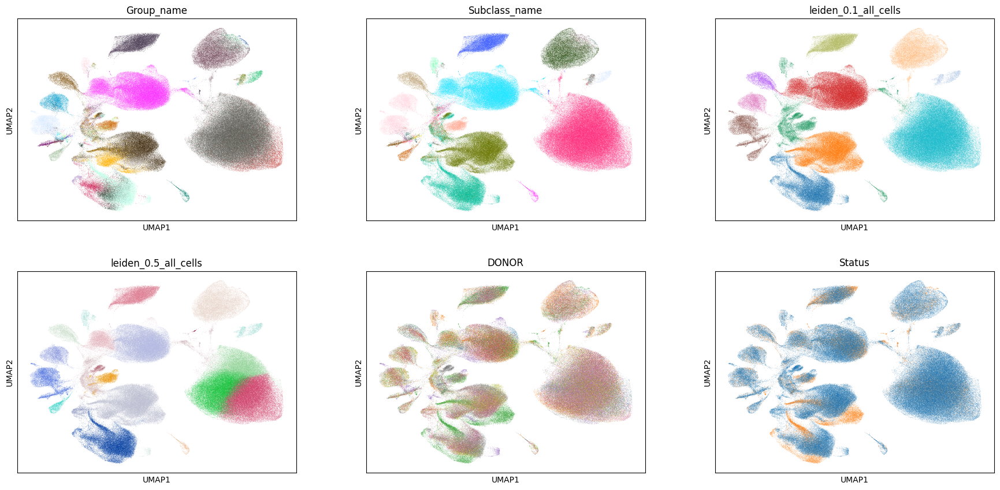

In [9]:
sc.pl.umap(adata, color=["Group_name", "Subclass_name", leiden_cluster_names[0], leiden_cluster_names[1], SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=3, legend_loc=None)

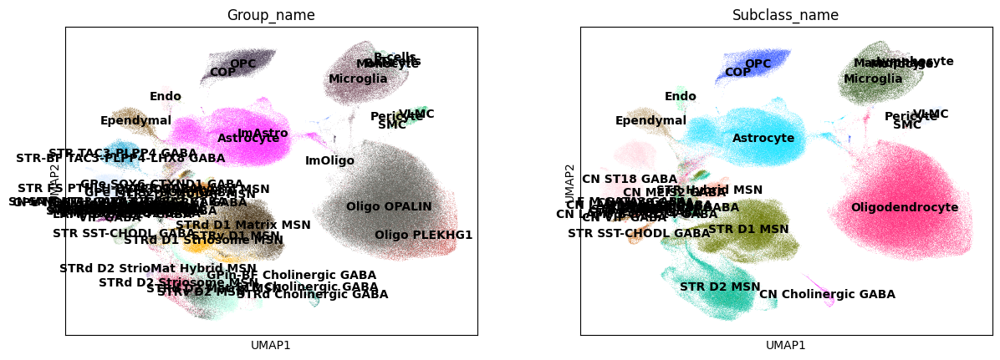

In [10]:
sc.pl.umap(adata, color=["Group_name", "Subclass_name"], ncols=3, legend_loc="on data")

# Broad cell type

In [11]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = 'leiden_0.1_all_cells'
adata.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].nunique()

11

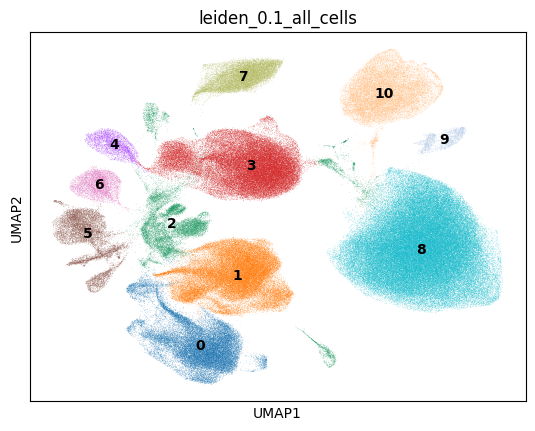

In [12]:
sc.pl.umap(adata, color=ADATA_NN_LEIDEN_COL_FOR_MAPPING, legend_loc='on data')

broad_ct
Oligo        119103
MSN           78722
Astro         54413
Microglia     20867
eMSN          17771
non-MSN       17264
OPC           15582
Ependymal      3928
Vascular       2141
Name: count, dtype: int64


... storing 'broad_ct' as categorical


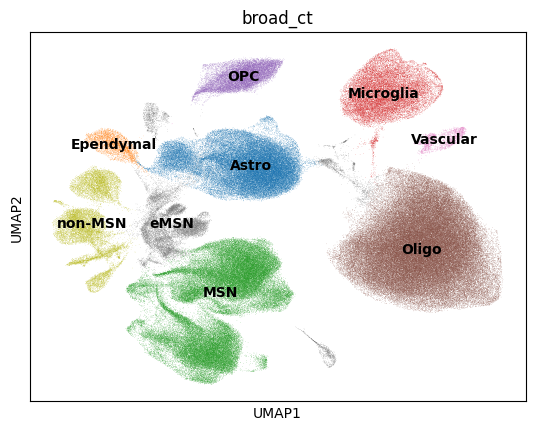

In [13]:
    # "0": "Astro",
    # "1": "MSN",
    # "2": "Vascular",
    # "3": "non-MSN",
    # "4": "OPC",
    # "5": "Microglia",
    # "6": "Oligo",
    # "7": "eMSN",
    # "8": "Lymphocyte",
    # "9": "Ependymal",
    # "10": "tmp",
    # "11": "tmp",

mapping_dict = {
    "0": "MSN",
    "1": "MSN",
    "2": "eMSN",
    "3": "Astro",
    "4": "Ependymal",
    "5": "non-MSN",
    "6": "non-MSN",
    "7": "OPC",
    "8": "Oligo",
    "9": "Vascular",
    "10": "Microglia",
    "11": "tmp",

}
adata.obs["broad_ct"] = adata.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict)

print(adata.obs["broad_ct"].value_counts())
sc.pl.umap(adata, color="broad_ct", legend_loc='on data')


# Glia: Oligo

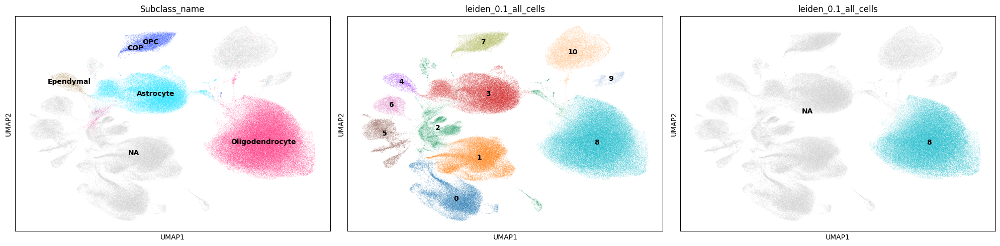

In [14]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["8"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["glia"]
NAME="_oligo"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

In [15]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-10-27 14:09:40,958 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 14:09:40 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 14:09:40,959 - harmonypy - INFO -   Parameters:
2026-10-27 14:09:40 | [INFO]   Parameters:
2026-10-27 14:09:40,960 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 14:09:40 | [INFO]     max_iter_harmony: 30
2026-10-27 14:09:40,961 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 14:09:40 | [INFO]     max_iter_kmeans: 20
2026-10-27 14:09:40,962 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 14:09:40 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 14:09:40,962 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 14:09:40 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 14:09:40,963 - harmonypy - INFO -     nclust: 100
2026-10-27 14:09:40 | [INFO]     nclust: 100
2026-10-27 14:09:40,964 - harmonypy - INFO -     block_size: 0.05
2026-10-27 14:09:40 | [INFO]     block_size: 0.05
2026-10-27 14:09:40,966 - harm

Running Harmony batch correction...


2026-10-27 14:09:45,242 - harmonypy - INFO - KMeans initialization complete.
2026-10-27 14:09:45 | [INFO] KMeans initialization complete.
2026-10-27 14:09:45,255 - harmonypy - INFO - Iteration 1 of 30
2026-10-27 14:09:45 | [INFO] Iteration 1 of 30
2026-10-27 14:09:45,887 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 14:09:45 | [INFO] Iteration 2 of 30
2026-10-27 14:09:46,478 - harmonypy - INFO - Converged after 2 iterations
2026-10-27 14:09:46 | [INFO] Converged after 2 iterations


Z_corr shape: (119103, 50), n_obs: 119103
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


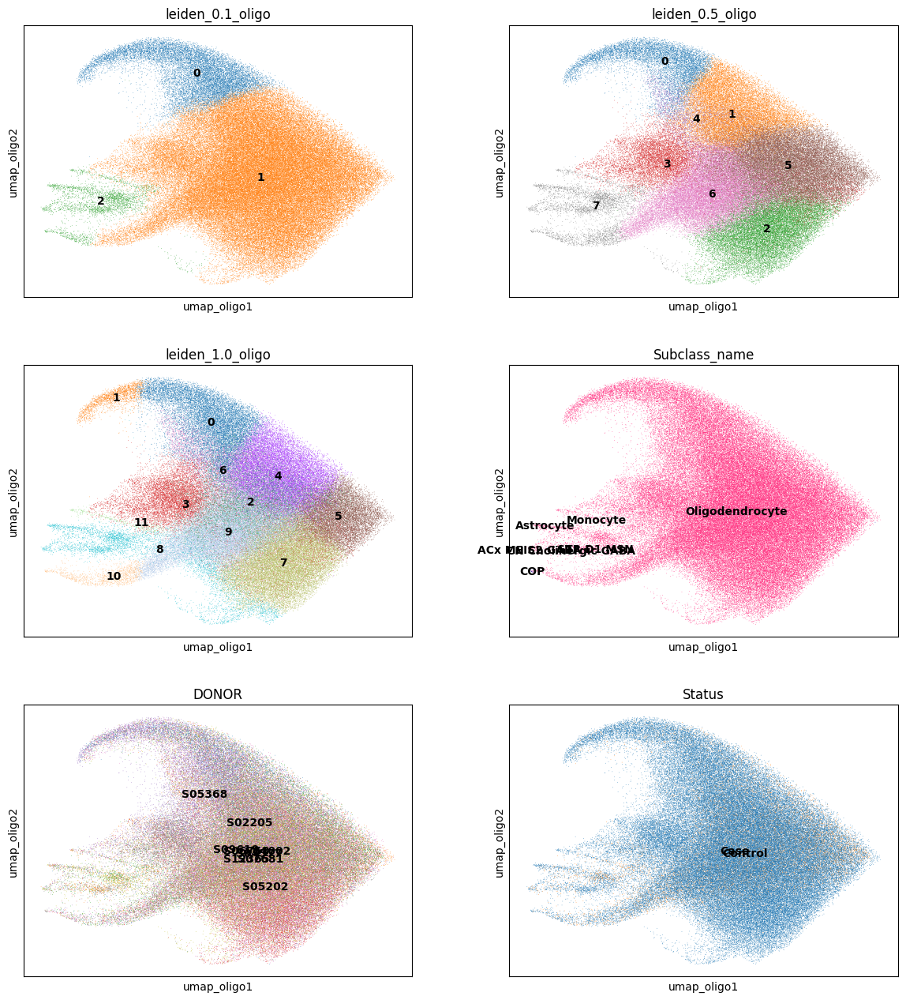

In [16]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2, legend_loc="on data")

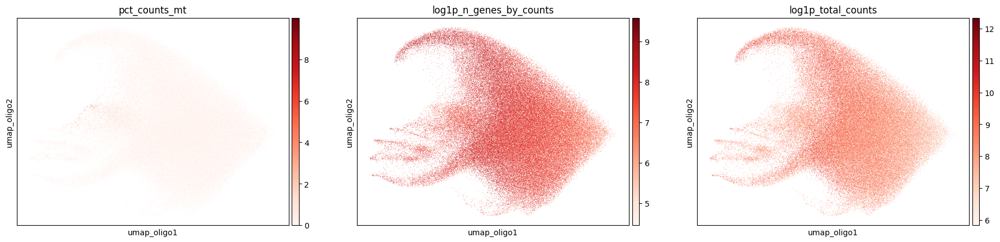

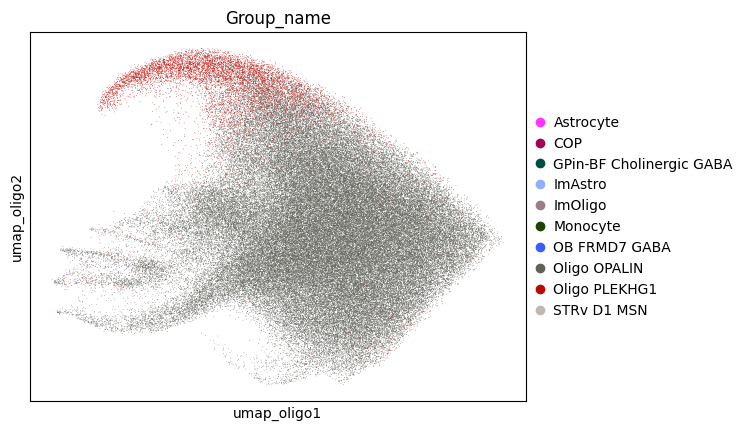

In [17]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["pct_counts_mt", "log1p_n_genes_by_counts", "log1p_total_counts"], cmap="Reds", legend_loc="on data")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"])

Assure that adata.var.index has same gene name of makers...


  0%|          | 0/15 [00:00<?, ?it/s]

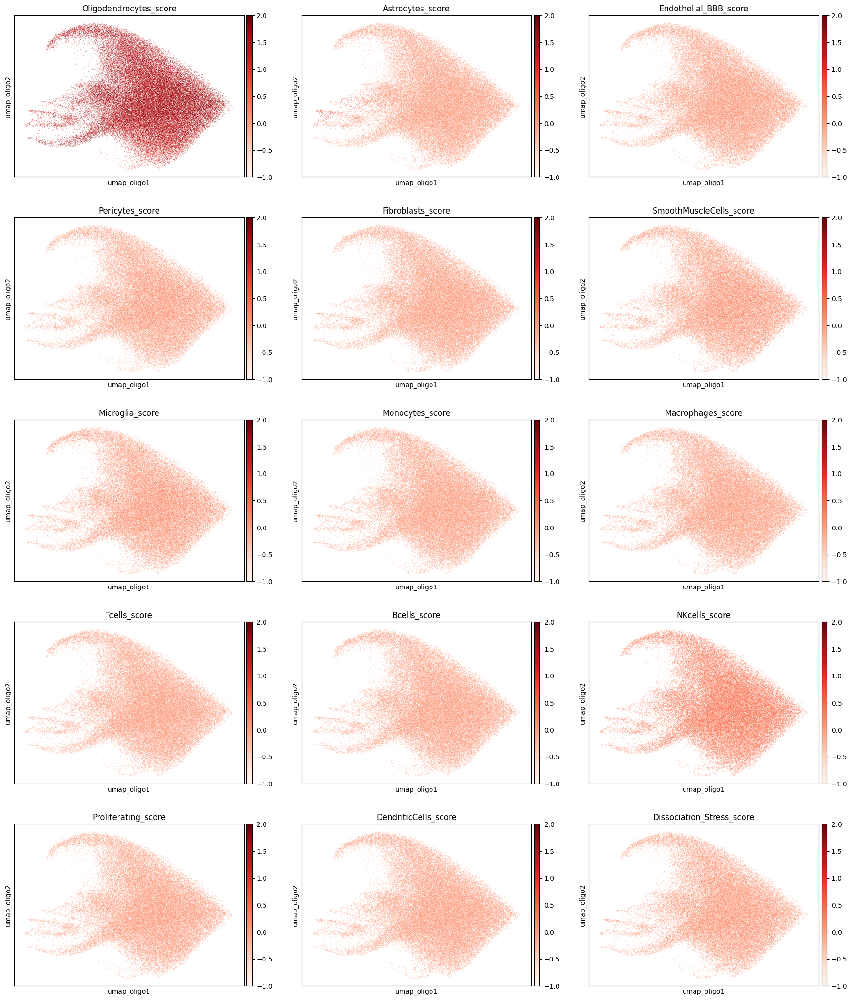

In [18]:
# gene markers score
col_scores = preprocessing.calculate_and_plot_markers(adata_nn, lmu.markers_ct, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}", vmin=-1, vmax=2)


In [19]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_1.0{NAME}"


In [20]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=50, markers=None,
                                             groups=["11", "10", "1"]
                                             )

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(30))

Cluster 11:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000171310,15.390989,5.403125,1.881345e-53,6.950252e-49,CHST11
1,ENSG00000148655,14.611071,3.410280,2.387361e-48,4.409813e-44,LRMDA
2,ENSG00000073849,13.331942,5.671598,1.509180e-40,1.858454e-36,ST6GAL1
3,ENSG00000081189,12.202641,4.252033,3.009034e-34,2.779069e-30,MEF2C
4,ENSG00000159216,11.654027,2.891771,2.188665e-31,1.617117e-27,RUNX1
5,ENSG00000145819,11.501605,4.207306,1.294849e-30,7.972599e-27,ARHGAP26
6,ENSG00000170776,10.625443,4.202300,2.269307e-26,1.197643e-22,AKAP13
7,ENSG00000107099,10.530178,5.465674,6.271547e-26,2.896122e-22,DOCK8
8,ENSG00000082074,10.455600,5.408308,1.381225e-25,5.669621e-22,FYB
9,ENSG00000077420,10.432951,5.651086,1.753558e-25,6.478170e-22,APBB1IP


Cluster 10:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000018236,55.068810,5.966377,0.000000e+00,0.000000e+00,CNTN1
1,ENSG00000164418,54.926495,6.032696,0.000000e+00,0.000000e+00,GRIK2
2,ENSG00000139915,49.090496,3.788668,0.000000e+00,0.000000e+00,MDGA2
3,ENSG00000073910,48.228172,3.312392,0.000000e+00,0.000000e+00,FRY
4,ENSG00000187398,45.423615,6.102912,0.000000e+00,0.000000e+00,LUZP2
5,ENSG00000169851,42.275749,4.822702,0.000000e+00,0.000000e+00,PCDH7
6,ENSG00000185774,40.338593,4.067788,0.000000e+00,0.000000e+00,KCNIP4
7,ENSG00000178568,39.362801,1.290560,0.000000e+00,0.000000e+00,ERBB4
8,ENSG00000067798,38.614452,2.255062,0.000000e+00,0.000000e+00,NAV3
9,ENSG00000227036,38.603756,4.702794,0.000000e+00,0.000000e+00,LINC00511


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000058335,66.692772,4.577796,0.0,0.0,RASGRF1
1,ENSG00000078328,62.788754,7.796046,0.0,0.0,RBFOX1
2,ENSG00000257585,62.463696,2.949098,0.0,0.0,LINC00609
3,ENSG00000077522,61.490868,4.063187,0.0,0.0,ACTN2
4,ENSG00000182871,60.855450,4.561192,0.0,0.0,COL18A1
5,ENSG00000144218,58.309269,6.147609,0.0,0.0,AFF3
6,ENSG00000158865,56.250908,3.090037,0.0,0.0,SLC5A11
7,ENSG00000120278,55.639809,3.865351,0.0,0.0,PLEKHG1
8,ENSG00000134769,54.219116,2.761545,0.0,0.0,DTNA
9,ENSG00000132854,54.218971,5.311975,0.0,0.0,KANK4


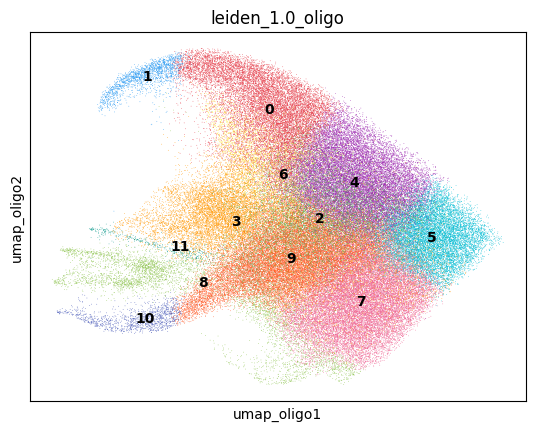

In [21]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=ADATA_NN_LEIDEN_COL_FOR_MAPPING, palette=lmu.custom_palette, legend_loc="on data")


ct_for_deg
Oligodendrocyte    119103
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


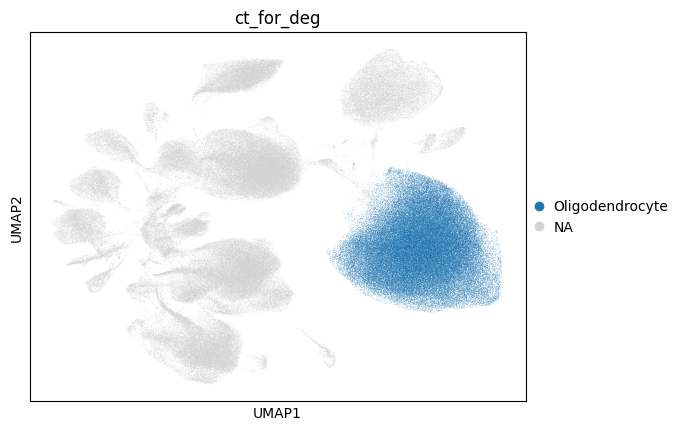

... storing 'tmp_label' as categorical


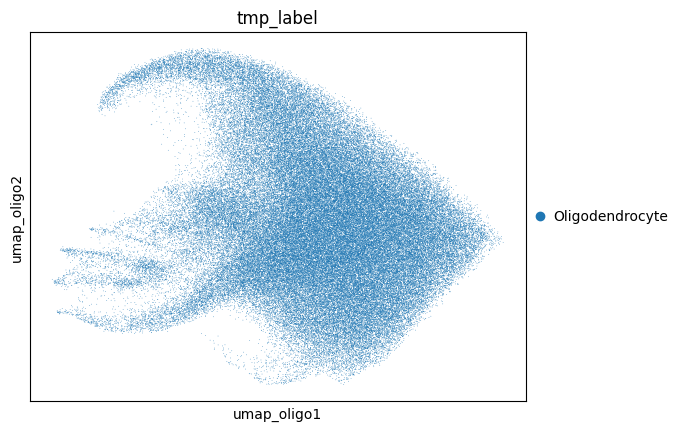

In [22]:
# For Oligo: leave all as Oligo

mapping_dict = {
    # "8": LOW_QUALITY_LABEL,
    # "10": LOW_QUALITY_LABEL,
    # "12": LOW_QUALITY_LABEL,

    # Oligodendrocyte all the rest

    # INGORE cop!
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("Oligodendrocyte")

# Add to orignla ct
if "ct_for_deg" not in adata.obs.columns:
    adata.obs["ct_for_deg"] = np.nan
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

In [16]:
del adata_nn

# Glia: OPC

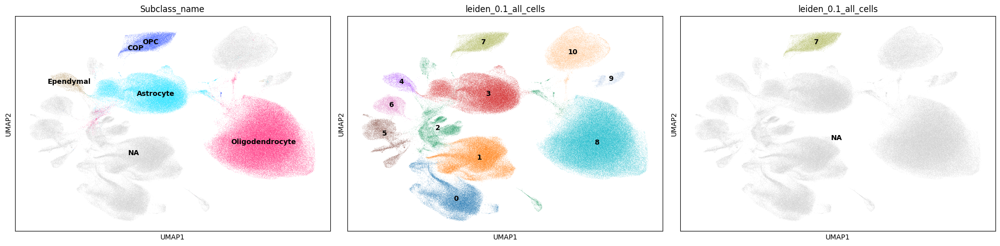

In [23]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["7"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["glia"]
NAME="_OPC"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-10-27 14:19:41,730 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 14:19:41 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 14:19:41,731 - harmonypy - INFO -   Parameters:
2026-10-27 14:19:41 | [INFO]   Parameters:
2026-10-27 14:19:41,732 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 14:19:41 | [INFO]     max_iter_harmony: 30
2026-10-27 14:19:41,733 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 14:19:41 | [INFO]     max_iter_kmeans: 20
2026-10-27 14:19:41,734 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 14:19:41 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 14:19:41,735 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 14:19:41 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 14:19:41,736 - harmonypy - INFO -     nclust: 100
2026-10-27 14:19:41 | [INFO]     nclust: 100
2026-10-27 14:19:41,737 - harmonypy - INFO -     block_size: 0.05
2026-10-27 14:19:41 | [INFO]     block_size: 0.05
2026-10-27 14:19:41,738 - harm

Running Harmony batch correction...


2026-10-27 14:19:42,381 - harmonypy - INFO - KMeans initialization complete.
2026-10-27 14:19:42 | [INFO] KMeans initialization complete.
2026-10-27 14:19:42,386 - harmonypy - INFO - Iteration 1 of 30
2026-10-27 14:19:42 | [INFO] Iteration 1 of 30
2026-10-27 14:19:42,904 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 14:19:42 | [INFO] Iteration 2 of 30
2026-10-27 14:19:43,431 - harmonypy - INFO - Converged after 2 iterations
2026-10-27 14:19:43 | [INFO] Converged after 2 iterations


Z_corr shape: (15582, 50), n_obs: 15582
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


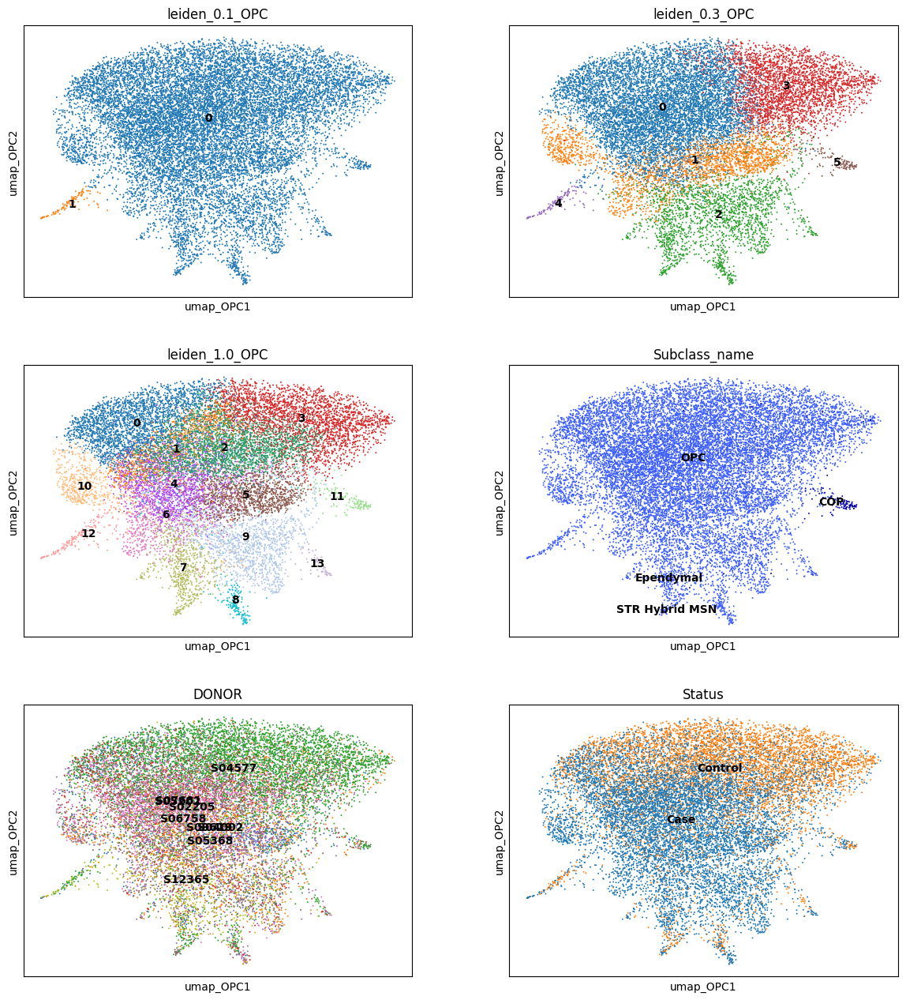

In [24]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2, legend_loc="on data")

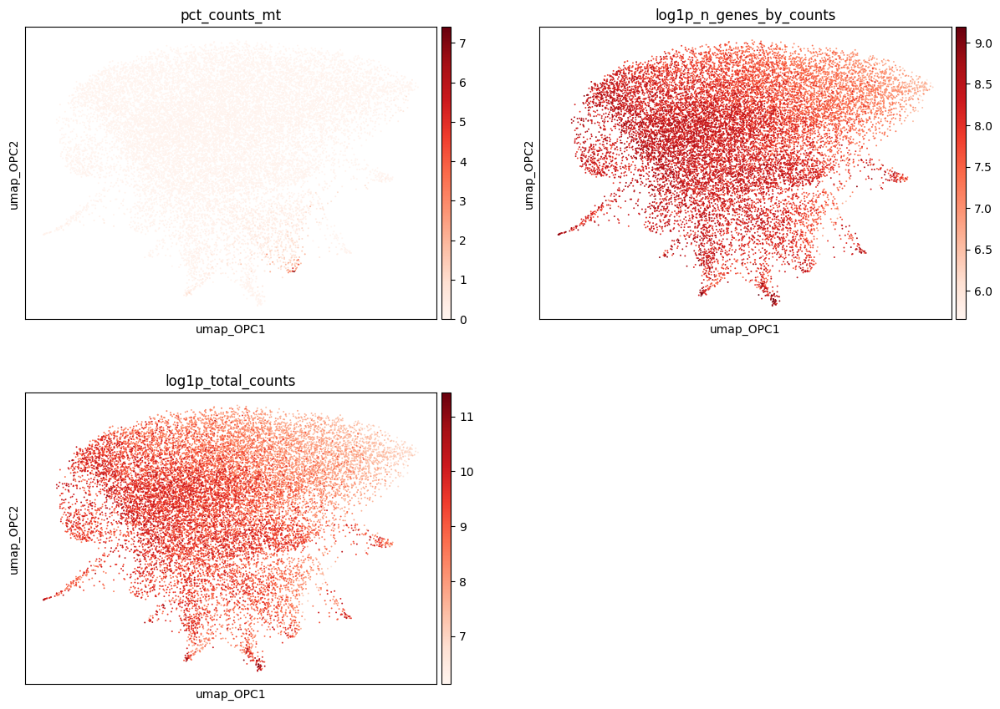

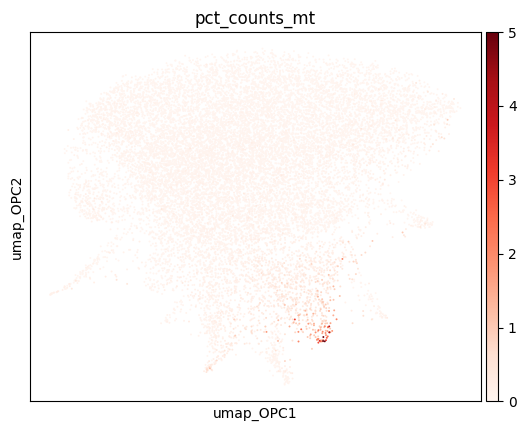

In [25]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["pct_counts_mt", "log1p_n_genes_by_counts", "log1p_total_counts"], cmap="Reds", legend_loc="on data", ncols=2)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["pct_counts_mt"], vmax=5, cmap="Reds", legend_loc="on data", ncols=2)

In [26]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_1.0{NAME}"


In [27]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=50, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(15))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000247809,40.941856,2.618950,0.000000e+00,0.000000e+00,NR2F2-AS1
1,ENSG00000275443,30.735119,2.578776,1.933040e-207,3.570614e-203,AC012409.2
2,ENSG00000104490,28.473190,1.018064,2.516567e-178,3.098985e-174,NCALD
3,ENSG00000224184,27.082884,1.244670,1.566546e-161,1.446822e-157,MIR3681HG
4,ENSG00000149972,22.662794,1.213868,1.043471e-113,7.709791e-110,CNTN5
5,ENSG00000183098,22.134140,0.732639,1.483134e-108,9.131901e-105,GPC6
6,ENSG00000185046,21.580236,0.418035,2.754512e-103,1.453713e-99,ANKS1B
7,ENSG00000242808,21.444057,0.597076,5.188592e-102,2.396027e-98,SOX2-OT
8,ENSG00000165973,21.103771,0.946275,7.344006e-99,3.014551e-95,NELL1
9,ENSG00000078328,20.441544,0.629046,7.144450e-93,2.639374e-89,RBFOX1


Cluster 4:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000185053,20.568911,1.325819,5.212377e-94,1.925609e-89,SGCZ
1,ENSG00000152578,14.132080,0.633860,2.409227e-45,4.450204e-41,GRIA4
2,ENSG00000184226,13.956743,0.281672,2.862180e-44,3.524583e-40,PCDH9
3,ENSG00000174469,13.733635,0.896159,6.384794e-43,5.896836e-39,CNTNAP2
4,ENSG00000154080,13.695613,0.742423,1.078459e-42,7.968305e-39,CHST9
5,ENSG00000144619,13.617365,0.737605,3.157580e-42,1.944175e-38,CNTN4
6,ENSG00000144278,13.413589,0.533589,5.034297e-41,2.324775e-37,GALNT13
7,ENSG00000112137,13.377139,0.843942,8.225245e-41,3.376280e-37,PHACTR1
8,ENSG00000186472,13.154083,1.137400,1.612271e-39,5.956213e-36,PCLO
9,ENSG00000179915,13.089504,0.210830,3.780652e-39,1.269715e-35,NRXN1


Cluster 5:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000170381,37.166592,2.631075,2.365383e-302,8.738434e-298,SEMA3E
1,ENSG00000152578,31.766117,1.405023,1.902193e-221,3.513635e-217,GRIA4
2,ENSG00000091129,27.539557,0.800849,5.902646e-167,5.451537e-163,NRCAM
3,ENSG00000071991,24.645538,3.006621,4.108646e-134,3.035714e-130,CDH19
4,ENSG00000184305,24.267582,1.382783,4.313212e-130,2.655716e-126,CCSER1
5,ENSG00000144278,23.050880,0.836032,1.441310e-117,5.324633e-114,GALNT13
6,ENSG00000144406,21.448643,0.961849,4.701718e-102,1.579051e-98,UNC80
7,ENSG00000048052,20.903051,1.099580,5.022934e-97,1.546352e-93,HDAC9
8,ENSG00000229807,20.480232,2.051595,3.231173e-93,9.182248e-90,XIST
9,ENSG00000136267,20.061081,1.259598,1.615367e-89,3.729781e-86,DGKB


... (18 outputs left out)

Cluster 7:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000112137,22.919397,2.394361,2.976718e-116,1.099689e-111,PHACTR1
1,ENSG00000185008,21.876106,3.833763,4.387491e-106,8.104354e-102,ROBO2
2,ENSG00000210082,21.560503,2.240947,4.219931e-103,5.196563e-99,MT-RNR2
3,ENSG00000136267,19.162849,1.615903,7.561829e-82,6.983916e-78,DGKB
4,ENSG00000198668,18.382877,1.856107,1.801552e-75,1.331095e-71,CALM1
5,ENSG00000179399,18.340944,2.164887,3.899579e-75,2.401036e-71,GPC5
6,ENSG00000145934,17.974836,4.732508,3.067626e-72,1.416591e-68,TENM2
7,ENSG00000198838,16.443808,4.756072,9.289397e-61,3.813091e-57,RYR3
8,ENSG00000112541,16.285854,2.118708,1.243783e-59,4.594906e-56,PDE10A
9,ENSG00000185760,16.256184,4.139686,2.019310e-59,6.781762e-56,KCNQ5


Cluster 13:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000245532,8.390018,2.710418,4.860716e-17,1.795694e-12,NEAT1
1,ENSG00000145819,6.351243,2.738854,2.135824e-10,2.692012e-06,ARHGAP26
2,ENSG00000138639,6.347664,4.459610,2.186081e-10,2.692012e-06,ARHGAP24
3,ENSG00000077420,6.125359,6.135428,9.047942e-10,8.356453e-06,APBB1IP
4,ENSG00000059377,5.700643,4.567680,1.193562e-08,8.818751e-05,TBXAS1
5,ENSG00000107099,5.459834,5.791033,4.765796e-08,2.648678e-04,DOCK8
6,ENSG00000082074,5.450645,5.753391,5.018744e-08,2.648678e-04,FYB
7,ENSG00000163219,5.250296,5.404646,1.518552e-07,6.879457e-04,ARHGAP25
8,ENSG00000198879,5.232099,2.290531,1.675963e-07,6.879457e-04,SFMBT2
9,ENSG00000081237,4.869994,6.259746,1.116017e-06,4.122902e-03,PTPRC


In [ ]:
# # chekjc fro  COP marjer
# sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["GPR17", "TCF7L2"], layer="log1p_norm", gene_symbols="gene_symbol", legend_loc="on data")

In [ ]:
# lmu.aucell(adata_nn, ["MBP", 'PLP1', 'MOBP', 'TMEM144', "MOG"], "oligo_score")
# lmu.plot_umap_spatial(adata_nn, color=["oligo_score"], name=NAME, ncols=1, cmap="Reds")

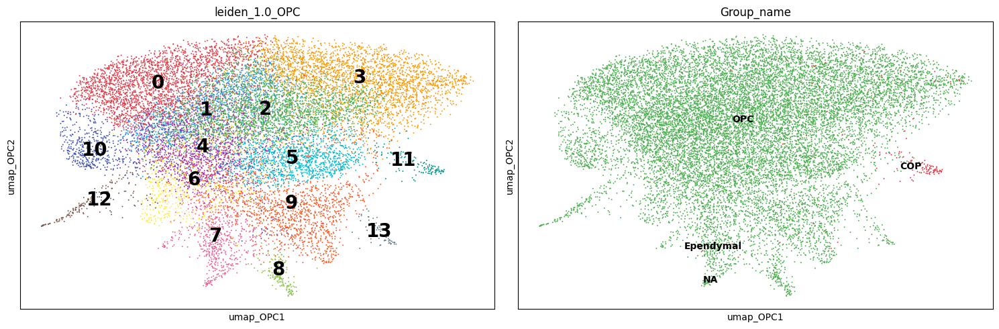

In [28]:
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Oligodendrocyte    119103
OPC                  7936
-Low_quality         7479
COP                   167
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


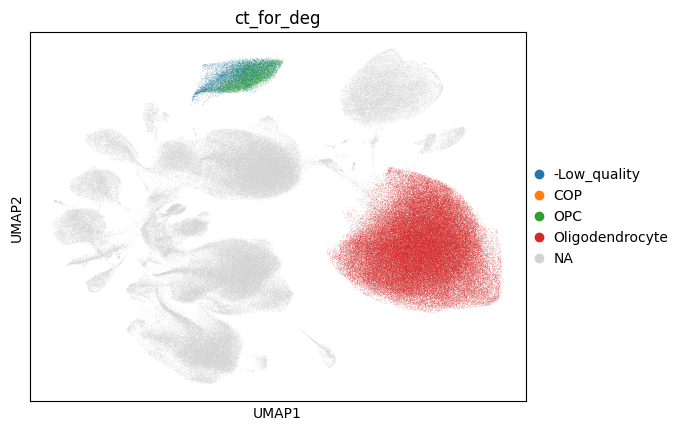

... storing 'tmp_label' as categorical


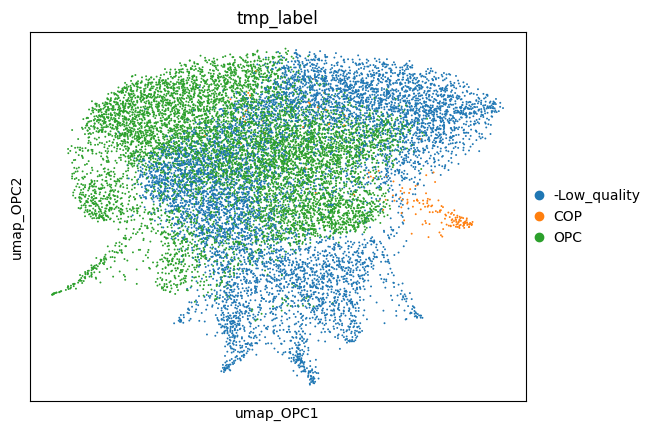

In [29]:
mapping_dict = {
    # COP
    "11": "COP",               # GPR17, BCAS1, TNS3, SIRT2, BMPER: classic COP/NFOL

    # Low quality / contamination
    "9":  LOW_QUALITY_LABEL,   # mito + housekeeping (MT-CO2, MT-ND3, FTH1, ACTB) + astro ambient (CST3, MT3)
    "3":  LOW_QUALITY_LABEL,   # MALAT1, RPL13, DDX5, lncRNAs, low logFC: low complexity
    "13": LOW_QUALITY_LABEL,   # microglia doublets (PTPRC, DOCK8, APBB1IP, SLCO2B1)
    "7":  LOW_QUALITY_LABEL,   # MSN neuron doublets (PDE10A, RYR2/3, KCNQ5) + PLP1
    "8":  LOW_QUALITY_LABEL,   # mature oligo doublets (ST18, CLDN11, PLP1, MBP, ENPP2)
    "4":  LOW_QUALITY_LABEL,   # neuronal contamination (PCLO, GABRB2, TSHZ2, PHACTR1); borderline
    "1":  LOW_QUALITY_LABEL,   # astro doublets/ambient (AQP4-AS1, SELENOP); borderline

    # OPC: all the rest (0, 2, 5, 6, 10, 12)
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("OPC")

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

# Glia: Astrocyte

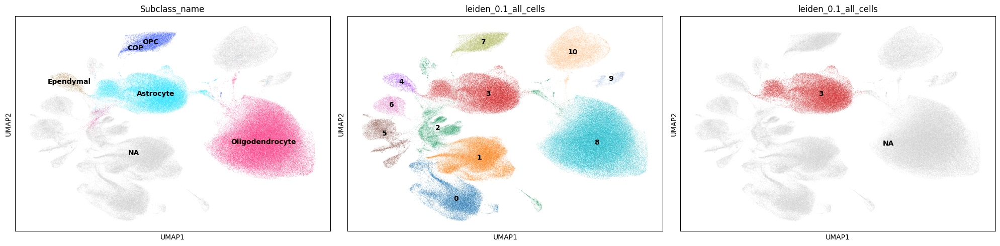

In [31]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["3"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["glia"]
NAME="_astro"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-10-27 14:26:06,750 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 14:26:06 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 14:26:06,751 - harmonypy - INFO -   Parameters:
2026-10-27 14:26:06 | [INFO]   Parameters:
2026-10-27 14:26:06,752 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 14:26:06 | [INFO]     max_iter_harmony: 30
2026-10-27 14:26:06,753 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 14:26:06 | [INFO]     max_iter_kmeans: 20
2026-10-27 14:26:06,754 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 14:26:06 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 14:26:06,755 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 14:26:06 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 14:26:06,755 - harmonypy - INFO -     nclust: 100
2026-10-27 14:26:06 | [INFO]     nclust: 100
2026-10-27 14:26:06,756 - harmonypy - INFO -     block_size: 0.05
2026-10-27 14:26:06 | [INFO]     block_size: 0.05
2026-10-27 14:26:06,757 - harm

Running Harmony batch correction...


2026-10-27 14:26:08,699 - harmonypy - INFO - KMeans initialization complete.
2026-10-27 14:26:08 | [INFO] KMeans initialization complete.
2026-10-27 14:26:08,706 - harmonypy - INFO - Iteration 1 of 30
2026-10-27 14:26:08 | [INFO] Iteration 1 of 30
2026-10-27 14:26:09,168 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 14:26:09 | [INFO] Iteration 2 of 30
2026-10-27 14:26:09,617 - harmonypy - INFO - Iteration 3 of 30
2026-10-27 14:26:09 | [INFO] Iteration 3 of 30
2026-10-27 14:26:10,171 - harmonypy - INFO - Iteration 4 of 30
2026-10-27 14:26:10 | [INFO] Iteration 4 of 30
2026-10-27 14:26:10,741 - harmonypy - INFO - Converged after 4 iterations
2026-10-27 14:26:10 | [INFO] Converged after 4 iterations


Z_corr shape: (54413, 50), n_obs: 54413
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


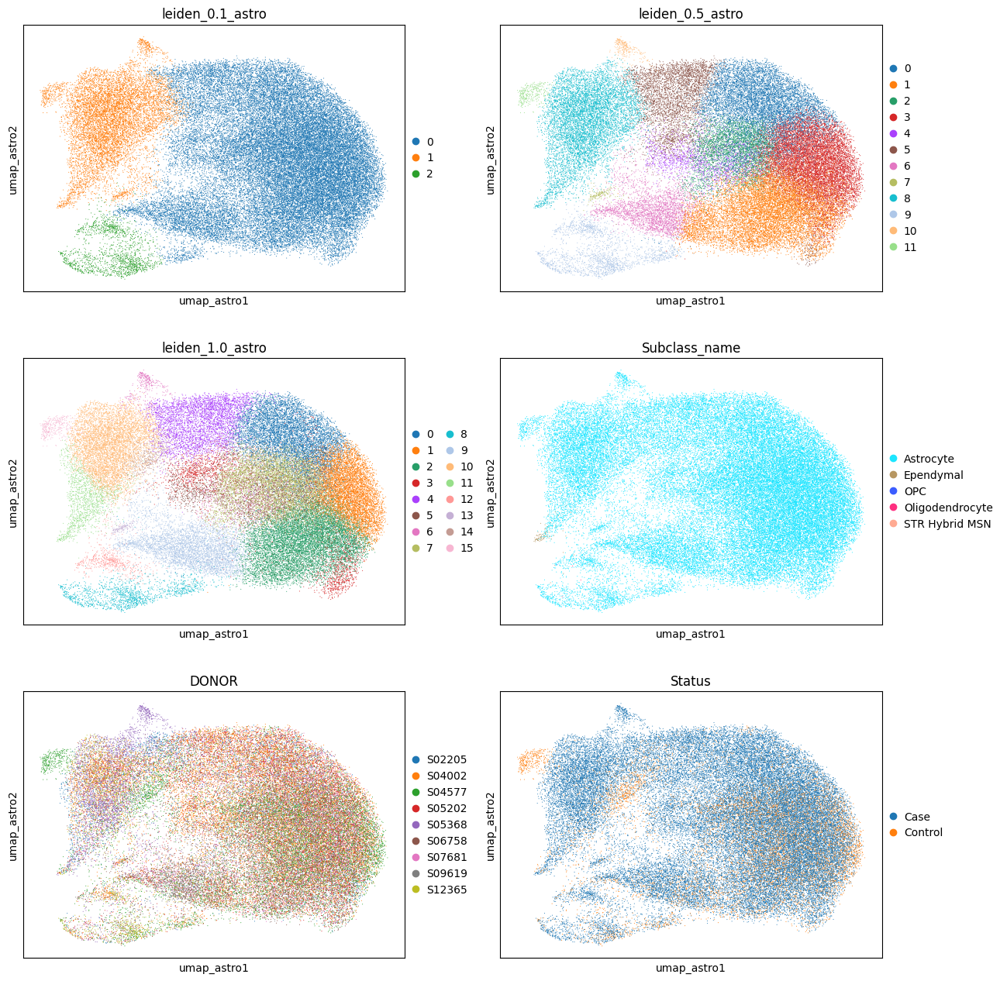

In [32]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2)

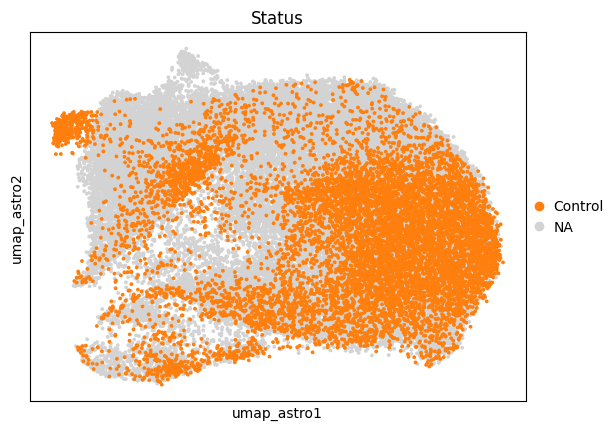

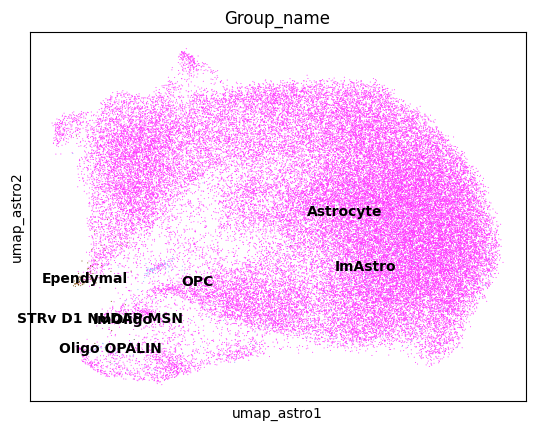

In [33]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[ CONDITION_VARIABLE], groups="Control", size=30,ncols=2)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[ "Group_name"],ncols=2, legend_loc="on data")

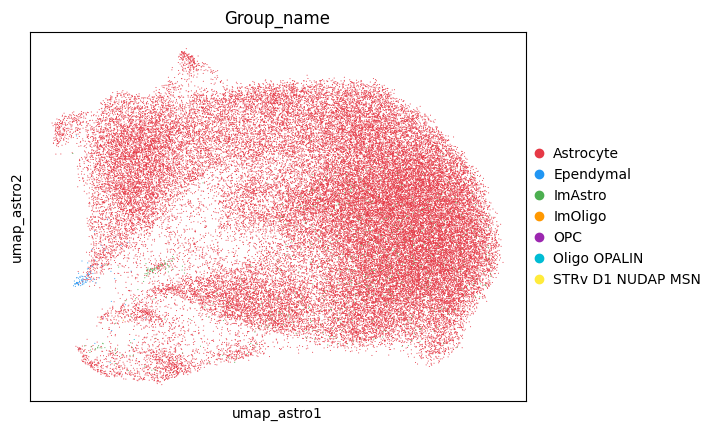

In [34]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], palette=lmu.custom_palette)

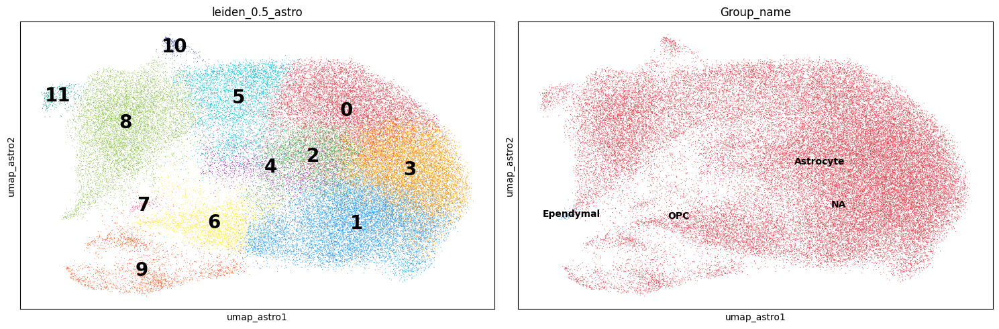

In [35]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.5{NAME}"
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

In [36]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=20, markers=None, 
                                             #groups=["12"]
                                             )

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(20))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000184226,46.681831,0.467438,0.000000e+00,0.000000e+00,PCDH9
1,ENSG00000198838,44.337784,0.917708,0.000000e+00,0.000000e+00,RYR3
2,ENSG00000157445,43.379307,1.051171,0.000000e+00,0.000000e+00,CACNA2D3
3,ENSG00000165092,42.745266,0.957013,0.000000e+00,0.000000e+00,ALDH1A1
4,ENSG00000083067,42.509354,0.745112,0.000000e+00,0.000000e+00,TRPM3
5,ENSG00000172987,42.093117,0.876552,0.000000e+00,0.000000e+00,HPSE2
6,ENSG00000018236,41.646042,0.875404,0.000000e+00,0.000000e+00,CNTN1
7,ENSG00000185532,41.380413,0.528333,0.000000e+00,0.000000e+00,PRKG1
8,ENSG00000135838,41.095047,0.675588,0.000000e+00,0.000000e+00,NPL
9,ENSG00000182050,38.268036,0.610155,0.000000e+00,0.000000e+00,MGAT4C


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000164741,68.498558,1.273411,0.0,0.0,DLC1
1,ENSG00000134490,68.197800,1.355288,0.0,0.0,TMEM241
2,ENSG00000228842,67.460312,1.233937,0.0,0.0,PCDH9-AS2
3,ENSG00000101439,65.289619,1.262405,0.0,0.0,CST3
4,ENSG00000110436,63.374958,1.079211,0.0,0.0,SLC1A2
5,ENSG00000130203,62.337196,1.189727,0.0,0.0,APOE
6,ENSG00000274441,58.823246,1.096989,0.0,0.0,AC008957.2
7,ENSG00000231373,56.494053,1.300405,0.0,0.0,GNA14-AS1
8,ENSG00000255580,53.438156,1.254876,0.0,0.0,AP000462.1
9,ENSG00000198822,52.675915,1.113353,0.0,0.0,GRM3


Cluster 3:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000179399,74.029518,0.993658,0.0,0.0,GPC5
1,ENSG00000185565,72.941490,0.467532,0.0,0.0,LSAMP
2,ENSG00000179915,69.274803,1.106050,0.0,0.0,NRXN1
3,ENSG00000198822,65.499298,1.434105,0.0,0.0,GRM3
4,ENSG00000164199,64.321701,0.823218,0.0,0.0,ADGRV1
5,ENSG00000178568,62.651421,0.657901,0.0,0.0,ERBB4
6,ENSG00000234377,61.712334,0.911090,0.0,0.0,RNF219-AS1
7,ENSG00000135298,60.733677,0.618737,0.0,0.0,ADGRB3
8,ENSG00000110436,59.058838,1.059411,0.0,0.0,SLC1A2
9,ENSG00000163288,58.717903,0.696884,0.0,0.0,GABRB1


... (14 outputs left out)

Cluster 7:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000155849,10.536774,3.623923,5.847035e-26,2.160070e-21,ELMO1
1,ENSG00000107099,10.106558,4.585202,5.166795e-24,9.197391e-20,DOCK8
2,ENSG00000159216,10.070380,3.115332,7.468850e-24,9.197391e-20,RUNX1
3,ENSG00000162946,9.453253,4.554317,3.284615e-21,3.033588e-17,DISC1
4,ENSG00000266028,8.939702,2.400126,3.902210e-19,2.883187e-15,SRGAP2
5,ENSG00000077420,8.726908,5.019019,2.617310e-18,1.611522e-14,APBB1IP
6,ENSG00000082074,8.669428,5.611540,4.342981e-18,2.292039e-14,FYB
7,ENSG00000134516,8.450802,4.566691,2.893086e-17,1.335991e-13,DOCK2
8,ENSG00000067066,8.346868,3.331573,7.009749e-17,2.877346e-13,SP100
9,ENSG00000184005,8.316571,1.973736,9.054485e-17,3.344998e-13,ST6GALNAC3


Cluster 11:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000080824,29.699652,5.867441,7.758631e-194,2.866271e-189,HSP90AA1
1,ENSG00000120694,29.223999,6.187232,9.611775e-188,1.775439e-183,HSPH1
2,ENSG00000150991,28.190428,4.570167,7.662040e-175,9.435292e-171,UBC
3,ENSG00000109846,28.103977,5.547954,8.758749e-174,8.089361e-170,CRYAB
4,ENSG00000120885,28.065615,2.673513,2.576082e-173,1.903364e-169,CLU
5,ENSG00000096384,27.119926,5.207270,5.732591e-162,2.353101e-158,HSP90AB1
6,ENSG00000152137,27.028015,4.609334,6.926746e-161,2.558948e-157,HSPB8
7,ENSG00000170345,26.038986,4.473388,1.793033e-149,3.896471e-146,FOS
8,ENSG00000251562,25.803387,1.045669,8.124065e-147,1.579618e-143,MALAT1
9,ENSG00000109971,25.391094,5.434390,3.163021e-142,5.564357e-139,HSPA8


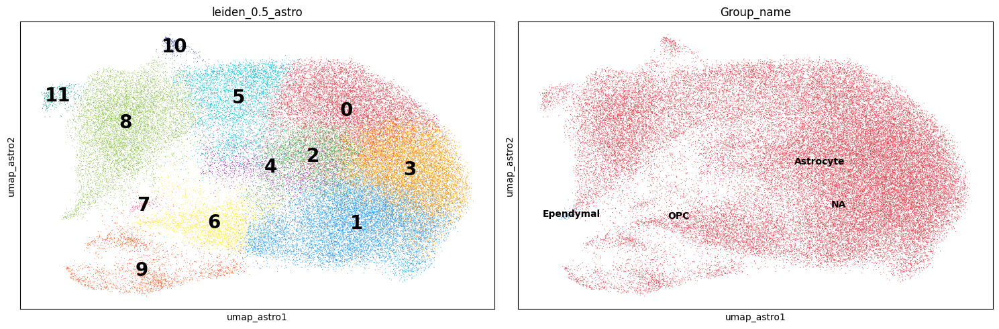

In [42]:

lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Oligodendrocyte    119103
Astrocyte           49194
-Low_quality        12698
OPC                  7936
COP                   167
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


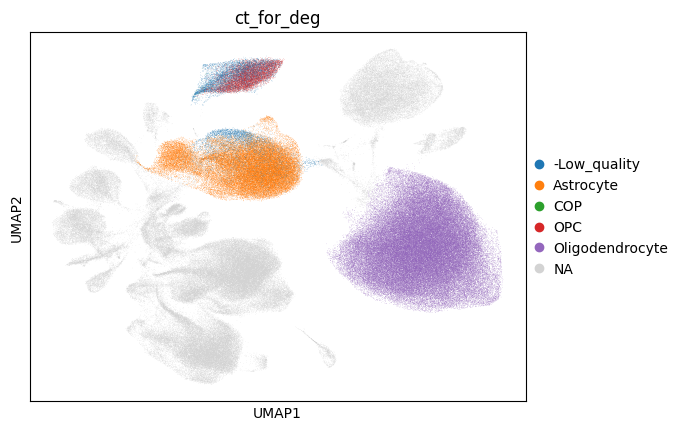

... storing 'tmp_label' as categorical


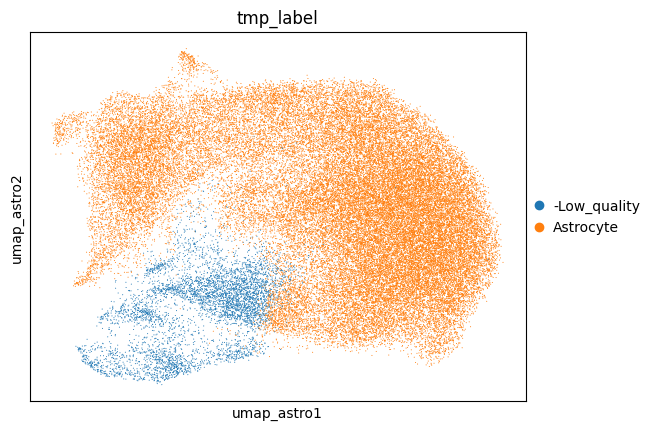

In [43]:
# ATTENTION: in Astr cluster there si always ependymal REAL cells

mapping_dict = {
    # Low quality / contamination
    "6":  LOW_QUALITY_LABEL,   # mito (MT-CO2, MT-ND3, MT-RNR2...) + FTL, FTH1, CALM1: low quality
    "7":  LOW_QUALITY_LABEL,   # microglia doublets (PTPRC, DOCK8, APBB1IP, INPP5D, FYB)
    "9":  LOW_QUALITY_LABEL,   # oligo doublets (PLP1, MBP, ST18, SLC24A2, EDIL3)
    # "11": LOW_QUALITY_LABEL,   # heat-shock/stress (HSP90AA1, HSPH1, HSPA8, DNAJB1, UBB, FOS) + NRXN3
    # "10": LOW_QUALITY_LABEL,   # heat-shock (HSP90AA1, HSPH1, CRYAB) + neuronal (NRXN3, DSCAM, STXBP5L) + XIST
    # "8":  LOW_QUALITY_LABEL,   # borderline: reactive-like (CD44, DCLK1, ROBO2) but strong HSP/FOS/UBC stress

    # Astro: all the rest
    # 0 = protoplasmic (ALDH1A1, SLC14A1, TRPM3, GRID2)
    # 1 = protoplasmic/homeostatic (SLC1A2, APOE, GRM3, DLC1)
    # 3 = protoplasmic (GPC5, LSAMP, NRXN1, ERBB4)
    # 2 = generic astro, low logFC (SLC1A2, FGFR3, SPARCL1)
    # 5 = fibrous/GFAP-high (GFAP, TNC, CD44, VCAN, COL21A1)
    # 4 = reactive/inflammatory (CHI3L1, OSMR, SLC39A14, F3)
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("Astrocyte")

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

In [ ]:
del adata_nn

# Ependymal

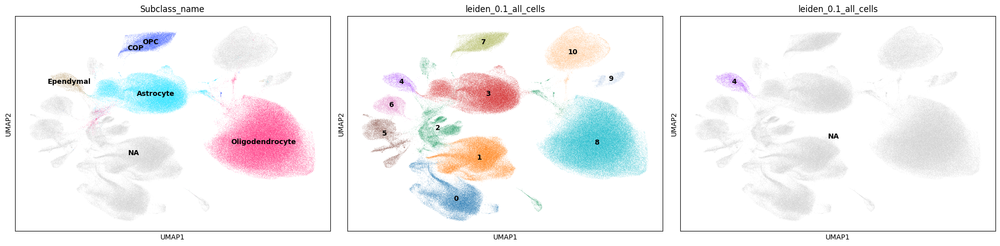

In [45]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["4"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["glia"]
NAME="_ependymal"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...
Running Harmony...
Running PCA before Harmony...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
2026-10-27 14:33:24,281 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 14:33:24 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 14:33:24,284 - harmonypy - INFO -   Parameters:
2026-10-27 14:33:24 | [INFO]   Parameters:
2026-10-27 14:33:24,286 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 14:33:24 | [INFO]     max_iter_harmony: 30
2026-10-27 14:33:24,287 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 14:33:24 | [INFO]     max_iter_kmeans: 20
2026-10-27 14:33:24,289 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 14:33:24 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 14:33:24,290 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 14:33:24 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 14:33:24,291 - harmonypy - INFO -     nclust: 100
2026-1

Running Harmony batch correction...


2026-10-27 14:33:24,504 - harmonypy - INFO - KMeans initialization complete.
2026-10-27 14:33:24 | [INFO] KMeans initialization complete.
2026-10-27 14:33:24,507 - harmonypy - INFO - Iteration 1 of 30
2026-10-27 14:33:24 | [INFO] Iteration 1 of 30
2026-10-27 14:33:24,980 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 14:33:24 | [INFO] Iteration 2 of 30
2026-10-27 14:33:25,515 - harmonypy - INFO - Iteration 3 of 30
2026-10-27 14:33:25 | [INFO] Iteration 3 of 30
2026-10-27 14:33:25,919 - harmonypy - INFO - Converged after 3 iterations
2026-10-27 14:33:25 | [INFO] Converged after 3 iterations


Z_corr shape: (3928, 50), n_obs: 3928
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


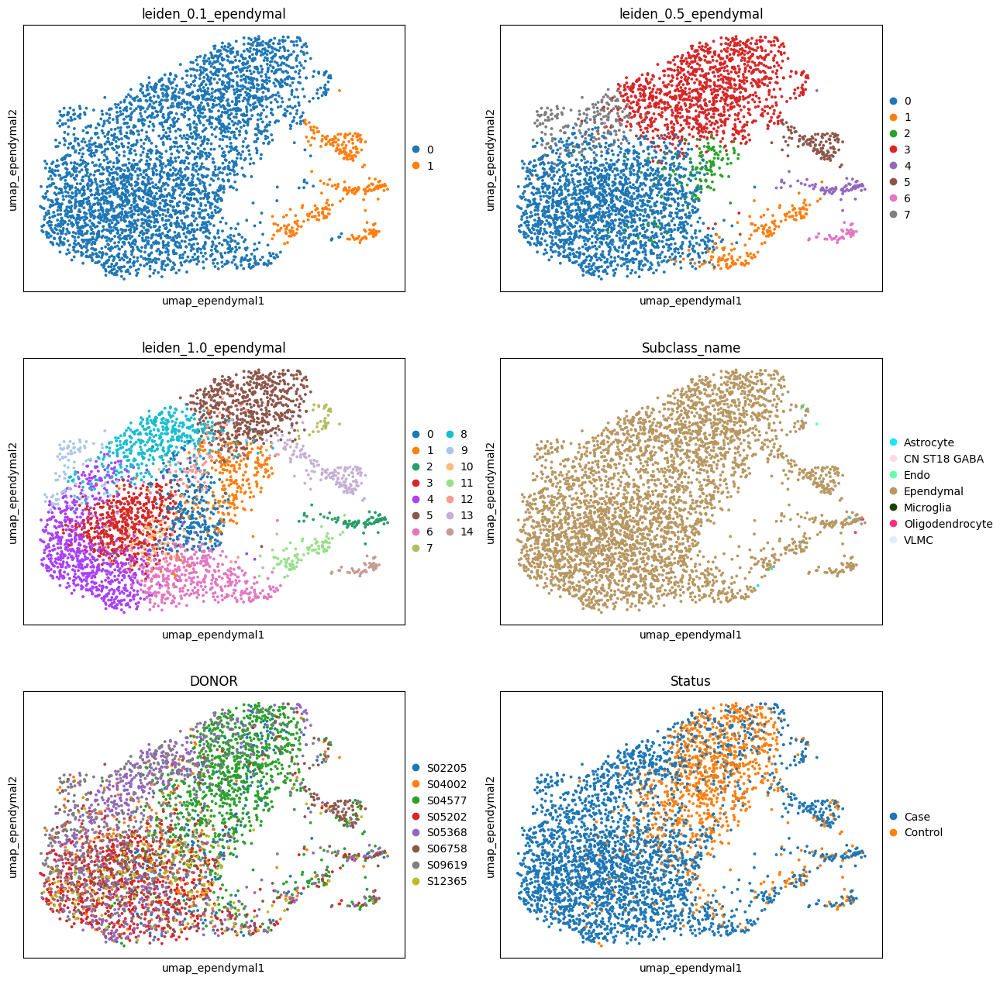

In [46]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2)

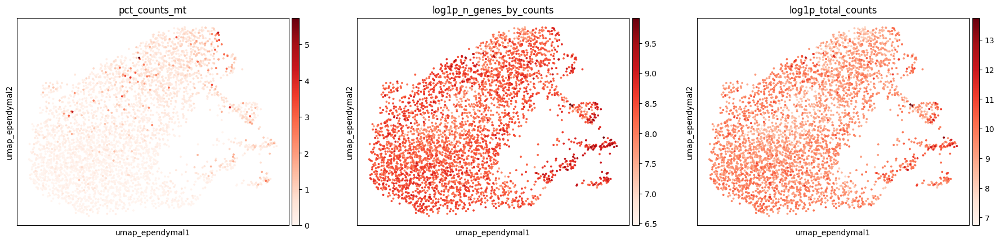

In [47]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["pct_counts_mt", "log1p_n_genes_by_counts", "log1p_total_counts"], cmap="Reds", legend_loc="on data")

In [48]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.1{NAME}"

In [49]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=10, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(10))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000197748,14.484840,0.529249,1.510734e-47,1.860368e-44,CFAP43
1,ENSG00000188596,13.749090,0.465763,5.157376e-43,5.013919e-40,CFAP54
2,ENSG00000197826,13.349568,0.537170,1.191376e-40,8.982249e-38,C4orf22
3,ENSG00000118997,12.925013,0.510903,3.252425e-38,2.225080e-35,DNAH7
4,ENSG00000165084,12.555092,0.649813,3.727502e-36,2.295085e-33,C8orf34
5,ENSG00000186952,11.968800,0.501443,5.177224e-33,2.483925e-30,TMEM232
6,ENSG00000165309,11.918708,0.446880,9.456425e-33,4.478830e-30,ARMC3
7,ENSG00000206530,11.448443,0.507060,2.394059e-30,9.827081e-28,CFAP44
8,ENSG00000007174,11.363496,0.431549,6.355003e-30,2.524439e-27,DNAH9
9,ENSG00000155761,11.229326,0.462433,2.927008e-29,1.103392e-26,SPAG17


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000175161,21.681393,3.577281,3.074313e-104,1.135743e-99,CADM2
1,ENSG00000150471,19.809156,3.240129,2.482067e-87,4.584749e-83,ADGRL3
2,ENSG00000182667,18.887060,3.334487,1.457399e-79,1.794690e-75,NTM
3,ENSG00000182621,18.455191,3.430302,4.736948e-76,4.374927e-72,PLCB1
4,ENSG00000113448,18.032219,3.778188,1.088345e-72,8.041343e-69,PDE4D
5,ENSG00000170017,17.902988,3.642240,1.117607e-71,6.881294e-68,ALCAM
6,ENSG00000150672,17.766628,2.022523,1.281673e-70,6.764120e-67,DLG2
7,ENSG00000152208,17.644764,5.730247,1.116390e-69,5.155349e-66,GRID2
8,ENSG00000184588,17.487728,2.748744,1.777018e-68,7.294266e-65,PDE4B
9,ENSG00000145934,17.001514,3.809039,8.002512e-65,2.956368e-61,TENM2


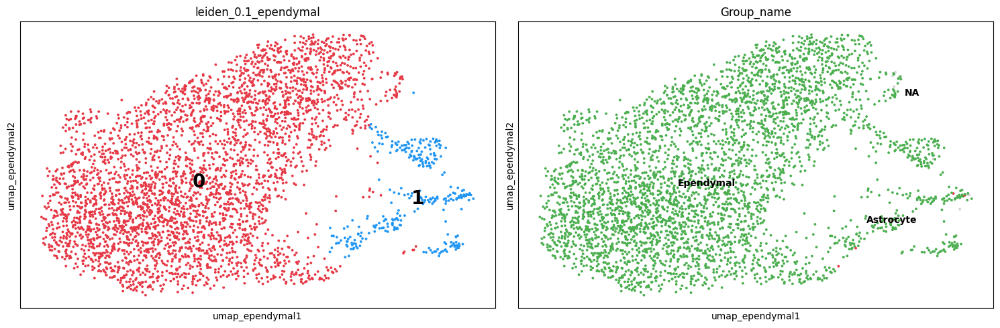

In [50]:
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Oligodendrocyte    119103
Astrocyte           49194
-Low_quality        13000
OPC                  7936
Ependymal            3626
COP                   167
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


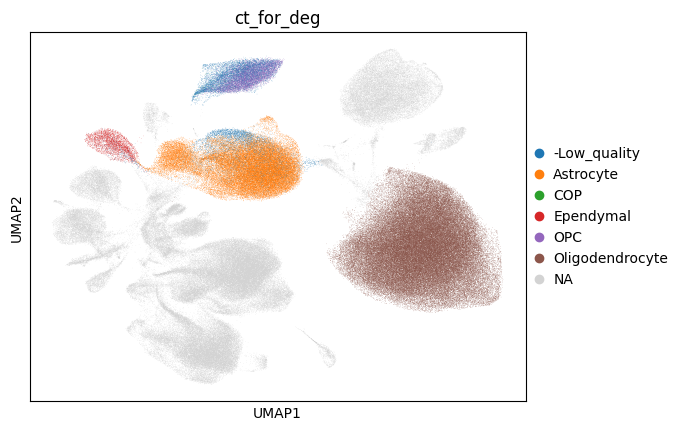

... storing 'tmp_label' as categorical


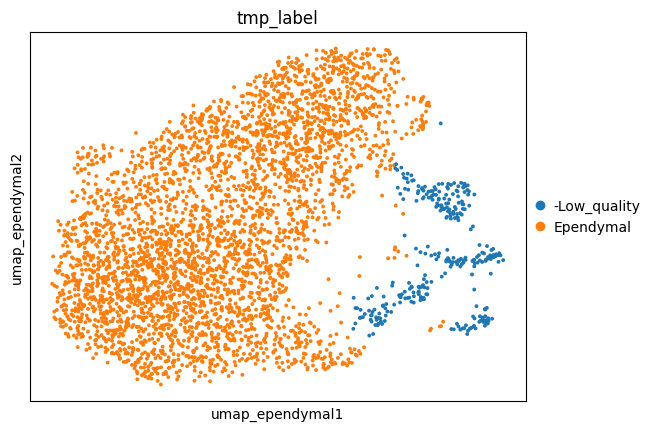

In [51]:
# ATTENTION: in Astr cluster there si always ependymal REAL cells

mapping_dict = {

    "0": "Ependymal",
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna(LOW_QUALITY_LABEL)

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

# Vascular

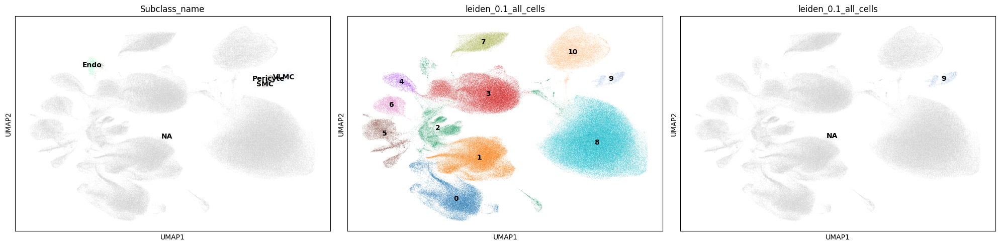

In [52]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["9"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["vascular"]
NAME="_vascular"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
Subsetting to copy with only HVG...
Scaling ...
Running Harmony...
Running PCA before Harmony...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
2026-10-27 14:34:32,142 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 14:34:32 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 14:34:32,145 - harmonypy - INFO -   Parameters:
2026-10-27 14:34:32 | [INFO]   Parameters:
2026-10-27 14:34:32,146 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 14:34:32 | [INFO]     max_iter_harmony: 30
2026-10-27 14:34:32,147 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 14:34:32 | [INFO]     max_iter_kmeans: 20
2026-10-27 14:34:32,150 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 14:34:32 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 14:34:32,153 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 14:34:32 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 14:34:32,158 - harmonypy - INFO -     nclust: 71
2026-10

Running Harmony batch correction...


2026-10-27 14:34:32,731 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 14:34:32 | [INFO] Iteration 2 of 30
2026-10-27 14:34:33,097 - harmonypy - INFO - Iteration 3 of 30
2026-10-27 14:34:33 | [INFO] Iteration 3 of 30
2026-10-27 14:34:33,478 - harmonypy - INFO - Iteration 4 of 30
2026-10-27 14:34:33 | [INFO] Iteration 4 of 30
2026-10-27 14:34:33,804 - harmonypy - INFO - Iteration 5 of 30
2026-10-27 14:34:33 | [INFO] Iteration 5 of 30
2026-10-27 14:34:34,078 - harmonypy - INFO - Iteration 6 of 30
2026-10-27 14:34:34 | [INFO] Iteration 6 of 30
2026-10-27 14:34:34,385 - harmonypy - INFO - Iteration 7 of 30
2026-10-27 14:34:34 | [INFO] Iteration 7 of 30
2026-10-27 14:34:34,602 - harmonypy - INFO - Iteration 8 of 30
2026-10-27 14:34:34 | [INFO] Iteration 8 of 30
2026-10-27 14:34:34,809 - harmonypy - INFO - Converged after 8 iterations
2026-10-27 14:34:34 | [INFO] Converged after 8 iterations


Z_corr shape: (2141, 50), n_obs: 2141
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


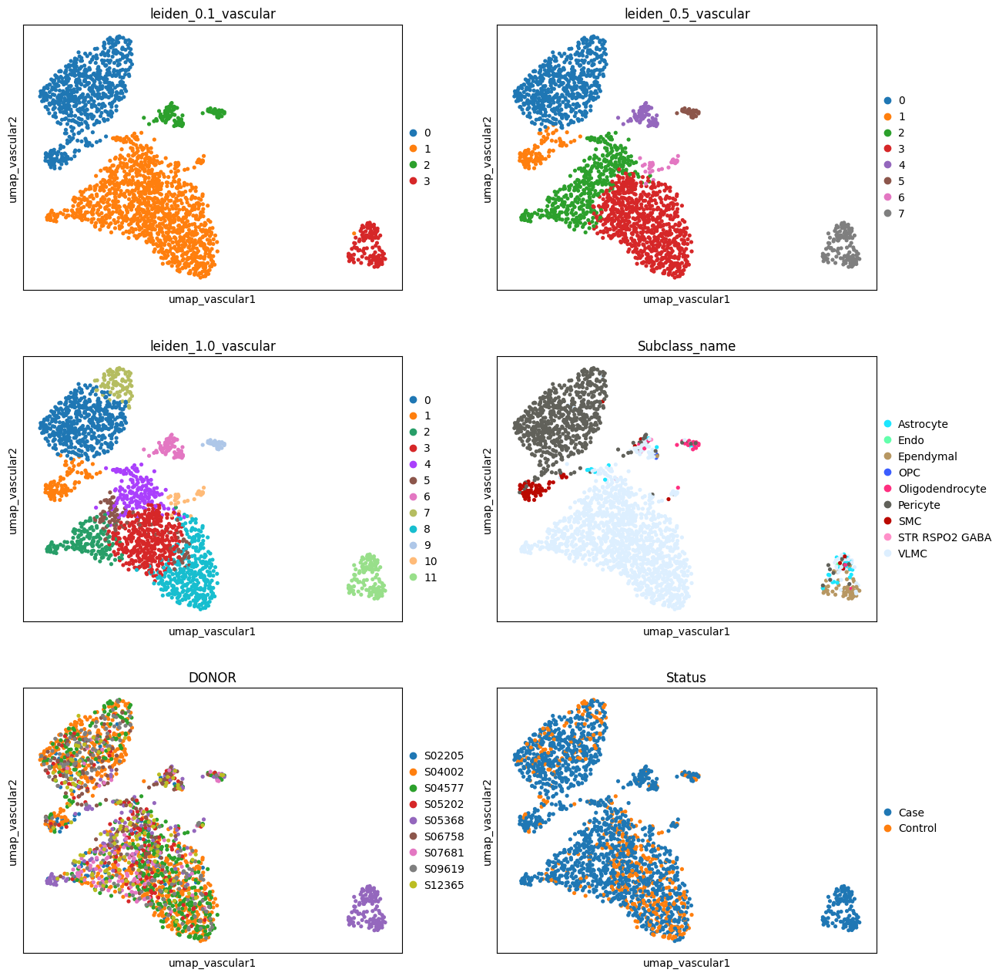

In [53]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.5, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2)

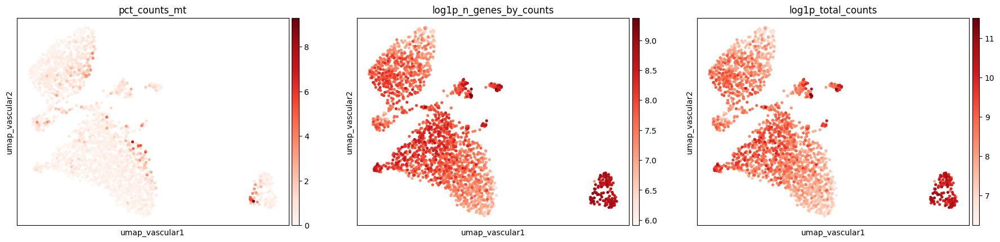

In [54]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[ "pct_counts_mt", "log1p_n_genes_by_counts", "log1p_total_counts"], cmap="Reds", legend_loc="on data")

In [55]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.5{NAME}"

In [56]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=20, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(20))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000164741,32.709839,3.805124,1.131746e-234,4.181010e-230,DLC1
1,ENSG00000113231,32.281410,4.936436,1.275626e-228,2.356273e-224,PDE8B
2,ENSG00000152894,29.971594,2.758515,2.302284e-197,2.126332e-193,PTPRK
3,ENSG00000179603,29.726995,5.198615,3.439696e-194,2.541454e-190,GRM8
4,ENSG00000171408,29.587780,3.479902,2.146126e-192,1.232834e-188,PDE7B
5,ENSG00000143248,29.584919,4.472918,2.335988e-192,1.232834e-188,RGS5
6,ENSG00000122786,29.420809,2.816315,2.975885e-190,1.374226e-186,CALD1
7,ENSG00000169507,29.282494,5.129436,1.732925e-188,7.113272e-185,SLC38A11
8,ENSG00000171862,28.951256,2.584389,2.706025e-184,9.996868e-181,PTEN
9,ENSG00000196660,28.729513,3.873975,1.633125e-181,5.484777e-178,SLC30A10


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000151067,12.434396,2.806898,1.700213e-35,1.710245e-31,CACNA1C
1,ENSG00000184347,12.427570,6.289970,1.851767e-35,1.710245e-31,SLIT3
2,ENSG00000172572,11.531672,3.763645,9.135171e-31,5.624677e-27,PDE3A
3,ENSG00000103196,11.201757,3.945319,3.997249e-29,1.640782e-25,CRISPLD2
4,ENSG00000182732,11.169252,5.400054,5.766440e-29,2.130296e-25,RGS6
5,ENSG00000154556,11.110811,3.448524,1.111456e-28,3.732774e-25,SORBS2
6,ENSG00000109452,10.587912,2.890359,3.390704e-26,8.947340e-23,INPP4B
7,ENSG00000185532,10.398426,2.109787,2.520615e-25,6.207939e-22,PRKG1
8,ENSG00000163110,10.175241,2.786726,2.557663e-24,5.558103e-21,PDLIM5
9,ENSG00000122786,9.996591,2.035032,1.577350e-23,2.913601e-20,CALD1


Cluster 2:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000215386,17.956890,1.506597,4.239010e-72,1.566018e-67,MIR99AHG
1,ENSG00000103888,17.853891,3.075573,2.695790e-71,4.979529e-67,CEMIP
2,ENSG00000187720,17.720940,2.607553,2.890412e-70,3.559350e-66,THSD4
3,ENSG00000095637,17.454216,2.040154,3.197386e-68,2.953026e-64,SORBS1
4,ENSG00000013297,16.792570,2.355045,2.766036e-63,2.043714e-59,CLDN11
5,ENSG00000172379,16.595520,2.018287,7.509092e-62,4.623473e-58,ARNT2
6,ENSG00000166147,16.169306,2.091068,8.302916e-59,4.381923e-55,FBN1
7,ENSG00000185070,16.086535,2.249351,3.170953e-58,1.464306e-54,FLRT2
8,ENSG00000189337,15.238083,1.956316,1.975843e-52,8.110395e-49,KAZN
9,ENSG00000249307,15.141265,2.189493,8.653340e-52,3.196803e-48,LINC01088


... (6 outputs left out)

Cluster 6:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000075884,7.618656,5.767113,2.563316e-14,9.469657e-10,ARHGAP15
1,ENSG00000081237,7.445065,6.448316,9.689632e-14,1.789820e-09,PTPRC
2,ENSG00000077420,7.168330,6.734942,7.591816e-13,9.348815e-09,APBB1IP
3,ENSG00000198879,6.390705,2.382107,1.651233e-10,1.525037e-06,SFMBT2
4,ENSG00000082074,6.261052,6.559043,3.823886e-10,2.825316e-06,FYB
5,ENSG00000124126,6.147534,3.384805,7.869663e-10,4.845483e-06,PREX1
6,ENSG00000183023,6.048999,2.931630,1.457489e-09,7.692000e-06,SLC8A1
7,ENSG00000135905,5.986189,2.697263,2.148143e-09,9.919854e-06,DOCK10
8,ENSG00000073849,5.885493,3.016077,3.968698e-09,1.629062e-05,ST6GAL1
9,ENSG00000120594,5.793440,2.428556,6.895927e-09,2.547562e-05,PLXDC2


Cluster 7:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000147246,18.778528,10.079468,1.131739e-78,1.075654e-74,HTR2C
1,ENSG00000148482,18.775396,9.679847,1.200471e-78,1.075654e-74,SLC39A12
2,ENSG00000113494,18.760786,8.732024,1.580476e-78,1.075654e-74,PRLR
3,ENSG00000250305,18.759592,8.101667,1.616344e-78,1.075654e-74,KIAA1456
4,ENSG00000112297,18.753628,8.455081,1.808229e-78,1.075654e-74,CRYBG1
5,ENSG00000048052,18.751093,7.095387,1.896508e-78,1.075654e-74,HDAC9
6,ENSG00000248550,18.746769,10.328020,2.057132e-78,1.075654e-74,OTX2-AS1
7,ENSG00000159212,18.733053,6.963027,2.662063e-78,1.075654e-74,CLIC6
8,ENSG00000118271,18.729921,10.885000,2.823333e-78,1.075654e-74,TTR
9,ENSG00000112394,18.728281,8.265036,2.911659e-78,1.075654e-74,SLC16A10


Assure that adata.var.index has same gene name of makers...


  0%|          | 0/15 [00:00<?, ?it/s]

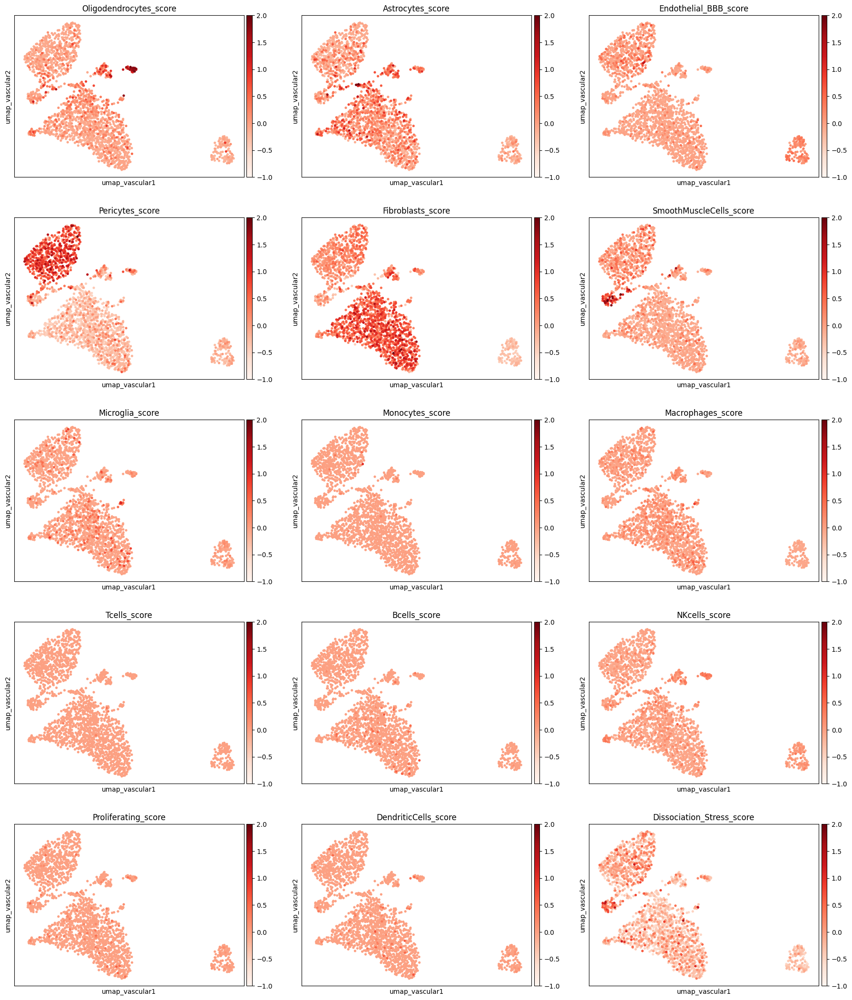

In [57]:
# gene markers score
col_scores = preprocessing.calculate_and_plot_markers(adata_nn, lmu.markers_ct, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}", vmin=-1, vmax=2)


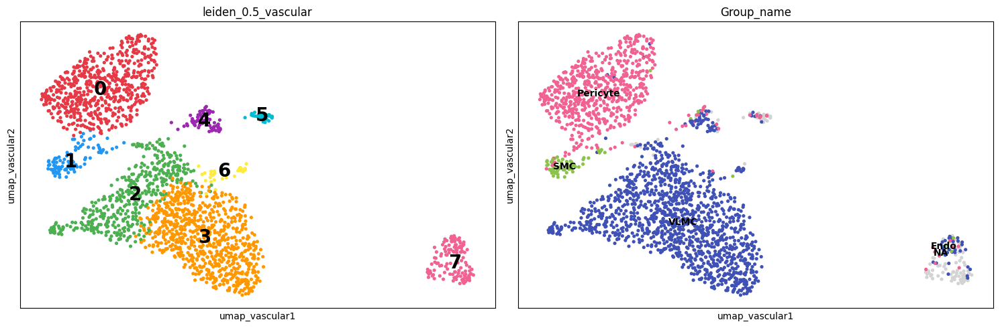

In [58]:
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Oligodendrocyte      119103
Astrocyte             49194
-Low_quality          13260
OPC                    7936
Ependymal              3626
Fibroblast             1201
Pericyte                586
COP                     167
SmoothMuscleCells        94
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


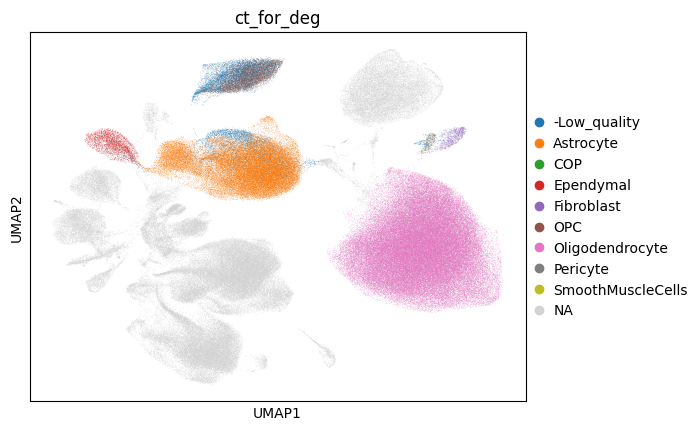

... storing 'tmp_label' as categorical


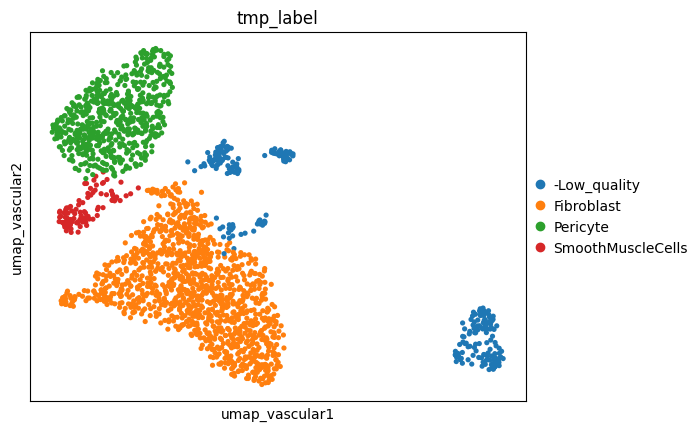

In [59]:
"""
VASCUALAR
    - Endothelial_BBB
    - Pericytes
    - Fibroblasts / VLMC
    - SmoothMuscleCells
"""

mapping_dict = {
    "0": "Pericyte",            # RGS5, PDGFRB, SLC38A11, GRM8, P2RY14
    "1": "SmoothMuscleCells",                 # CACNA1C, SLIT3, PDE3A, MCAM, CALD1
    "2": "Fibroblast",          # CEMIP, FBN1, COL11A1, THSD4, SLC7A11
    "3": "Fibroblast",          # CYP1B1, ABCA8/9/10, APOD, LAMA2 (perivascular)

    # LOW_QUALITY_LABEL: all the rest
    # 4 = neuron doublets, 5 = oligo doublets, 6 = immune doublets, 7 = choroid plexus (1 sample)
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna(LOW_QUALITY_LABEL)

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")


# Immune: Microglia + Lymphocytes

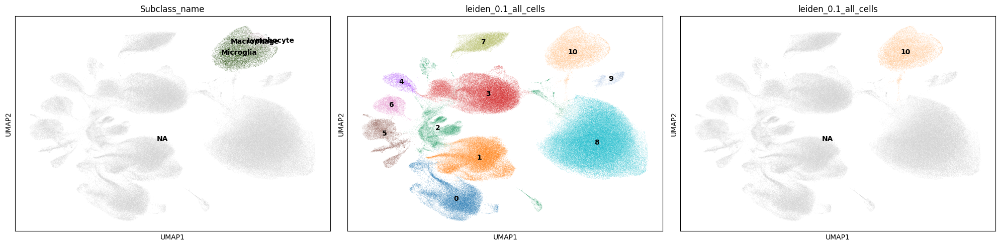

In [61]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["10"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["immune"]
NAME="_microglia"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-10-27 14:40:12,650 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 14:40:12 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 14:40:12,651 - harmonypy - INFO -   Parameters:
2026-10-27 14:40:12 | [INFO]   Parameters:
2026-10-27 14:40:12,652 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 14:40:12 | [INFO]     max_iter_harmony: 30
2026-10-27 14:40:12,653 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 14:40:12 | [INFO]     max_iter_kmeans: 20
2026-10-27 14:40:12,654 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 14:40:12 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 14:40:12,655 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 14:40:12 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 14:40:12,656 - harmonypy - INFO -     nclust: 100
2026-10-27 14:40:12 | [INFO]     nclust: 100
2026-10-27 14:40:12,657 - harmonypy - INFO -     block_size: 0.05
2026-10-27 14:40:12 | [INFO]     block_size: 0.05
2026-10-27 14:40:12,658 - harm

Running Harmony batch correction...


2026-10-27 14:40:13,520 - harmonypy - INFO - KMeans initialization complete.
2026-10-27 14:40:13 | [INFO] KMeans initialization complete.
2026-10-27 14:40:13,524 - harmonypy - INFO - Iteration 1 of 30
2026-10-27 14:40:13 | [INFO] Iteration 1 of 30
2026-10-27 14:40:13,943 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 14:40:13 | [INFO] Iteration 2 of 30
2026-10-27 14:40:14,355 - harmonypy - INFO - Iteration 3 of 30
2026-10-27 14:40:14 | [INFO] Iteration 3 of 30
2026-10-27 14:40:14,856 - harmonypy - INFO - Iteration 4 of 30
2026-10-27 14:40:14 | [INFO] Iteration 4 of 30
2026-10-27 14:40:15,409 - harmonypy - INFO - Iteration 5 of 30
2026-10-27 14:40:15 | [INFO] Iteration 5 of 30
2026-10-27 14:40:15,790 - harmonypy - INFO - Iteration 6 of 30
2026-10-27 14:40:15 | [INFO] Iteration 6 of 30
2026-10-27 14:40:16,058 - harmonypy - INFO - Iteration 7 of 30
2026-10-27 14:40:16 | [INFO] Iteration 7 of 30
2026-10-27 14:40:16,326 - harmonypy - INFO - Iteration 8 of 30
2026-10-27 14:40:16 | [INFO] 

Z_corr shape: (20867, 50), n_obs: 20867
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


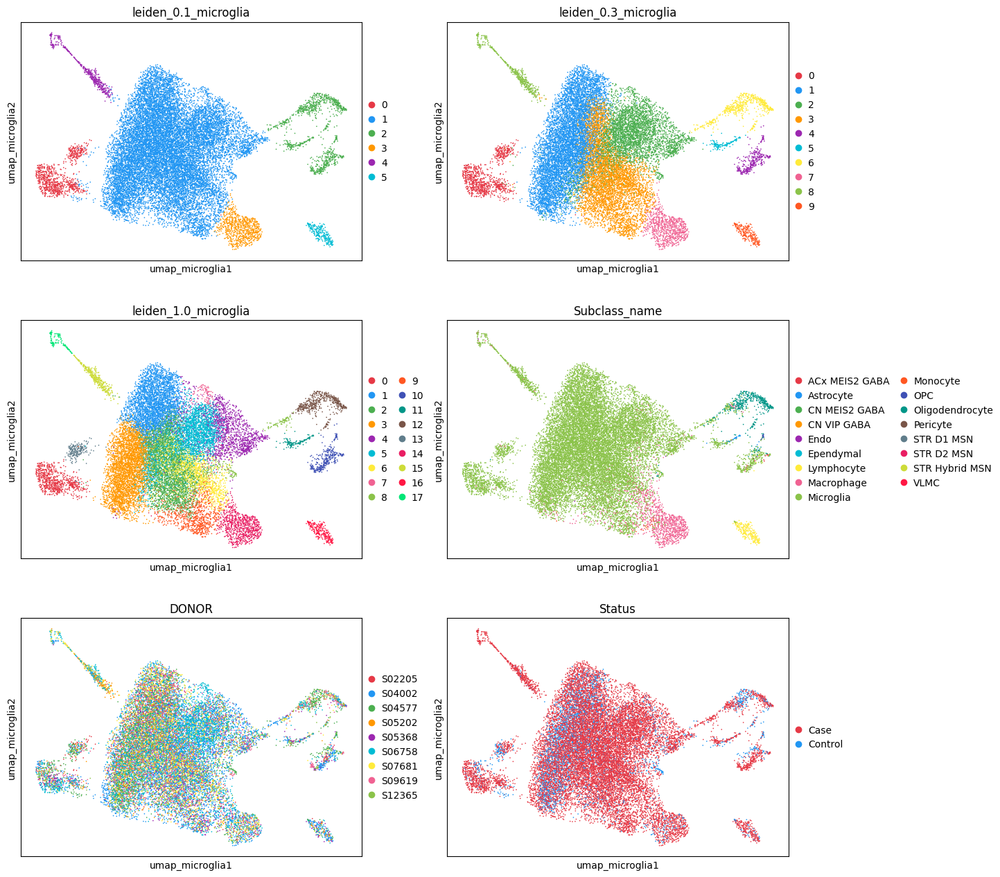

In [62]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2, palette=preprocessing.custom_palette)

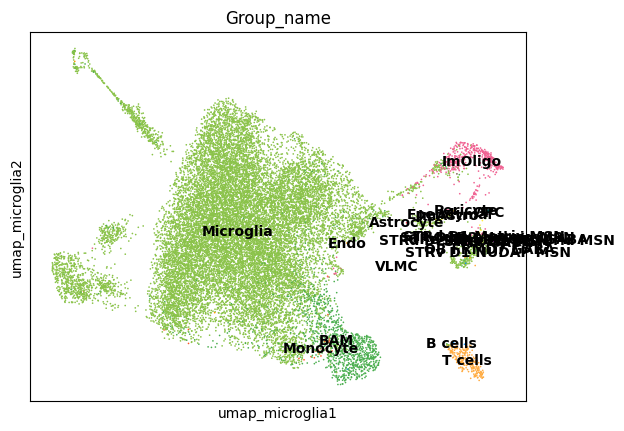

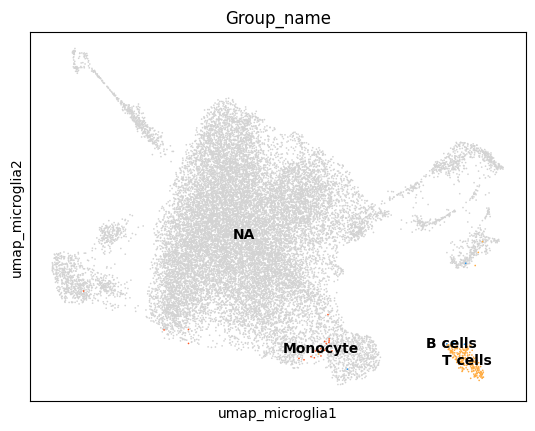

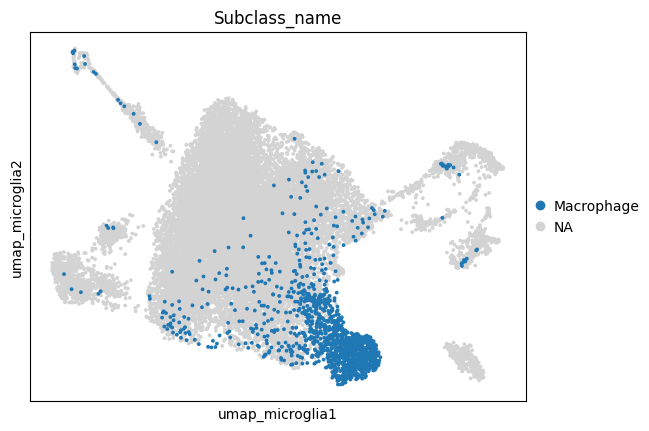

In [63]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], ncols=2, palette=preprocessing.custom_palette, legend_loc="on data")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], groups=["T cells", "Monocyte", "B cells", "Macrophage"], ncols=2, palette=preprocessing.custom_palette, legend_loc="on data")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Subclass_name"], groups=["Macrophage"], ncols=2, palette=["#1f77b4"], size=30)

Assure that adata.var.index has same gene name of makers...


  0%|          | 0/15 [00:00<?, ?it/s]

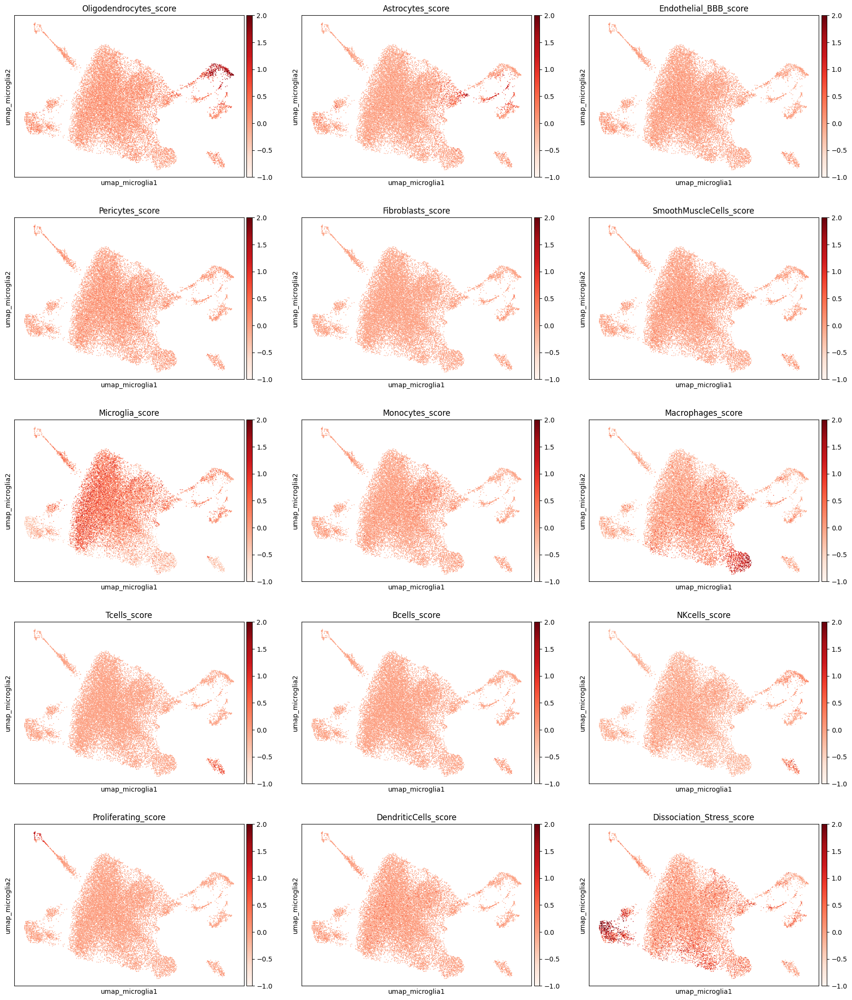

In [64]:
# gene markers score
col_scores = preprocessing.calculate_and_plot_markers(adata_nn, lmu.markers_ct, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}", vmin=-1, vmax=2)


In [65]:
# Decide the mapping lvel
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_1.0{NAME}"

In [66]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=20, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(20))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000258667,34.376427,4.482500,5.675748e-259,2.096792e-254,HIF1A-AS2
1,ENSG00000100644,34.103264,3.562171,6.598573e-255,1.218855e-250,HIF1A
2,ENSG00000122862,33.745132,3.857183,1.260035e-249,1.551649e-245,SRGN
3,ENSG00000245532,32.042145,1.363189,2.824283e-225,2.608438e-221,NEAT1
4,ENSG00000122884,30.212841,2.938024,1.606399e-200,1.186904e-196,P4HA1
5,ENSG00000090104,29.901215,3.395583,1.897496e-196,1.168320e-192,RGS1
6,ENSG00000059804,28.766201,4.110657,5.681116e-182,2.998249e-178,SLC2A3
7,ENSG00000251562,27.919132,0.922843,1.563107e-171,7.218235e-168,MALAT1
8,ENSG00000112149,26.909492,4.997836,1.700596e-159,6.980569e-156,CD83
9,ENSG00000120063,26.792545,2.903179,3.946795e-158,1.458065e-154,GNA13


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000067798,43.128891,1.472184,0.000000e+00,0.000000e+00,NAV3
1,ENSG00000146090,38.222637,1.961156,0.000000e+00,0.000000e+00,RASGEF1C
2,ENSG00000169313,37.965199,1.435168,0.000000e+00,0.000000e+00,P2RY12
3,ENSG00000171914,34.588543,1.304153,3.756538e-262,3.469444e-258,TLN2
4,ENSG00000182601,33.280605,1.428702,7.367813e-243,5.443782e-239,HS3ST4
5,ENSG00000101463,32.225334,1.396492,7.797394e-228,4.115130e-224,SYNDIG1
6,ENSG00000074706,31.944504,1.170665,6.440528e-224,2.974156e-220,IPCEF1
7,ENSG00000184005,31.698364,1.138479,1.636435e-220,6.717201e-217,ST6GALNAC3
8,ENSG00000151474,31.287333,0.771972,6.939335e-215,2.563598e-211,FRMD4A
9,ENSG00000249738,29.550463,1.856222,6.477693e-192,2.175504e-188,AC008691.1


Cluster 5:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000137818,48.655334,2.338546,0.000000e+00,0.000000e+00,RPLP1
1,ENSG00000142937,44.887524,2.415588,0.000000e+00,0.000000e+00,RPS8
2,ENSG00000197756,44.393932,2.329493,0.000000e+00,0.000000e+00,RPL37A
3,ENSG00000177954,44.163891,2.595727,0.000000e+00,0.000000e+00,RPS27
4,ENSG00000087086,44.115524,1.829698,0.000000e+00,0.000000e+00,FTL
5,ENSG00000142676,43.096409,2.441559,0.000000e+00,0.000000e+00,RPL11
6,ENSG00000138326,41.417355,2.072377,0.000000e+00,0.000000e+00,RPS24
7,ENSG00000177600,41.127228,2.317533,0.000000e+00,0.000000e+00,RPLP2
8,ENSG00000108298,40.770935,2.792240,0.000000e+00,0.000000e+00,RPL19
9,ENSG00000144713,40.631454,2.667402,0.000000e+00,0.000000e+00,RPL32


... (26 outputs left out)

Cluster 17:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000187951,14.837095,5.684866,8.432868e-50,3.115354e-45,ARHGAP11B
1,ENSG00000106462,14.451244,4.976770,2.461968e-47,4.547625e-43,EZH2
2,ENSG00000156970,14.346221,7.958148,1.125029e-46,1.385399e-42,BUB1B
3,ENSG00000139734,14.193695,8.220052,1.002349e-45,9.257445e-42,DIAPH3
4,ENSG00000109685,13.912027,3.766023,5.353986e-44,3.955846e-40,NSD2
5,ENSG00000165304,13.830963,7.249671,1.657859e-43,9.415058e-40,MELK
6,ENSG00000137812,13.825688,7.353819,1.783976e-43,9.415058e-40,KNL1
7,ENSG00000227598,13.750792,4.915366,5.037536e-43,2.326271e-39,Z94721.1
8,ENSG00000122483,13.732084,3.284519,6.522960e-43,2.677530e-39,CCDC18
9,ENSG00000261008,13.566905,4.714934,6.292295e-42,2.324563e-38,LINC01572


Cluster 7:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000258667,14.451812,4.062532,2.441771e-47,9.020636e-43,HIF1A-AS2
1,ENSG00000114480,10.627332,2.858647,2.223843e-26,2.781819e-22,GBE1
2,ENSG00000102144,10.625868,2.541250,2.259009e-26,2.781819e-22,PGK1
3,ENSG00000122884,10.129024,1.932926,4.107302e-24,3.793402e-20,P4HA1
4,ENSG00000104765,9.988432,2.505998,1.712693e-23,1.265440e-19,BNIP3L
5,ENSG00000167996,9.969944,2.670148,2.063447e-23,1.270498e-19,FTH1
6,ENSG00000054611,9.825960,1.277247,8.704082e-23,4.593642e-19,TBC1D22A
7,ENSG00000163872,9.730608,2.268683,2.232538e-22,1.030958e-18,YEATS2
8,ENSG00000171729,9.627030,2.518724,6.148078e-22,2.523649e-18,TMEM51
9,ENSG00000111640,9.578367,3.235097,9.859124e-22,3.642256e-18,GAPDH


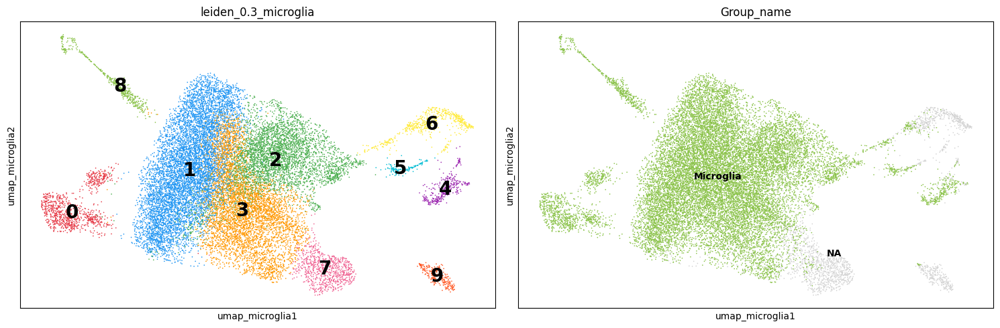

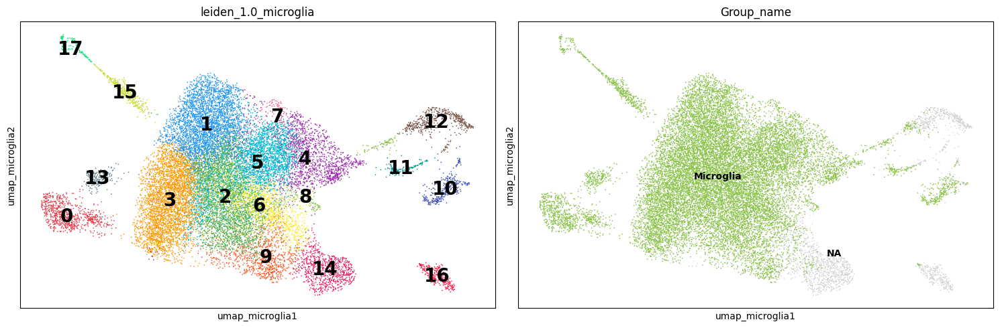

In [67]:
lmu.plot_to_decide(adata_nn, NAME, f"leiden_0.3{NAME}", GROUP_LABELS)
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Oligodendrocyte         119103
Astrocyte                49194
-Low_quality             18843
Microglia                12763
OPC                       7936
Ependymal                 3626
Fibroblast                1201
-Activated_Microglia       990
Macrophages                801
Pericyte                   586
-Cycling_Microglia         488
Tcells                     242
COP                        167
SmoothMuscleCells           94
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


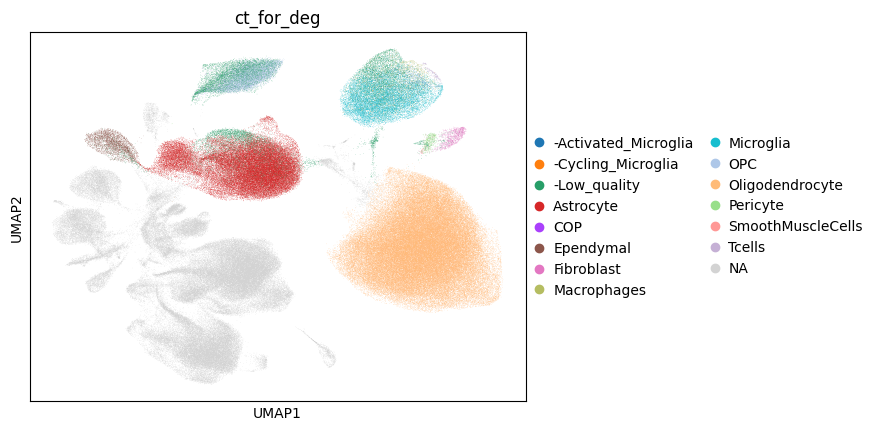

... storing 'tmp_label' as categorical


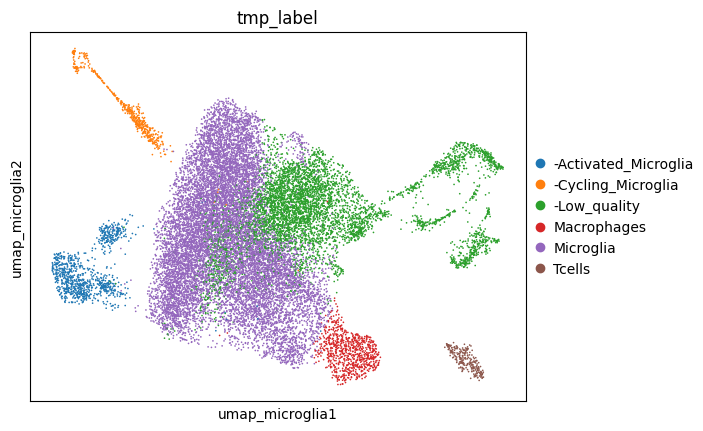

In [69]:
# map clusters to yout ct
mapping_dict = {

    "14": "Macrophages",
    "16": "Tcells",
    #"6": "Bcells",


    "1": "-Activated_Microglia",
    "13": "-Activated_Microglia",
    "11": "-Activated_Microglia",
    "16": "-Cycling_Microglia", # CENPP (centormere)


    "10": LOW_QUALITY_LABEL,  # mito
    "11": LOW_QUALITY_LABEL,  # mito
    "12": LOW_QUALITY_LABEL, #ribo
    "0": LOW_QUALITY_LABEL, #ribo
    "12": LOW_QUALITY_LABEL, #neruons LSAMP
    "15": LOW_QUALITY_LABEL, #oligo
    "17": LOW_QUALITY_LABEL, #neurons LSAMP, SLC1A2



    # Microglia all the rest
}



mapping_dict = {
    "1":  "Microglia",   # homeostatic (P2RY12, CX3CR1, NAV3, FOXP2)
    "2":  "Microglia",   # homeostatic, low logFC (FOXP1, ADAM28, LRRK2)
    "3":  "Microglia",   # generic, very low logFC (FRMD4A, P2RY12, MEF2C, C3)
    "6":  "Microglia",   # phagocytic/lipid (MERTK, MITF, CD163, CPM, ASAH1)
    "9":  "Microglia",   # CD163+ / BAM-like transitional (CD163, F13A1, RGS1, CEBPD)
    "7":  "Microglia",   # hypoxia/glycolysis (HIF1A-AS2, PGK1, BNIP3L, HK2, GAPDH)

    "13": "-Activated_Microglia",   # inflammatory (CCL3, CCL4, CD83, EGR3, NFKBID, HLA-DRA)
    "0":  "-Activated_Microglia",   # hypoxia/activated (HIF1A, SLC2A3, NAMPT, CD83, PFKFB3)

    "15": "-Cycling_Microglia",   # cycling, S phase (HELLS, CLSPN, BRCA1)
    "17": "-Cycling_Microglia",   # cycling, G2/M (MKI67, BUB1B, NUSAP1)

    "14": "Macrophages",
    "16": "Tcells",

    # LOW_QUALITY_LABEL: all the rest
    # 4  = mito + ribosomal (MT-CO2, MT-RNR2, FTL, CST3)
    # 5  = ribosomal (RPLP1, RPS8, RPL37A, TPT1)
    # 8  = oligo doublets (ST18, SLC44A1, TMEM144, CTNNA3)
    # 10 = neuron doublets (SNHG14, NRXN3, DPP6, CTNNA2, LRRC7)
    # 11 = astro doublets (SLC1A2, GPM6A, NRG3, NPAS3)
    # 12 = oligo doublets (ST18, IL1RAPL1, SLC24A2, EDIL3)
    # 16 = T cells (THEMIS, SKAP1, CD96, STAT4, IKZF3)
}


adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna(LOW_QUALITY_LABEL)

# Add to orignla ct
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")


# Non-MSN Neurons

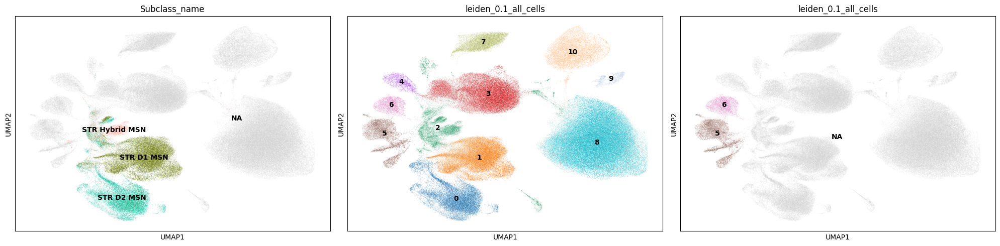

In [73]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["6", "5"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["MSN"]
NAME="_neuroms"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-10-27 14:50:10,996 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 14:50:10 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 14:50:10,998 - harmonypy - INFO -   Parameters:
2026-10-27 14:50:10 | [INFO]   Parameters:
2026-10-27 14:50:11,000 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 14:50:11 | [INFO]     max_iter_harmony: 30
2026-10-27 14:50:11,002 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 14:50:11 | [INFO]     max_iter_kmeans: 20
2026-10-27 14:50:11,003 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 14:50:11 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 14:50:11,005 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 14:50:11 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 14:50:11,006 - harmonypy - INFO -     nclust: 100
2026-10-27 14:50:11 | [INFO]     nclust: 100
2026-10-27 14:50:11,008 - harmonypy - INFO -     block_size: 0.05
2026-10-27 14:50:11 | [INFO]     block_size: 0.05
2026-10-27 14:50:11,010 - harm

Running Harmony batch correction...


2026-10-27 14:50:11,711 - harmonypy - INFO - KMeans initialization complete.
2026-10-27 14:50:11 | [INFO] KMeans initialization complete.
2026-10-27 14:50:11,717 - harmonypy - INFO - Iteration 1 of 30
2026-10-27 14:50:11 | [INFO] Iteration 1 of 30
2026-10-27 14:50:12,251 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 14:50:12 | [INFO] Iteration 2 of 30
2026-10-27 14:50:12,703 - harmonypy - INFO - Iteration 3 of 30
2026-10-27 14:50:12 | [INFO] Iteration 3 of 30
2026-10-27 14:50:13,118 - harmonypy - INFO - Iteration 4 of 30
2026-10-27 14:50:13 | [INFO] Iteration 4 of 30
2026-10-27 14:50:13,592 - harmonypy - INFO - Iteration 5 of 30
2026-10-27 14:50:13 | [INFO] Iteration 5 of 30
2026-10-27 14:50:14,003 - harmonypy - INFO - Iteration 6 of 30
2026-10-27 14:50:14 | [INFO] Iteration 6 of 30
2026-10-27 14:50:14,221 - harmonypy - INFO - Iteration 7 of 30
2026-10-27 14:50:14 | [INFO] Iteration 7 of 30
2026-10-27 14:50:14,427 - harmonypy - INFO - Iteration 8 of 30
2026-10-27 14:50:14 | [INFO] 

Z_corr shape: (17264, 50), n_obs: 17264
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


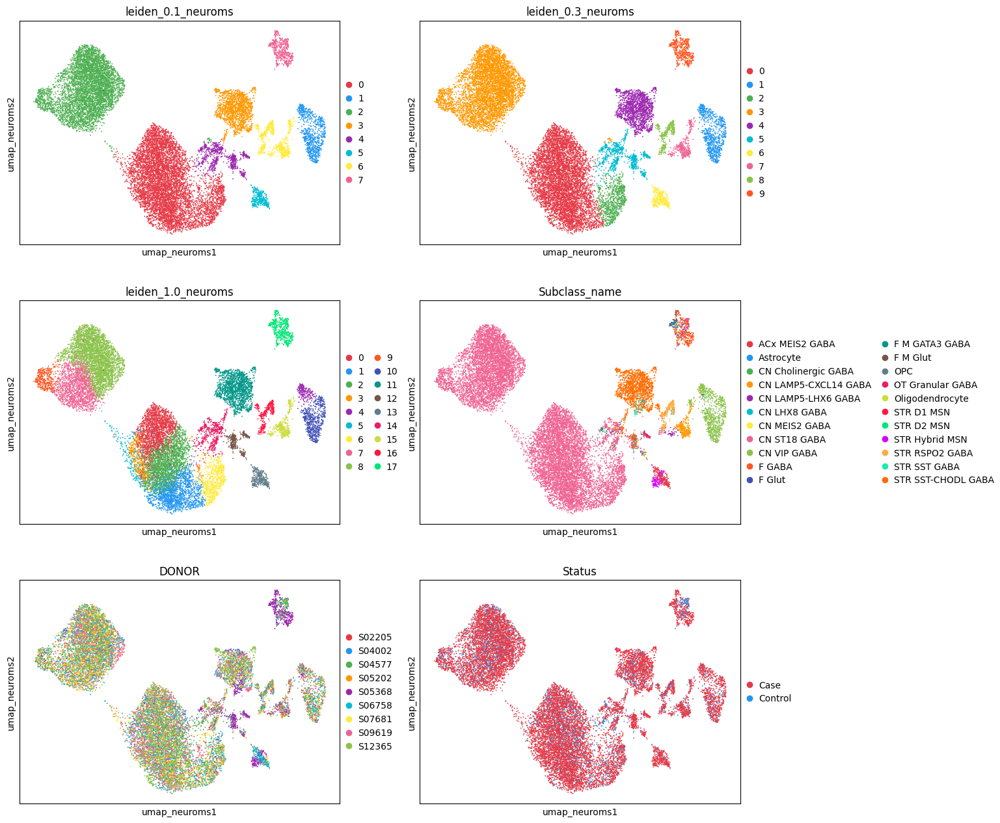

In [74]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2, palette=preprocessing.custom_palette)


Assure that adata.var.index has same gene name of makers...


  0%|          | 0/15 [00:00<?, ?it/s]

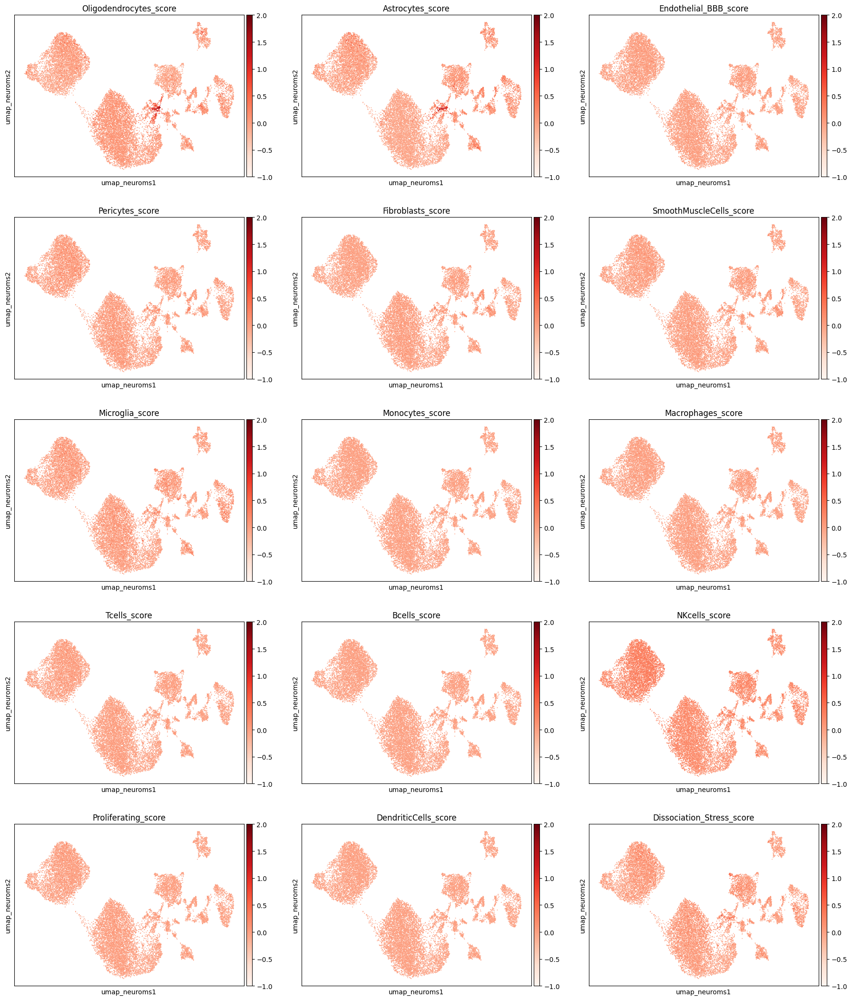

In [75]:
# gene markers score
col_scores = preprocessing.calculate_and_plot_markers(adata_nn, lmu.markers_ct, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}", vmin=-1, vmax=2)


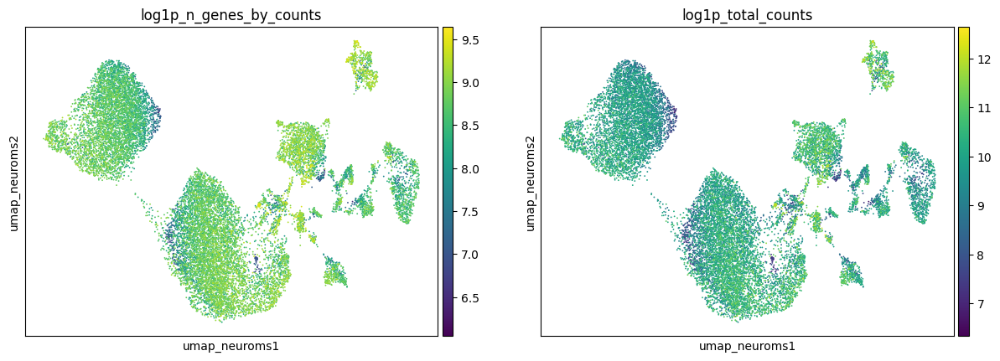

In [76]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["log1p_n_genes_by_counts", "log1p_total_counts"], legend_loc="on data")

In [77]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.1{NAME}"

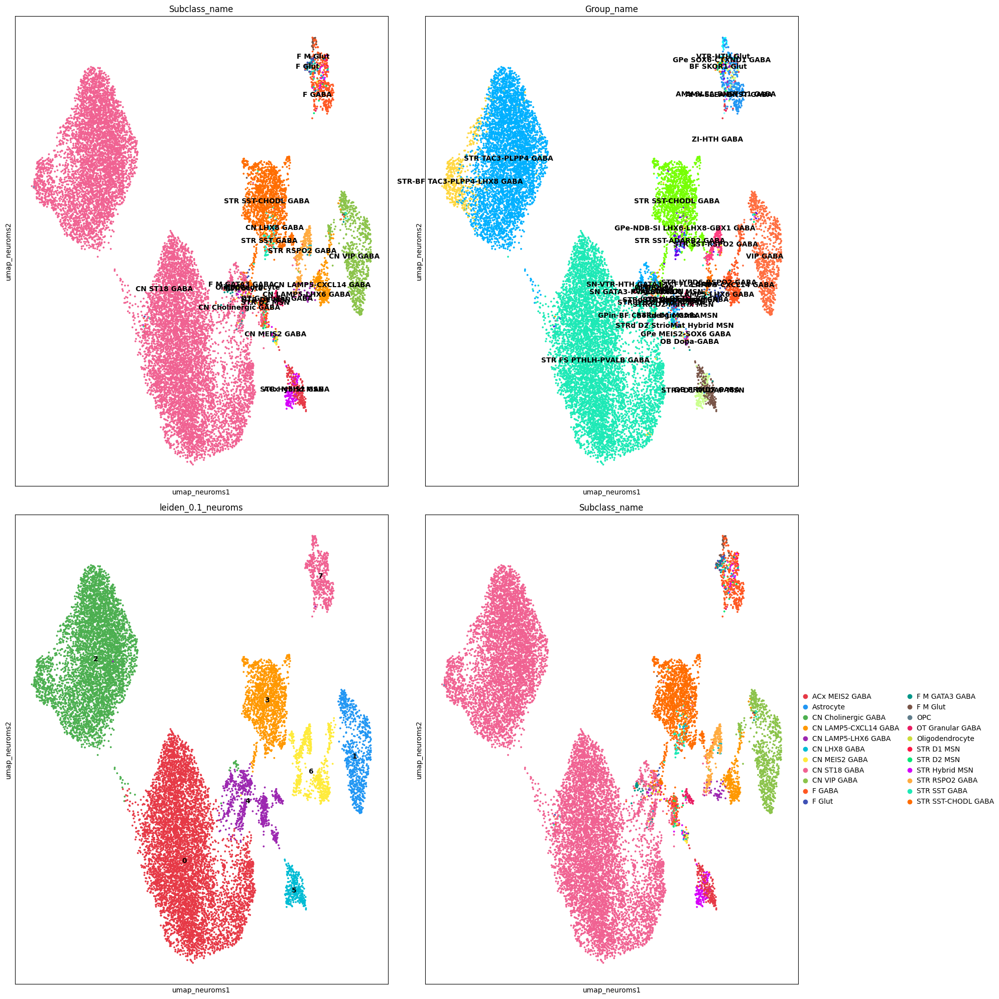

In [78]:
fig, axes = plt.subplots(2, 2, figsize=(20, 20))
axes = axes.flatten()
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Subclass_name"], legend_loc="on data", ax=axes[0], show=False, size=30, palette=lmu.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], legend_loc="on data", ax=axes[1], show=False, size=30, palette=lmu.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[ADATA_NN_LEIDEN_COL_FOR_MAPPING], legend_loc="on data", ax=axes[2], show=False, size=30, palette=lmu.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Subclass_name"], ax=axes[3], show=False, size=30, palette=lmu.custom_palette)
plt.tight_layout(); plt.show()

In [86]:
adata_nn.obs[adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING] == "6"]["Group_name"].value_counts()

Group_name
LAMP5-CXCL14 GABA                 267
STR SST-RSPO2 GABA                180
STR LYPD6-RSPO2 GABA               72
VIP GABA                           46
LAMP5-LHX6 GABA                    44
STR SST-CHODL GABA                 35
STR FS PTHLH-PVALB GABA            12
GPe-NDB-SI LHX6-LHX8-GBX1 GABA      4
STR SST-ADARB2 GABA                 2
STR-BF TAC3-PLPP4-LHX8 GABA         2
AMY-SLEA-BNST GABA                  1
SN-VTR-HTH GATA3-TCF7L2 GABA        1
BF SKOR1 Glut                       1
OB Dopa-GABA                        1
GPe MEIS2-SOX6 GABA                 0
AMY-SLEA-BNST D1 GABA               0
Astrocyte                           0
OB FRMD7 GABA                       0
GPe SOX6-CTXND1 GABA                0
ImOligo                             0
GPin-BF Cholinergic GABA            0
STR D1D2 Hybrid MSN                 0
STR Cholinergic GABA                0
Oligo OPALIN                        0
SN GATA3-PVALB GABA                 0
OT D1 ICj                           0
O

### Final decision

ALL non-msn

remove oligo_cotamination

ct_for_deg
Oligodendrocyte            119103
Astrocyte                   49194
-Low_quality                19574
Microglia                   12763
OPC                          7936
STR FS PTHLH-PVALB GABA      7233
STR TAC3 GABA                5424
Ependymal                    3626
STR SST-CHODL GABA           1547
Fibroblast                   1201
-Activated_Microglia          990
non-MSN                       852
VIP GABA                      809
Macrophages                   801
STR RSPO2 GABA                668
Pericyte                      586
-Cycling_Microglia            488
Tcells                        242
COP                           167
SmoothMuscleCells              94
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


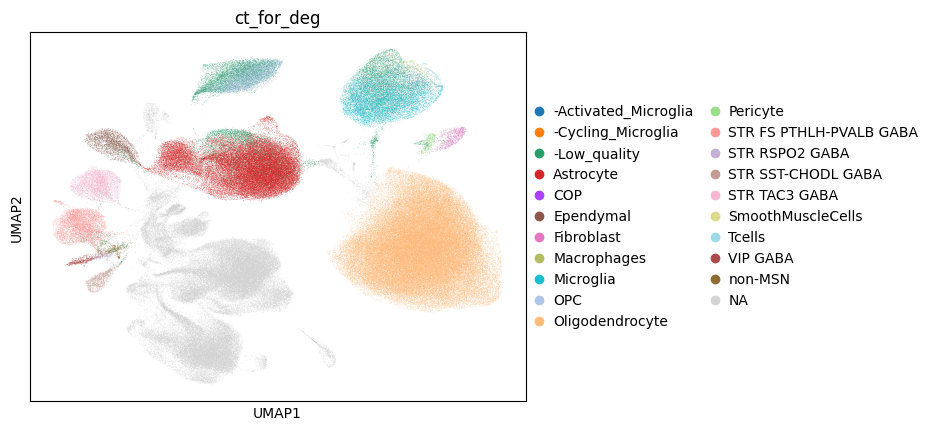

... storing 'tmp_label' as categorical


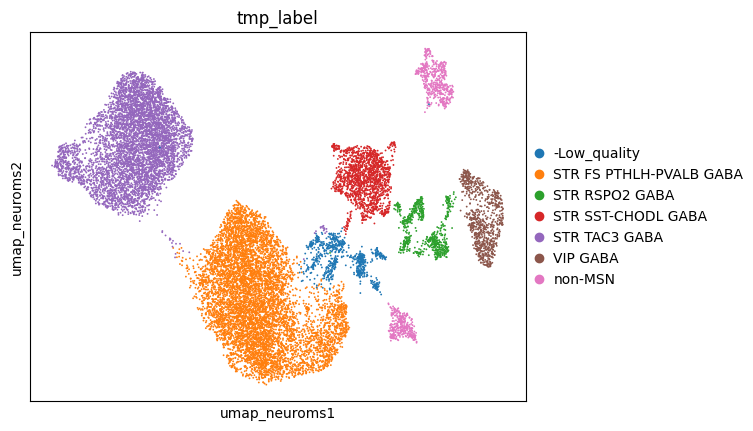

In [87]:
# map clusters to yout ct
mapping_dict = {
 
    "4": LOW_QUALITY_LABEL, 


    #"3": "Cholinergic GABA",# subclass lsveel
    "1": "VIP GABA",  #group lsveel
    #"7": "LAMP5 GABA", # 2 merged
    "3": "STR SST-CHODL GABA", # subclass lsveel
    "6": "STR RSPO2 GABA", # subclass lsveel
    "0": "STR FS PTHLH-PVALB GABA", #GORUP
    "2": "STR TAC3 GABA", #MERGED: grup
    #"5": "ACx MEIS2 GABA" #subclass


    # MSN all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("non-MSN")

# Add to orignla ct
if "ct_for_deg" not in adata.obs.columns:
    adata.obs["ct_for_deg"] = np.nan
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

In [ ]:
del adata_nn

# MSN hybrdids and Cholinergic

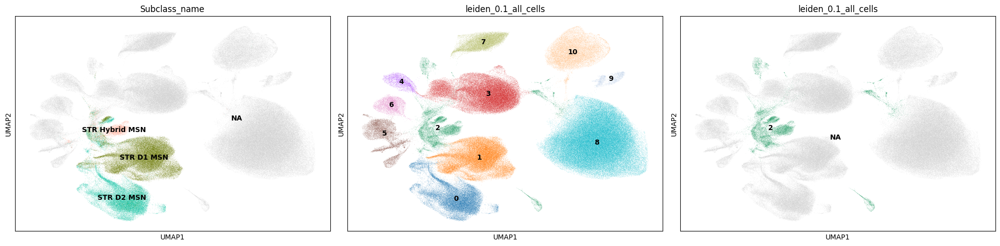

In [100]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["2"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["MSN"]
NAME="_MSN"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-10-27 15:51:27,420 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 15:51:27 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 15:51:27,421 - harmonypy - INFO -   Parameters:
2026-10-27 15:51:27 | [INFO]   Parameters:
2026-10-27 15:51:27,422 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 15:51:27 | [INFO]     max_iter_harmony: 30
2026-10-27 15:51:27,423 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 15:51:27 | [INFO]     max_iter_kmeans: 20
2026-10-27 15:51:27,424 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 15:51:27 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 15:51:27,424 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 15:51:27 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 15:51:27,425 - harmonypy - INFO -     nclust: 100
2026-10-27 15:51:27 | [INFO]     nclust: 100
2026-10-27 15:51:27,426 - harmonypy - INFO -     block_size: 0.05
2026-10-27 15:51:27 | [INFO]     block_size: 0.05
2026-10-27 15:51:27,427 - harm

Running Harmony batch correction...


2026-10-27 15:51:28,205 - harmonypy - INFO - KMeans initialization complete.
2026-10-27 15:51:28 | [INFO] KMeans initialization complete.
2026-10-27 15:51:28,210 - harmonypy - INFO - Iteration 1 of 30
2026-10-27 15:51:28 | [INFO] Iteration 1 of 30
2026-10-27 15:51:28,625 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 15:51:28 | [INFO] Iteration 2 of 30
2026-10-27 15:51:29,177 - harmonypy - INFO - Iteration 3 of 30
2026-10-27 15:51:29 | [INFO] Iteration 3 of 30
2026-10-27 15:51:29,677 - harmonypy - INFO - Iteration 4 of 30
2026-10-27 15:51:29 | [INFO] Iteration 4 of 30
2026-10-27 15:51:30,229 - harmonypy - INFO - Iteration 5 of 30
2026-10-27 15:51:30 | [INFO] Iteration 5 of 30
2026-10-27 15:51:30,756 - harmonypy - INFO - Converged after 5 iterations
2026-10-27 15:51:30 | [INFO] Converged after 5 iterations


Z_corr shape: (17771, 50), n_obs: 17771
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


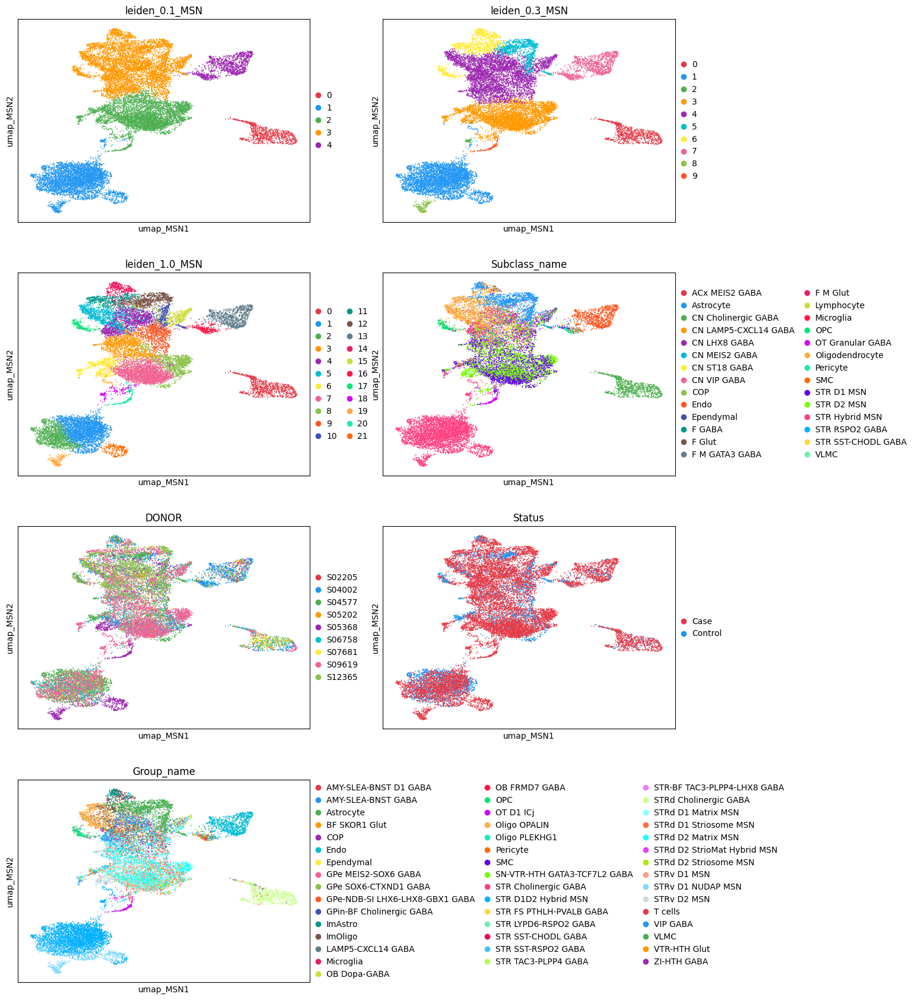

In [101]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE, "Group_name"], ncols=2, palette=preprocessing.custom_palette)



... storing 'MSN_type' as categorical


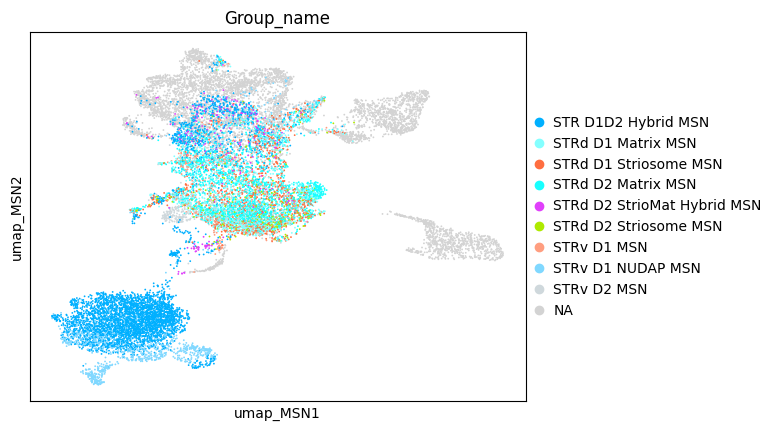

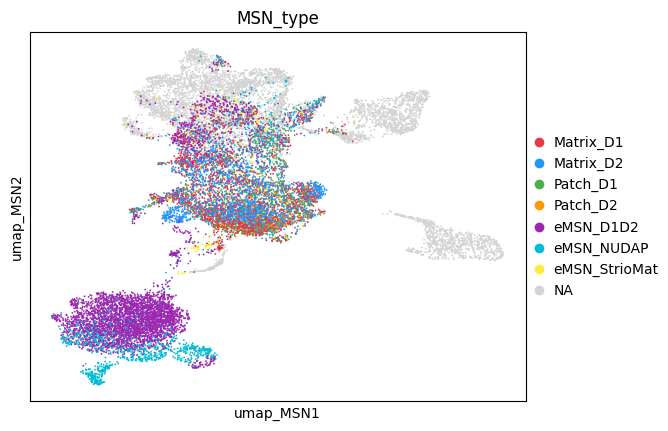

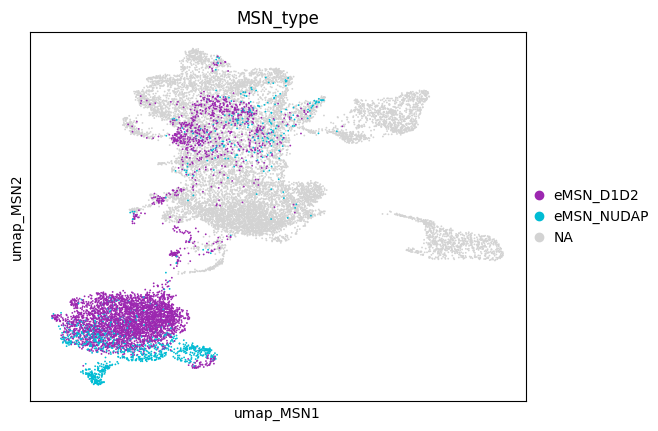

In [108]:
# map Group-name to broader categories
mapping_msn = {
    "STRd D1 Matrix MSN": "Matrix_D1",
    "STRd D2 Matrix MSN": "Matrix_D2",
    "STRv D1 MSN": "Matrix_D1",
    "STRv D2 MSN": "Matrix_D2",

    "STRd D2 Striosome MSN": "Patch_D2",
    "STRd D1 Striosome MSN": "Patch_D1",

    "STRd D2 StrioMat Hybrid MSN": "eMSN_StrioMat",
    "STR D1D2 Hybrid MSN": "eMSN_D1D2",
    "STRv D1 NUDAP MSN": "eMSN_NUDAP"
  }
adata_nn.obs["MSN_type"] = adata_nn.obs["Group_name"].map(mapping_msn)

ct_to_color = list(mapping_msn.keys())
ct_to_color

sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], groups=ct_to_color, ncols=2, palette=preprocessing.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["MSN_type"], ncols=2, palette=preprocessing.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["MSN_type"], ncols=2, palette=preprocessing.custom_palette, groups=["eMSN_D1D2", "eMSN_NUDAP"])



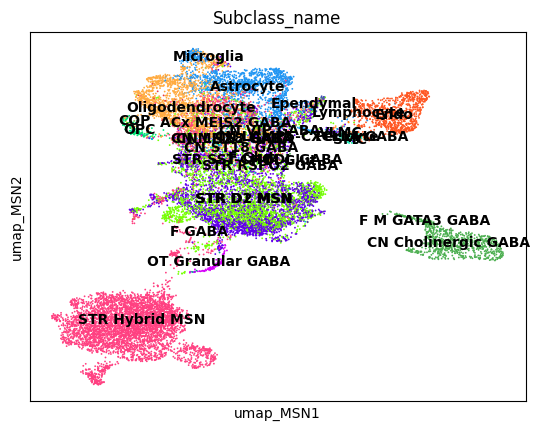

In [114]:
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Subclass_name"], ncols=2, palette=preprocessing.custom_palette, legend_loc="on data")


Assure that adata.var.index has same gene name of makers...


  0%|          | 0/1 [00:00<?, ?it/s]

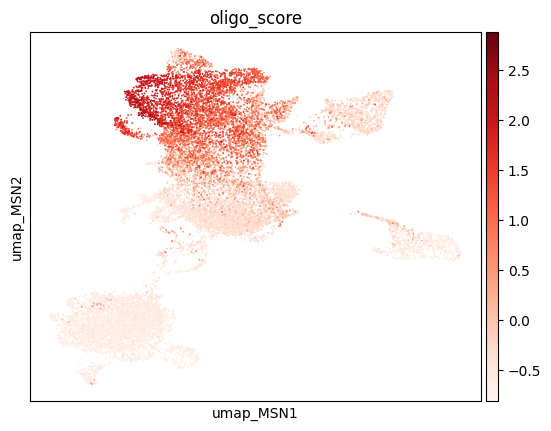

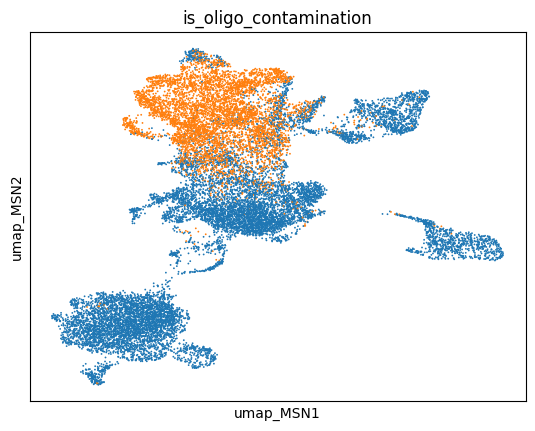

In [ ]:
# Check if they are ooligos contamiantion
dict_oligo={"oligo": ["MBP", 'PLP1', 'MOBP', 'TMEM144', "MOG"]}
col_oligo_score = preprocessing.calculate_and_plot_markers(adata_nn, dict_oligo, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}")
adata_nn.obs["is_oligo_contamination"] = (adata_nn.obs[col_oligo_score[0]] >= 0.25).fillna(0).astype(bool)
#adata_nn.obs[col_oligo_score[0]].plot(kind="hist", bins=100)
sc.pl.embedding(adata_nn, color="is_oligo_contamination", basis=f"umap{NAME}", ncols=5, legend_loc=None)



sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"], legend_loc="on data", ncols=2)


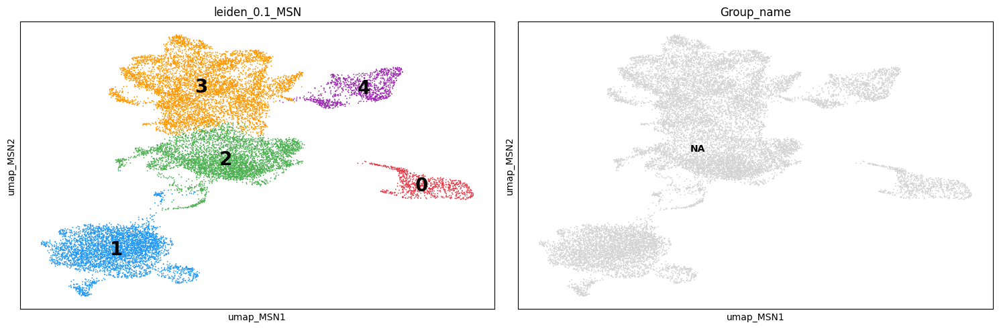

In [106]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = "leiden_0.1_MSN"
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

In [107]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=50, markers=None,
                                             #groups=["12", "14"]
                                             )

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(30))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000158258,47.903111,7.413375,0.0,0.0,CLSTN2
1,ENSG00000138741,47.534641,8.786939,0.0,0.0,TRPC3
2,ENSG00000187672,47.257282,5.176548,0.0,0.0,ERC2
3,ENSG00000168702,46.859245,3.319329,0.0,0.0,LRP1B
4,ENSG00000163618,46.737488,3.607710,0.0,0.0,CADPS
5,ENSG00000137968,46.620255,6.147255,0.0,0.0,SLC44A5
6,ENSG00000109452,46.589016,4.376094,0.0,0.0,INPP4B
7,ENSG00000151952,46.157253,4.669830,0.0,0.0,TMEM132D
8,ENSG00000115665,46.092422,9.272566,0.0,0.0,SLC5A7
9,ENSG00000204442,46.011139,3.636667,0.0,0.0,FAM155A


Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000174473,97.698677,4.828622,0.0,0.0,GALNTL6
1,ENSG00000128573,97.447815,4.953501,0.0,0.0,FOXP2
2,ENSG00000187398,97.330185,5.340450,0.0,0.0,LUZP2
3,ENSG00000157168,95.686630,4.059492,0.0,0.0,NRG1
4,ENSG00000072657,95.502457,5.487880,0.0,0.0,TRHDE
5,ENSG00000185736,95.063782,4.462972,0.0,0.0,ADARB2
6,ENSG00000149972,94.163811,4.732870,0.0,0.0,CNTN5
7,ENSG00000196376,93.846886,3.910630,0.0,0.0,SLC35F1
8,ENSG00000279877,93.199265,4.421402,0.0,0.0,AC009135.2
9,ENSG00000182348,90.827690,5.144314,0.0,0.0,ZNF804B


Cluster 3:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000184226,98.924072,3.760626,0.0,0.0,PCDH9
1,ENSG00000112531,94.309227,3.307115,0.0,0.0,QKI
2,ENSG00000123560,93.656853,6.111835,0.0,0.0,PLP1
3,ENSG00000151322,92.440475,2.779613,0.0,0.0,NPAS3
4,ENSG00000101542,91.239349,5.775424,0.0,0.0,CDH20
5,ENSG00000176771,91.087166,4.794994,0.0,0.0,NCKAP5
6,ENSG00000147488,89.585205,5.698921,0.0,0.0,ST18
7,ENSG00000197971,89.152901,5.203690,0.0,0.0,MBP
8,ENSG00000169554,86.469696,4.983897,0.0,0.0,ZEB2
9,ENSG00000079215,86.327698,5.228611,0.0,0.0,SLC1A3


Cluster 2:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000185008,60.812374,2.256609,0.000000e+00,0.000000e+00,ROBO2
1,ENSG00000183780,58.205078,2.375822,0.000000e+00,0.000000e+00,SLC35F3
2,ENSG00000147246,58.097149,2.756933,0.000000e+00,0.000000e+00,HTR2C
3,ENSG00000172264,48.694508,1.307123,0.000000e+00,0.000000e+00,MACROD2
4,ENSG00000185760,47.738270,1.607157,0.000000e+00,0.000000e+00,KCNQ5
5,ENSG00000166501,47.072021,1.611298,0.000000e+00,0.000000e+00,PRKCB
6,ENSG00000187323,46.240807,1.513218,0.000000e+00,0.000000e+00,DCC
7,ENSG00000168959,44.456890,1.436428,0.000000e+00,0.000000e+00,GRM5
8,ENSG00000183117,42.191071,1.155046,0.000000e+00,0.000000e+00,CSMD1
9,ENSG00000185046,41.782196,0.890239,0.000000e+00,0.000000e+00,ANKS1B


Cluster 4:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000102755,52.304268,9.054407,0.0,0.0,FLT1
1,ENSG00000206190,51.071678,8.209173,0.0,0.0,ATP10A
2,ENSG00000085276,50.328053,9.085549,0.0,0.0,MECOM
3,ENSG00000116016,50.059574,7.354236,0.0,0.0,EPAS1
4,ENSG00000164181,49.846531,5.988329,0.0,0.0,ELOVL7
5,ENSG00000110799,49.520527,8.186238,0.0,0.0,VWF
6,ENSG00000085563,49.161316,6.149946,0.0,0.0,ABCB1
7,ENSG00000184005,49.094360,4.366915,0.0,0.0,ST6GALNAC3
8,ENSG00000082438,48.404243,7.828727,0.0,0.0,COBLL1
9,ENSG00000184113,47.906021,8.511593,0.0,0.0,CLDN5


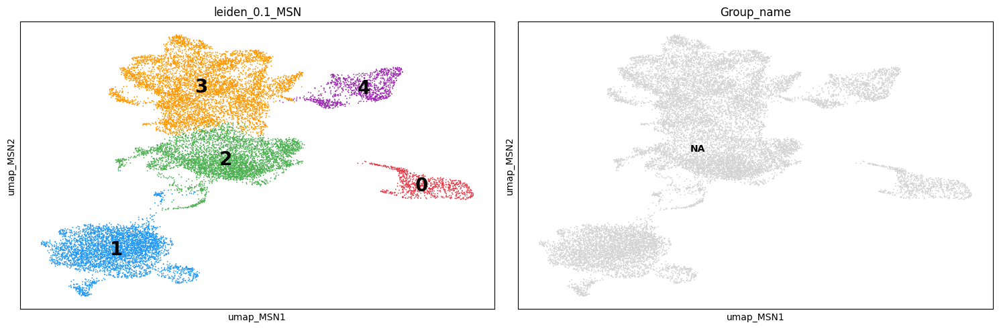

In [109]:
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Oligodendrocyte            119103
Astrocyte                   49194
-Low_quality                30929
Microglia                   12763
OPC                          7936
STR FS PTHLH-PVALB GABA      7233
STR TAC3 GABA                5424
Ependymal                    3626
eMSN_D1D2                    3480
STR SST-CHODL GABA           1547
Fibroblast                   1201
Endothelial_BBB              1143
-Activated_Microglia          990
eMSN_NUDAP                    951
non-MSN                       852
Cholinergic GABA              842
VIP GABA                      809
Macrophages                   801
STR RSPO2 GABA                668
Pericyte                      586
-Cycling_Microglia            488
Tcells                        242
COP                           167
SmoothMuscleCells              94
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


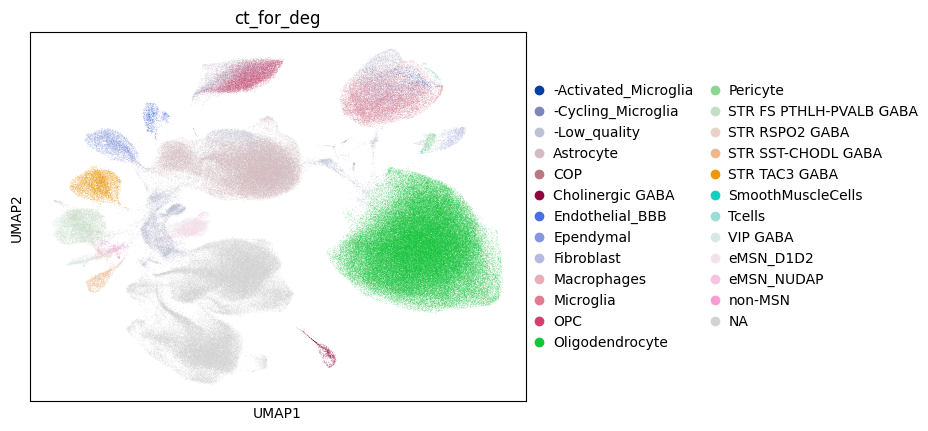

... storing 'tmp_label' as categorical


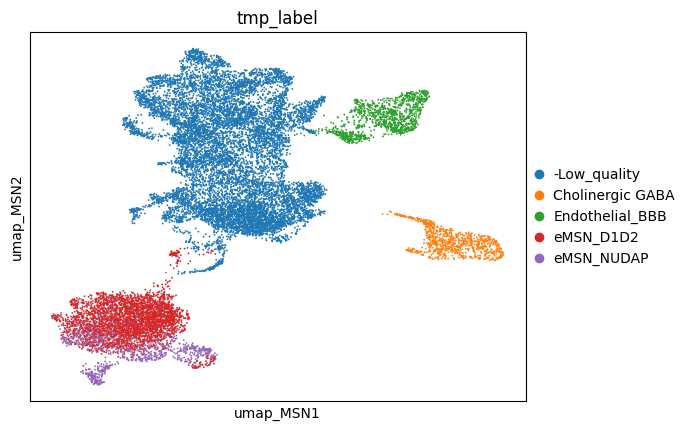

In [117]:
# map clusters to yout ct
mapping_dict = {

    "4": "Endothelial_BBB",


    "0": "Cholinergic GABA", 


    "2": LOW_QUALITY_LABEL, 
    "3": LOW_QUALITY_LABEL, 

    # Microglia all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna(adata_nn.obs["MSN_type"])

# Add to orignla ct
if "ct_for_deg" not in adata.obs.columns:
    adata.obs["ct_for_deg"] = np.nan
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")


# MSN

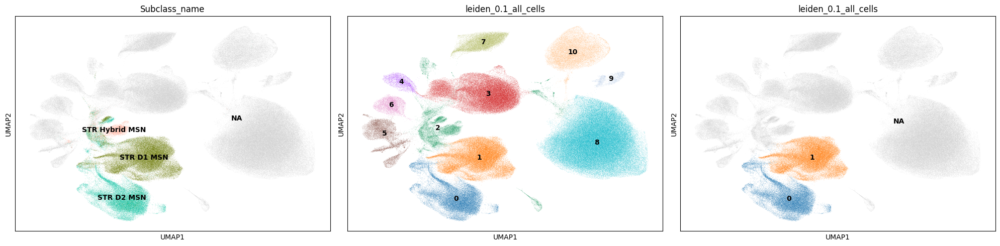

In [118]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["0", "1"]
MMC_ANNOTATION_LEVEL = "Subclass_name"
GROUP_LABELS = lmu.subclass_cell_types_mapping["MSN"]
NAME="_MSN"

lmu.plot_to_select(adata, GROUP_LABELS, CLUSTERS_ALL_CELLS_COL, CLUSTERS_GROUP_ALL_CELLS)

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-10-27 16:04:12,388 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-27 16:04:12 | [INFO] Running Harmony (PyTorch on cuda)
2026-10-27 16:04:12,389 - harmonypy - INFO -   Parameters:
2026-10-27 16:04:12 | [INFO]   Parameters:
2026-10-27 16:04:12,390 - harmonypy - INFO -     max_iter_harmony: 30
2026-10-27 16:04:12 | [INFO]     max_iter_harmony: 30
2026-10-27 16:04:12,391 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-27 16:04:12 | [INFO]     max_iter_kmeans: 20
2026-10-27 16:04:12,392 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-27 16:04:12 | [INFO]     epsilon_cluster: 1e-05
2026-10-27 16:04:12,392 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-27 16:04:12 | [INFO]     epsilon_harmony: 0.0001
2026-10-27 16:04:12,393 - harmonypy - INFO -     nclust: 100
2026-10-27 16:04:12 | [INFO]     nclust: 100
2026-10-27 16:04:12,394 - harmonypy - INFO -     block_size: 0.05
2026-10-27 16:04:12 | [INFO]     block_size: 0.05
2026-10-27 16:04:12,395 - harm

Running Harmony batch correction...


2026-10-27 16:04:15,274 - harmonypy - INFO - KMeans initialization complete.
2026-10-27 16:04:15 | [INFO] KMeans initialization complete.
2026-10-27 16:04:15,283 - harmonypy - INFO - Iteration 1 of 30
2026-10-27 16:04:15 | [INFO] Iteration 1 of 30
2026-10-27 16:04:15,828 - harmonypy - INFO - Iteration 2 of 30
2026-10-27 16:04:15 | [INFO] Iteration 2 of 30
2026-10-27 16:04:16,435 - harmonypy - INFO - Iteration 3 of 30
2026-10-27 16:04:16 | [INFO] Iteration 3 of 30
2026-10-27 16:04:17,018 - harmonypy - INFO - Iteration 4 of 30
2026-10-27 16:04:17 | [INFO] Iteration 4 of 30
2026-10-27 16:04:17,520 - harmonypy - INFO - Iteration 5 of 30
2026-10-27 16:04:17 | [INFO] Iteration 5 of 30
2026-10-27 16:04:18,086 - harmonypy - INFO - Iteration 6 of 30
2026-10-27 16:04:18 | [INFO] Iteration 6 of 30
2026-10-27 16:04:18,631 - harmonypy - INFO - Iteration 7 of 30
2026-10-27 16:04:18 | [INFO] Iteration 7 of 30
2026-10-27 16:04:19,054 - harmonypy - INFO - Iteration 8 of 30
2026-10-27 16:04:19 | [INFO] 

Z_corr shape: (78722, 50), n_obs: 78722
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


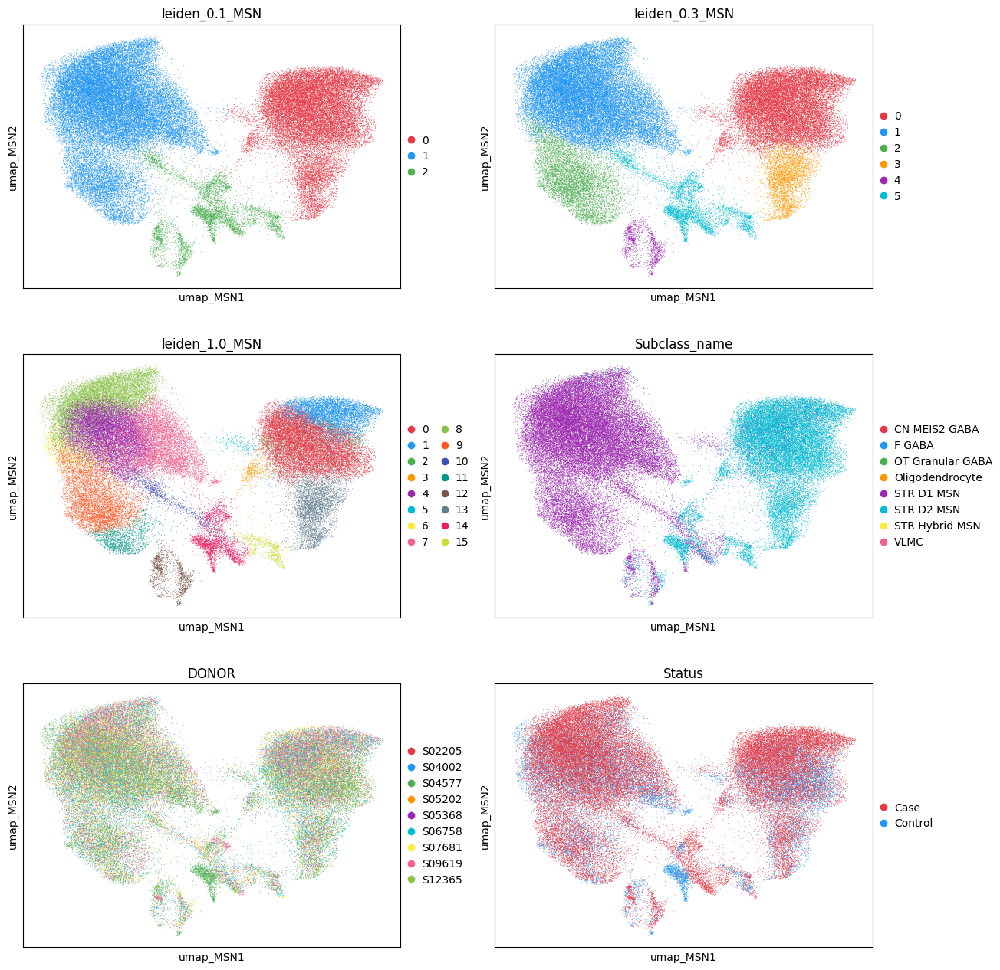

In [119]:
# Select clear nn clusters (use cluster created using all cells)
adata_nn = adata[adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS)].copy()

# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, MMC_ANNOTATION_LEVEL, SAMPLE_VARIABLE, CONDITION_VARIABLE], ncols=2, palette=preprocessing.custom_palette)


... storing 'MSN_type' as categorical


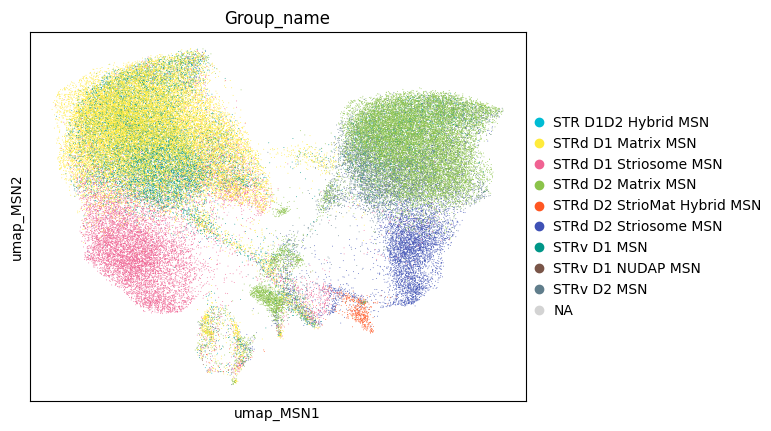

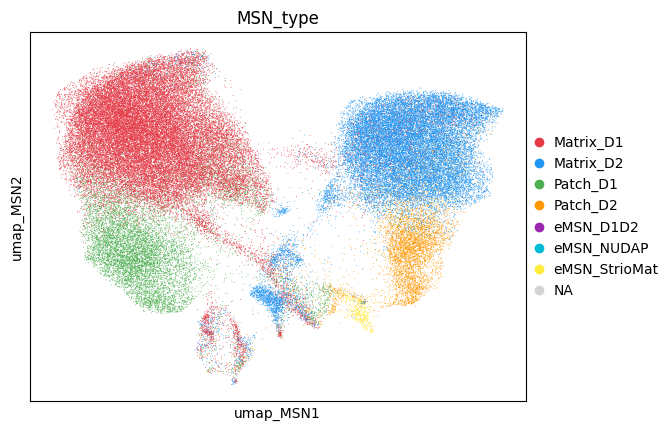

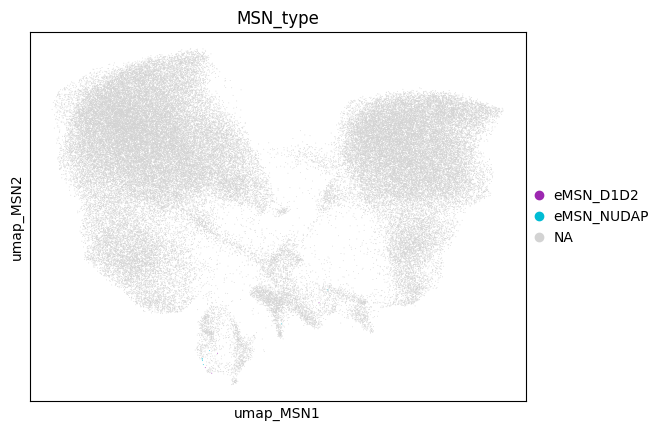

In [120]:
# map Group-name to broader categories
mapping_msn = {
    "STRd D1 Matrix MSN": "Matrix_D1",
    "STRd D2 Matrix MSN": "Matrix_D2",
    "STRv D1 MSN": "Matrix_D1",
    "STRv D2 MSN": "Matrix_D2",

    "STRd D2 Striosome MSN": "Patch_D2",
    "STRd D1 Striosome MSN": "Patch_D1",

    "STRd D2 StrioMat Hybrid MSN": "eMSN_StrioMat",
    "STR D1D2 Hybrid MSN": "eMSN_D1D2",
    "STRv D1 NUDAP MSN": "eMSN_NUDAP"
  }
adata_nn.obs["MSN_type"] = adata_nn.obs["Group_name"].map(mapping_msn)

ct_to_color = list(mapping_msn.keys())
ct_to_color

sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], groups=ct_to_color, ncols=2, palette=preprocessing.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["MSN_type"], ncols=2, palette=preprocessing.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["MSN_type"], ncols=2, palette=preprocessing.custom_palette, groups=["eMSN_D1D2", "eMSN_NUDAP"])



Assure that adata.var.index has same gene name of makers...


  0%|          | 0/1 [00:00<?, ?it/s]

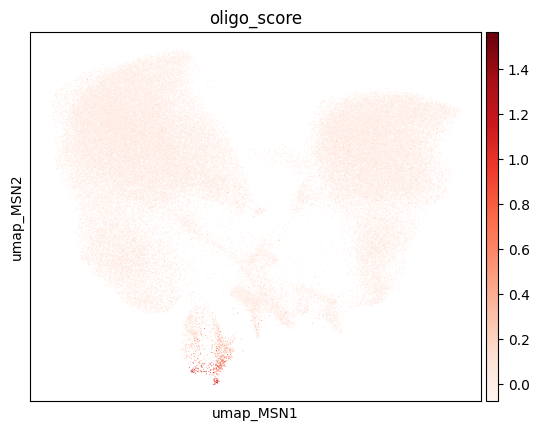

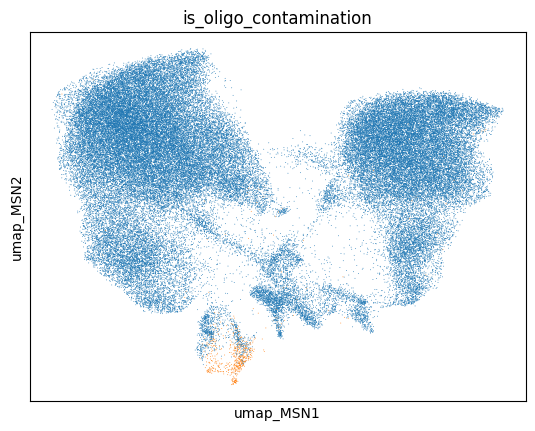

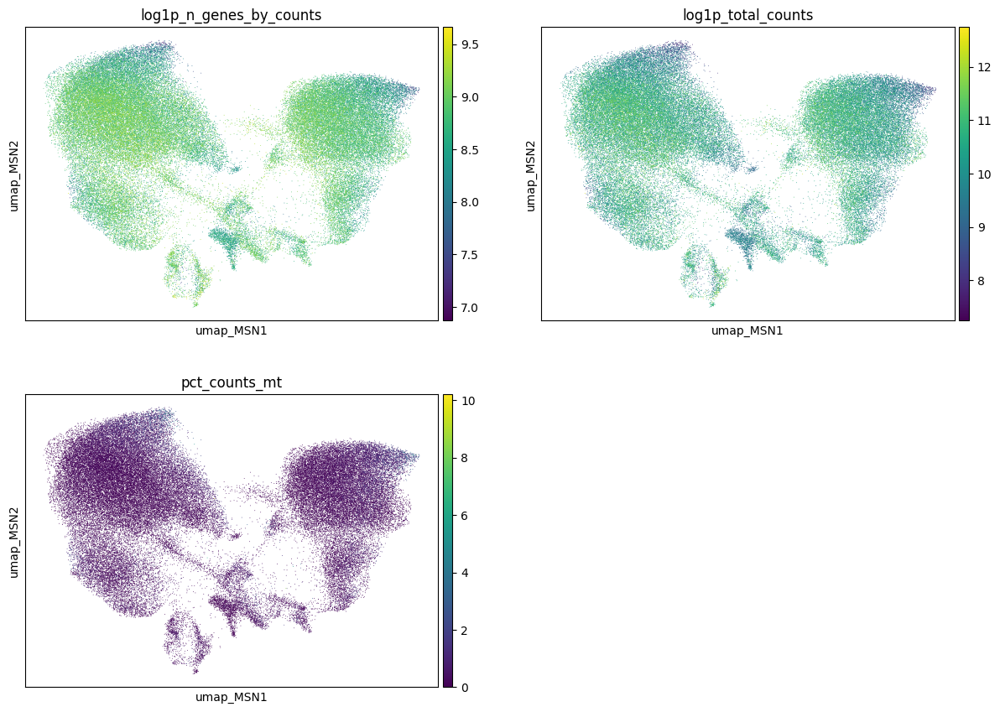

In [121]:
# Check if they are ooligos contamiantion
dict_oligo={"oligo": ["MBP", 'PLP1', 'MOBP', 'TMEM144', "MOG"]}
col_oligo_score = preprocessing.calculate_and_plot_markers(adata_nn, dict_oligo, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}")
adata_nn.obs["is_oligo_contamination"] = (adata_nn.obs[col_oligo_score[0]] >= 0.25).fillna(0).astype(bool)
#adata_nn.obs[col_oligo_score[0]].plot(kind="hist", bins=100)
sc.pl.embedding(adata_nn, color="is_oligo_contamination", basis=f"umap{NAME}", ncols=5, legend_loc=None)



sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"], legend_loc="on data", ncols=2)


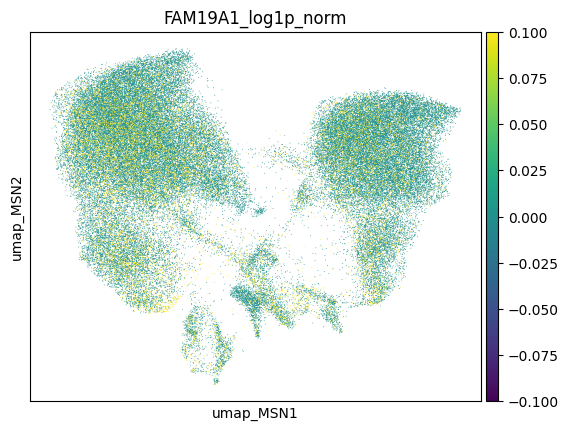

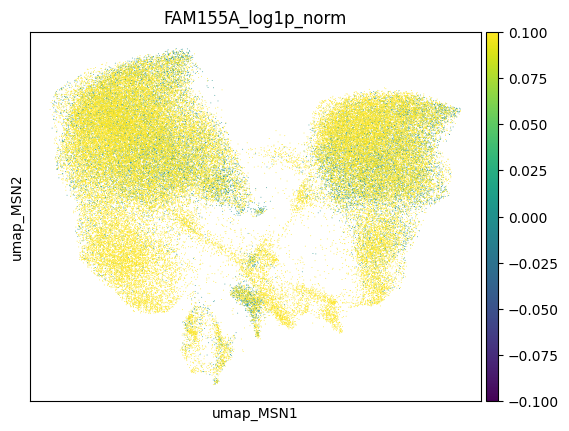

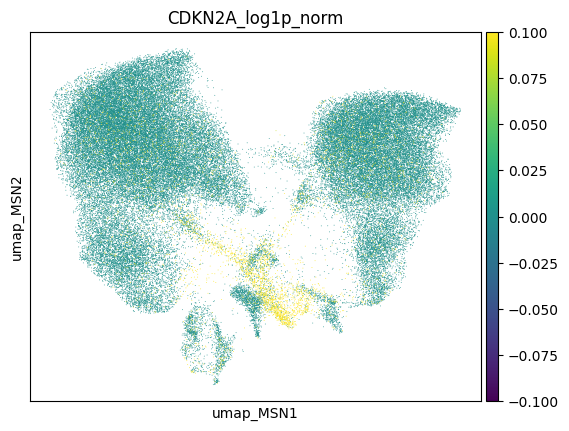

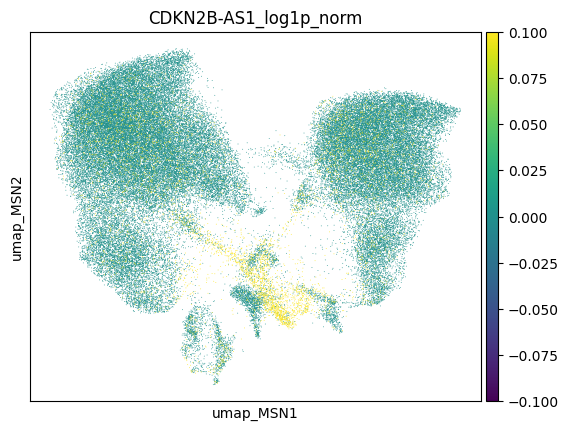

In [122]:
# TAFA1

for gene in ["FAM19A1", "FAM155A", "CDKN2A", "CDKN2B-AS1"]: 
    idx_tafa1 = adata_nn.var.index.get_indexer(adata_nn.var.query(f"gene_symbol == '{gene}'").index)
    adata_nn.obs[f"{gene}_log1p_norm"] = adata_nn.layers["log1p_norm"][:, idx_tafa1].toarray().ravel()
    sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[f"{gene}_log1p_norm"], ncols=2, vmax=np.quantile(adata_nn.obs[f"{gene}_log1p_norm"].values, 0.2))
    plt.show()

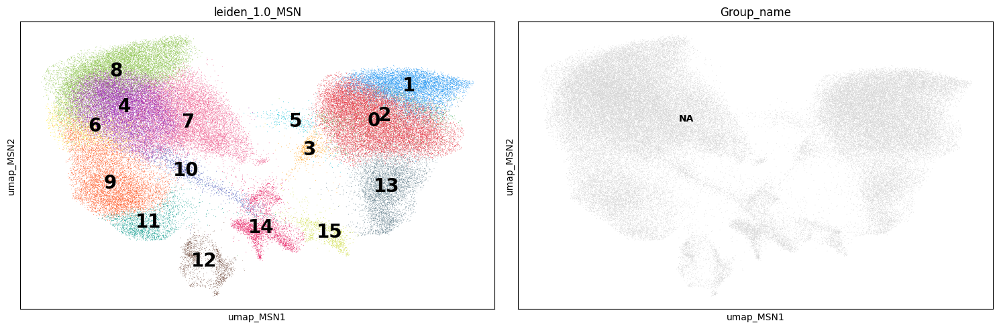

In [123]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = "leiden_1.0_MSN"
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

In [124]:
# Wilcoxon
res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=50, markers=None,
                                             #groups=["12", "14"]
                                             )

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(30))

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000133019,136.332993,2.591559,0.0,0.0,CHRM3
1,ENSG00000149295,134.614288,2.446048,0.0,0.0,DRD2
2,ENSG00000112367,133.311920,1.673494,0.0,0.0,FIG4
3,ENSG00000152061,131.568192,0.932042,0.0,0.0,RABGAP1L
4,ENSG00000236922,124.817116,2.267668,0.0,0.0,LINC01378
5,ENSG00000152818,121.382141,1.439908,0.0,0.0,UTRN
6,ENSG00000173482,120.013924,1.496885,0.0,0.0,PTPRM
7,ENSG00000181195,117.955078,2.099657,0.0,0.0,PENK
8,ENSG00000164100,111.818115,0.925757,0.0,0.0,NDST3
9,ENSG00000113448,100.336258,0.747173,0.0,0.0,PDE4D


Cluster 4:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000185352,101.164963,0.970066,0.0,0.0,HS6ST3
1,ENSG00000154529,89.739433,1.309169,0.0,0.0,CNTNAP3B
2,ENSG00000145416,89.530869,0.691673,0.0,0.0,MARCH1
3,ENSG00000171587,89.491631,0.955619,0.0,0.0,DSCAM
4,ENSG00000147481,79.541313,0.390663,0.0,0.0,SNTG1
5,ENSG00000106714,75.807564,0.874627,0.0,0.0,CNTNAP3
6,ENSG00000204754,75.015991,1.264595,0.0,0.0,LINC01951
7,ENSG00000164330,73.608124,1.274353,0.0,0.0,EBF1
8,ENSG00000241956,70.974266,0.607259,0.0,0.0,AC109466.1
9,ENSG00000152910,66.490173,0.991720,0.0,0.0,CNTNAP4


Cluster 11:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000139304,62.757561,3.854281,0.0,0.0,PTPRQ
1,ENSG00000149972,60.795670,2.954184,0.0,0.0,CNTN5
2,ENSG00000145526,58.416676,1.962174,0.0,0.0,CDH18
3,ENSG00000131773,58.211262,2.648381,0.0,0.0,KHDRBS3
4,ENSG00000151789,57.400093,2.609964,0.0,0.0,ZNF385D
5,ENSG00000183098,57.292183,1.840138,0.0,0.0,GPC6
6,ENSG00000112182,56.708759,2.914132,0.0,0.0,BACH2
7,ENSG00000128573,55.661133,2.165874,0.0,0.0,FOXP2
8,ENSG00000182132,55.387966,2.520805,0.0,0.0,KCNIP1
9,ENSG00000189056,55.160858,1.913710,0.0,0.0,RELN


... (22 outputs left out)

Cluster 5:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000181195,13.464036,0.997989,2.546181e-41,9.406355e-37,PENK
1,ENSG00000136267,11.483964,0.351743,1.588277e-30,2.933786e-26,DGKB
2,ENSG00000176771,11.134522,0.792900,8.520061e-29,1.049189e-24,NCKAP5
3,ENSG00000185046,10.784418,0.259480,4.078154e-27,3.766481e-23,ANKS1B
4,ENSG00000156463,10.694328,0.853243,1.082011e-26,7.994545e-23,SH3RF2
5,ENSG00000149295,10.602408,0.926972,2.904033e-26,1.788062e-22,DRD2
6,ENSG00000187720,10.534758,0.756244,5.973668e-26,3.152646e-22,THSD4
7,ENSG00000258039,10.335600,0.945036,4.863614e-25,2.245956e-21,AC117377.1
8,ENSG00000251291,10.262339,0.848050,1.041527e-24,4.275239e-21,LINC02462
9,ENSG00000224658,10.248253,0.843477,1.205015e-24,4.451686e-21,AL513164.1


Cluster 2:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,ENSG00000181195,51.665558,2.707502,0.000000e+00,0.000000e+00,PENK
1,ENSG00000185046,42.240654,0.506539,0.000000e+00,0.000000e+00,ANKS1B
2,ENSG00000156463,42.102024,1.613417,0.000000e+00,0.000000e+00,SH3RF2
3,ENSG00000176165,41.188519,1.735413,0.000000e+00,0.000000e+00,FOXG1
4,ENSG00000136267,40.152790,0.612245,0.000000e+00,0.000000e+00,DGKB
5,ENSG00000149295,39.727512,1.908043,0.000000e+00,0.000000e+00,DRD2
6,ENSG00000166501,39.453598,0.742374,0.000000e+00,0.000000e+00,PRKCB
7,ENSG00000182901,37.778473,0.576787,0.000000e+00,0.000000e+00,RGS7
8,ENSG00000112367,37.454300,1.293487,5.112914e-307,1.349188e-303,FIG4
9,ENSG00000257458,37.354752,1.618574,2.122720e-305,5.227977e-302,AC069437.1


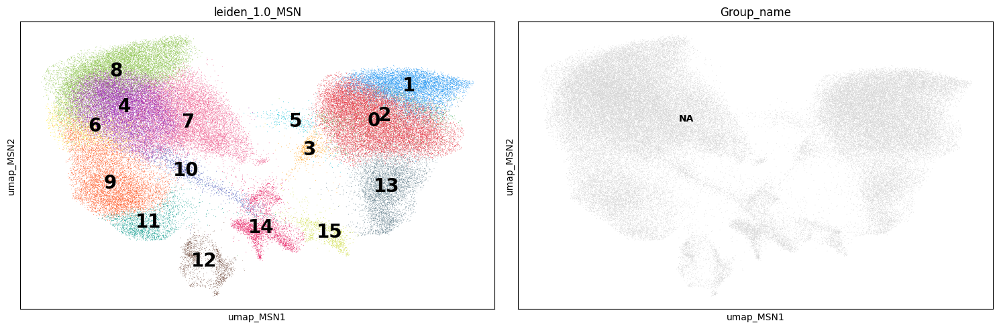

In [125]:
lmu.plot_to_decide(adata_nn, NAME, ADATA_NN_LEIDEN_COL_FOR_MAPPING, GROUP_LABELS)

ct_for_deg
Oligodendrocyte            119103
true_MSN                    71728
Astrocyte                   49194
-Low_quality                32724
Microglia                   12763
OPC                          7936
STR FS PTHLH-PVALB GABA      7233
STR TAC3 GABA                5424
-Phase_D                     4280
Ependymal                    3626
eMSN_D1D2                    3480
STR SST-CHODL GABA           1547
Fibroblast                   1201
Endothelial_BBB              1143
-Activated_Microglia          990
eMSN_NUDAP                    951
eMSN_StrioMat                 919
non-MSN                       852
Cholinergic GABA              842
VIP GABA                      809
Macrophages                   801
STR RSPO2 GABA                668
Pericyte                      586
-Cycling_Microglia            488
Tcells                        242
COP                           167
SmoothMuscleCells              94
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


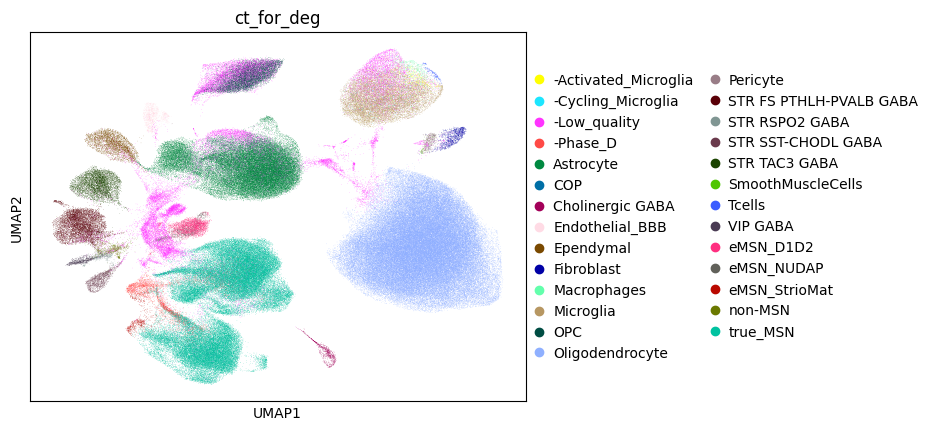

... storing 'tmp_label' as categorical


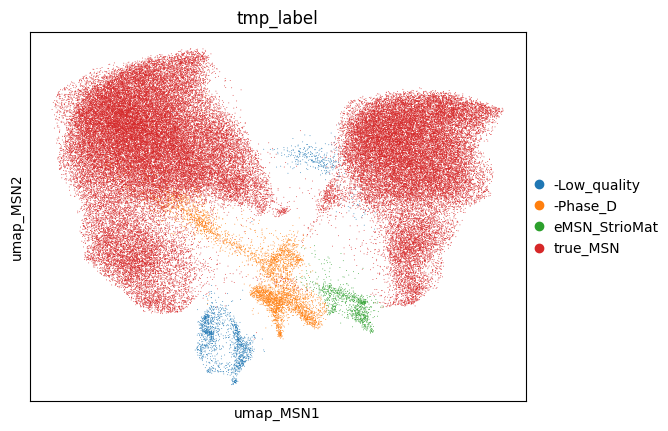

In [127]:
# map clusters to yout ct
mapping_dict = {

    "15": "eMSN_StrioMat",

    "14": "-Phase_D",
    "10": "-Phase_D",

    "5": LOW_QUALITY_LABEL, # astro

    "12": LOW_QUALITY_LABEL, # logio + astro

    # Microglia all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("true_MSN")

# Add to orignla ct
if "ct_for_deg" not in adata.obs.columns:
    adata.obs["ct_for_deg"] = np.nan
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")


# Recluter clean MSN D1D2

In [139]:
adata_nn = adata[adata.obs["ct_for_deg"] == "true_MSN"].copy()
adata_nn


AnnData object with n_obs × n_vars = 71728 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 'zone

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Computing UMAP...
Computing Leiden clusters...


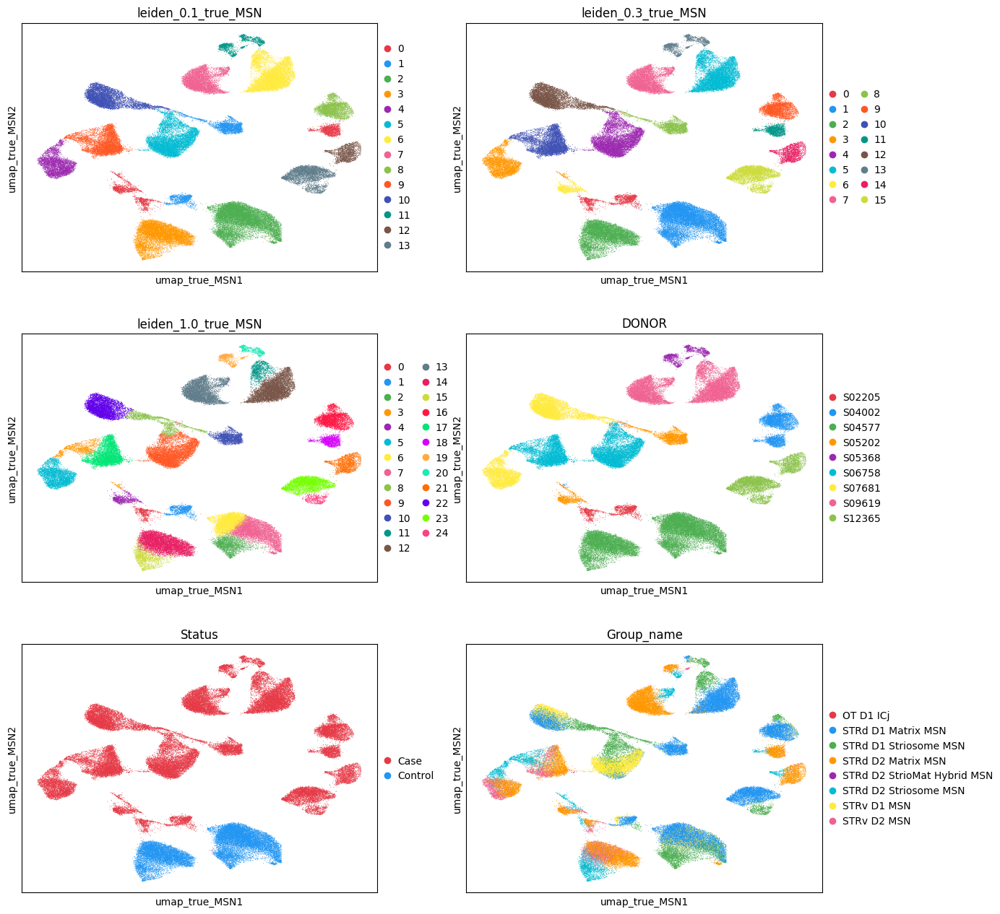

In [142]:
NAME="_true_MSN"

#remov elow vianerc egenes
sc.pp.filter_genes(adata_nn, min_cells=3)


# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=False, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, SAMPLE_VARIABLE, CONDITION_VARIABLE, "Group_name"], ncols=2, palette=preprocessing.custom_palette)



Assure that adata.var.index has same gene name of makers...


  0%|          | 0/1 [00:00<?, ?it/s]

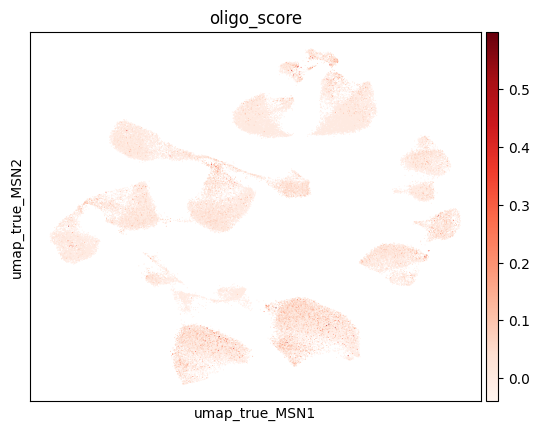

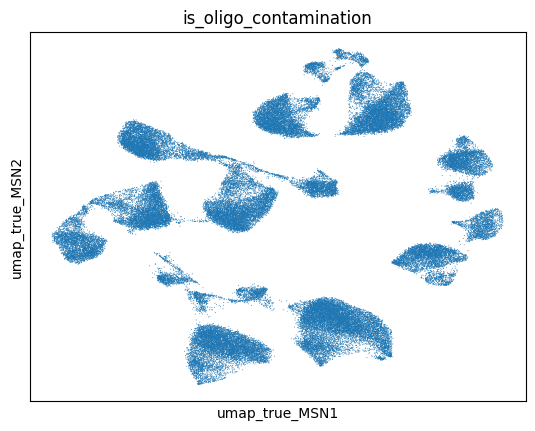

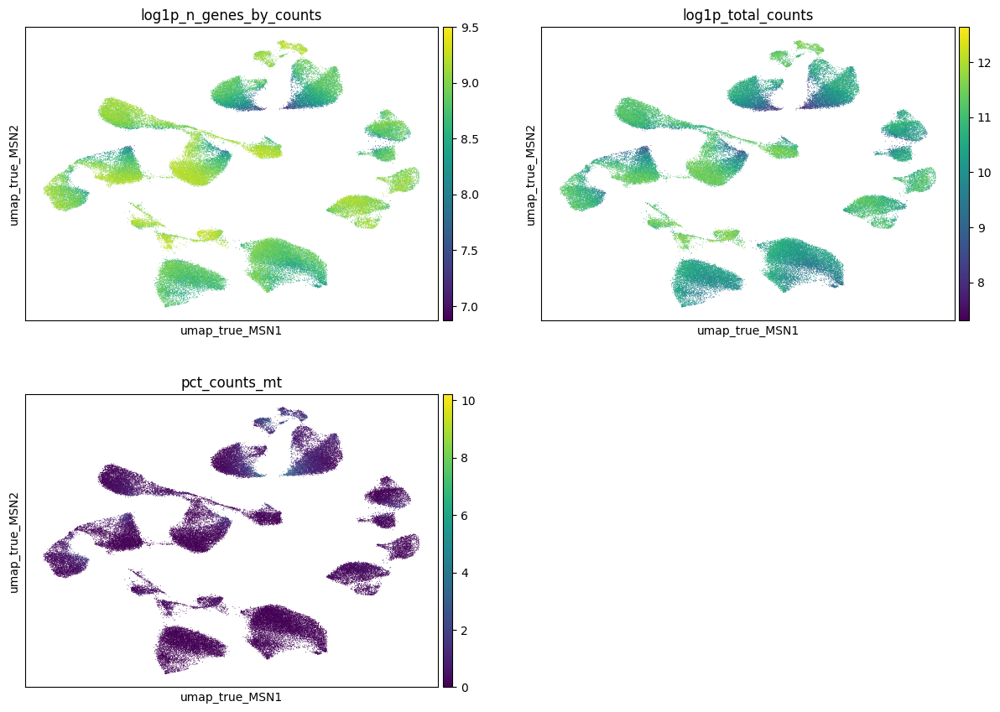

In [153]:
# Check if they are ooligos contamiantion
dict_oligo={"oligo": ["MBP", 'PLP1', 'MOBP', 'TMEM144', "MOG"]}
col_oligo_score = preprocessing.calculate_and_plot_markers(adata_nn, dict_oligo, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap{NAME}")
adata_nn.obs["is_oligo_contamination"] = (adata_nn.obs[col_oligo_score[0]] >= 0.25).fillna(0).astype(bool)
#adata_nn.obs[col_oligo_score[0]].plot(kind="hist", bins=100)
sc.pl.embedding(adata_nn, color="is_oligo_contamination", basis=f"umap{NAME}", ncols=5, legend_loc=None)



sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"], legend_loc="on data", ncols=2)


... storing 'MSN_type' as categorical


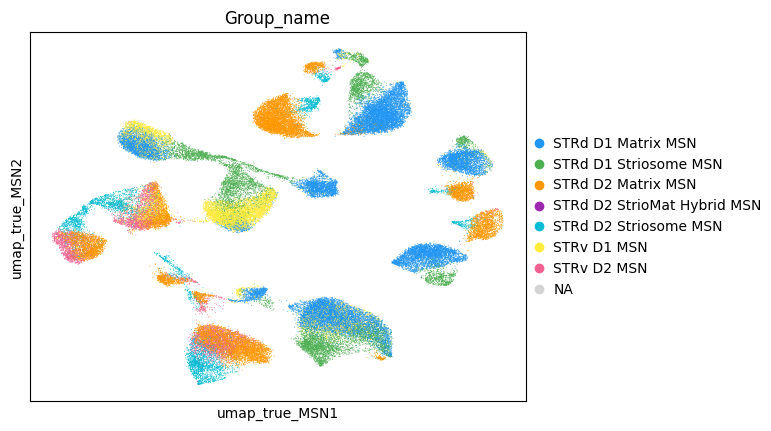

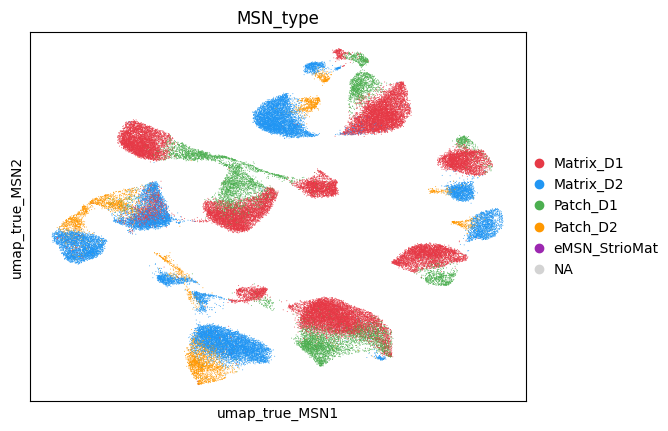

In [144]:
# map Group-name to broader categories
mapping_msn = {
    "STRd D1 Matrix MSN": "Matrix_D1",
    "STRd D2 Matrix MSN": "Matrix_D2",
    "STRv D1 MSN": "Matrix_D1",
    "STRv D2 MSN": "Matrix_D2",

    "STRd D2 Striosome MSN": "Patch_D2",
    "STRd D1 Striosome MSN": "Patch_D1",

    "STRd D2 StrioMat Hybrid MSN": "eMSN_StrioMat",
    "STR D1D2 Hybrid MSN": "eMSN_D1D2",
    "STRv D1 NUDAP MSN": "eMSN_NUDAP"
  }
adata_nn.obs["MSN_type"] = adata_nn.obs["Group_name"].map(mapping_msn)

ct_to_color = list(mapping_msn.keys())
ct_to_color

sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["Group_name"], groups=ct_to_color, ncols=2, palette=preprocessing.custom_palette)
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=["MSN_type"], ncols=2, palette=preprocessing.custom_palette)



ct_for_deg
Oligodendrocyte            119103
Astrocyte                   49194
Matrix_D1                   34927
-Low_quality                32724
Matrix_D2                   22601
Microglia                   12763
Patch_D1                     9511
OPC                          7936
STR FS PTHLH-PVALB GABA      7233
STR TAC3 GABA                5424
Patch_D2                     4682
Ependymal                    3626
eMSN_D1D2                    3480
-phase_D                     2824
STR SST-CHODL GABA           1547
-fake_phase_D                1456
Fibroblast                   1201
Endothelial_BBB              1143
-Activated_Microglia          990
eMSN_NUDAP                    951
eMSN_StrioMat                 925
non-MSN                       852
Cholinergic GABA              842
VIP GABA                      809
Macrophages                   801
STR RSPO2 GABA                668
Pericyte                      586
-Cycling_Microglia            488
Tcells                        242
COP

... storing 'ct_for_deg' as categorical


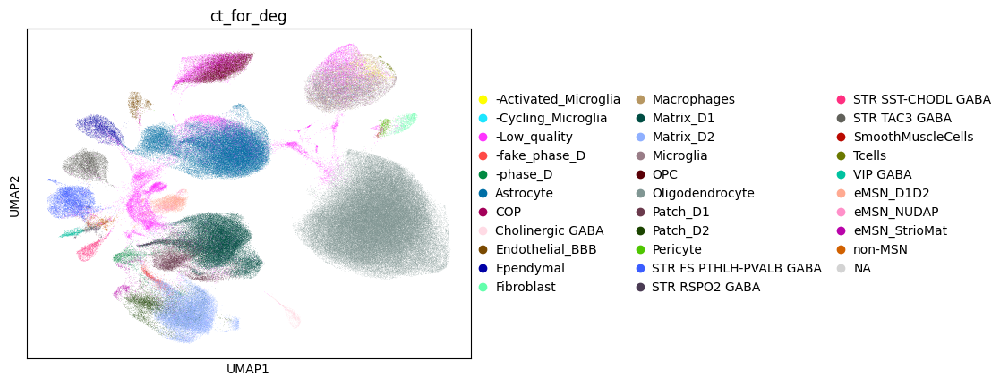

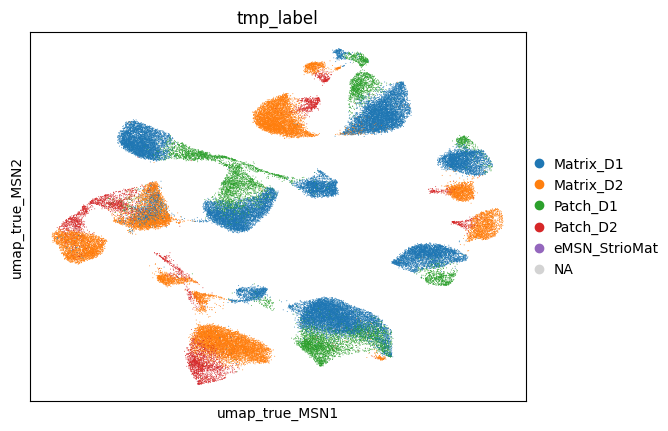

In [145]:
adata_nn.obs["tmp_label"] = adata_nn.obs["MSN_type"].copy()

adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")

# Recluster PhaseD

In [137]:
adata_nn = adata[adata.obs["ct_for_deg"] == "-Phase_D"].copy()
adata_nn

AnnData object with n_obs × n_vars = 71728 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 'zone

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Computing UMAP...
Computing Leiden clusters...


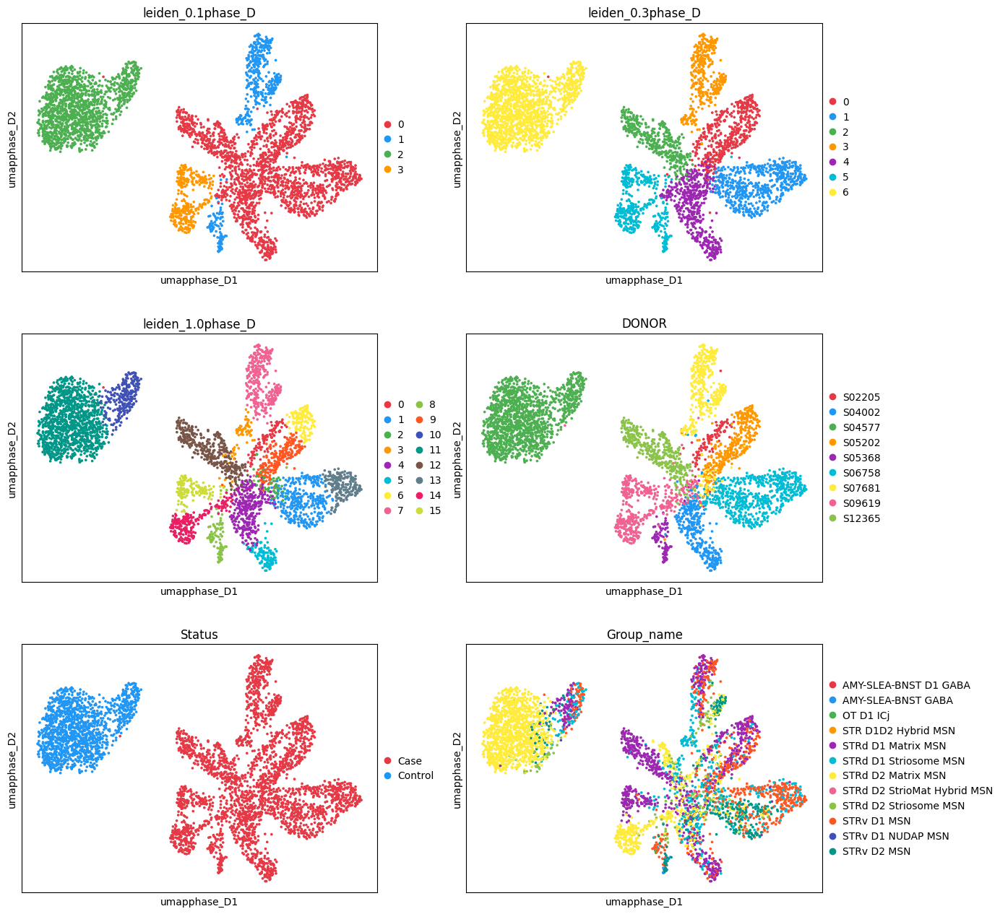

In [131]:
NAME="phase_D"

#remov elow vianerc egenes
sc.pp.filter_genes(adata_nn, min_cells=3)


# rerun analsys
leiden_cluster_names = lmu.preprocess_common_pipeline(adata_nn, umap_name=NAME, leiden_name=NAME, resolutions = [0.1, 0.3, 1.0], integrate_with_harmony=False, batch_key=SAMPLE_VARIABLE)

# plot umap
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[*leiden_cluster_names, SAMPLE_VARIABLE, CONDITION_VARIABLE, "Group_name"], ncols=2, palette=preprocessing.custom_palette)



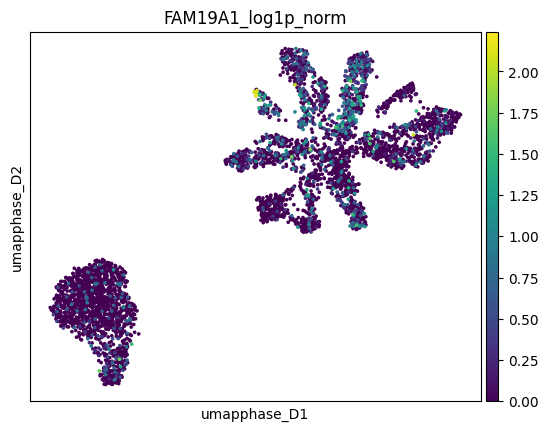

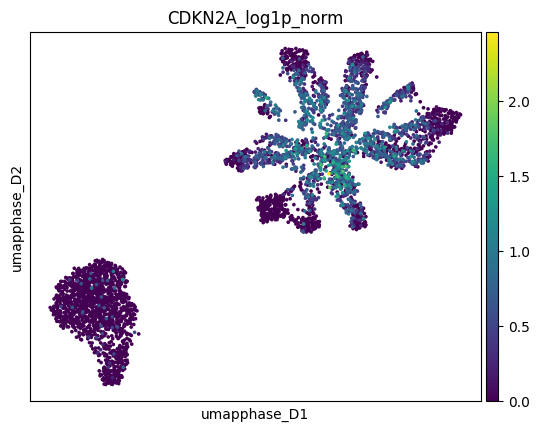

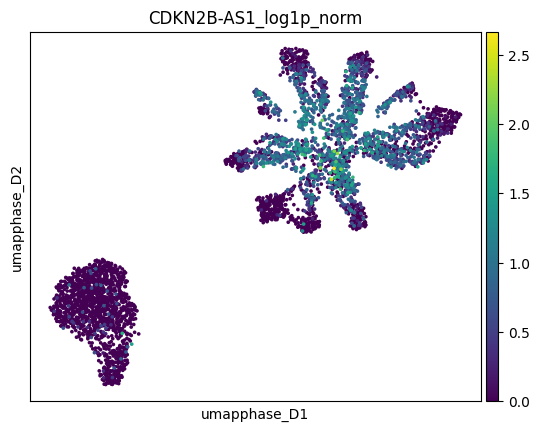

In [130]:
# TAFA1

for gene in ["FAM19A1", "CDKN2A", "CDKN2B-AS1"]: 
    idx_tafa1 = adata_nn.var.index.get_indexer(adata_nn.var.query(f"gene_symbol == '{gene}'").index)
    adata_nn.obs[f"{gene}_log1p_norm"] = adata_nn.layers["log1p_norm"][:, idx_tafa1].toarray().ravel()
    sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=[f"{gene}_log1p_norm"], ncols=2,)
    plt.show()

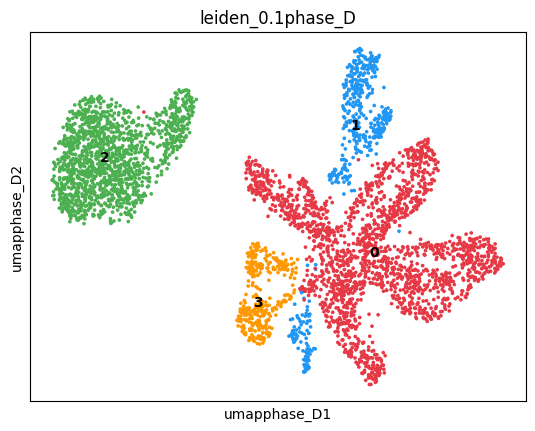

In [132]:
ADATA_NN_LEIDEN_COL_FOR_MAPPING = f"leiden_0.1{NAME}"
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color=ADATA_NN_LEIDEN_COL_FOR_MAPPING, legend_loc="on data")

In [133]:
# # Wilcoxon
# res = preprocessing.rank_markers_per_cluster(adata_nn, ADATA_NN_LEIDEN_COL_FOR_MAPPING, layer="log1p_norm", n_genes=50, markers=None,
#                                              #groups=["12", "14"]
#                                              )

# for cluster, df in res.items():
#     print(f"Cluster {cluster}:")
#     df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
#     display(df.head(30))

ct_for_deg
Oligodendrocyte            119103
true_MSN                    71728
Astrocyte                   49194
-Low_quality                32724
Microglia                   12763
OPC                          7936
STR FS PTHLH-PVALB GABA      7233
STR TAC3 GABA                5424
Ependymal                    3626
eMSN_D1D2                    3480
-phase_D                     2824
STR SST-CHODL GABA           1547
-fake_phase_D                1456
Fibroblast                   1201
Endothelial_BBB              1143
-Activated_Microglia          990
eMSN_NUDAP                    951
eMSN_StrioMat                 919
non-MSN                       852
Cholinergic GABA              842
VIP GABA                      809
Macrophages                   801
STR RSPO2 GABA                668
Pericyte                      586
-Cycling_Microglia            488
Tcells                        242
COP                           167
SmoothMuscleCells              94
Name: count, dtype: int64


... storing 'ct_for_deg' as categorical


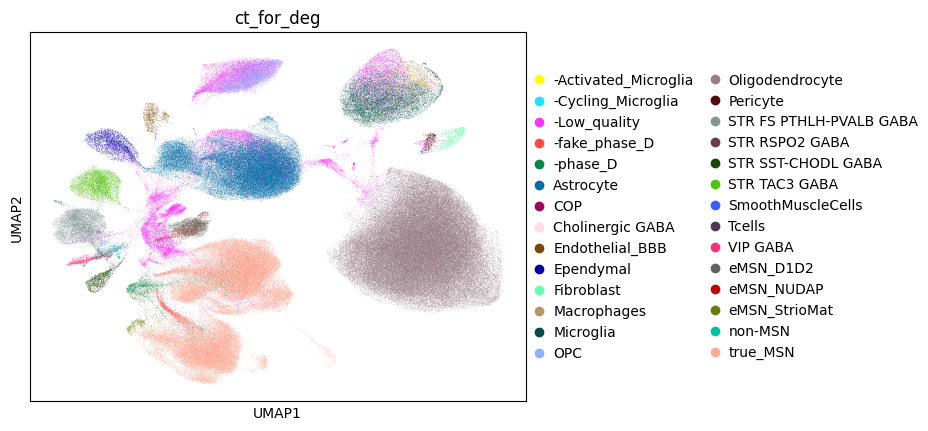

... storing 'tmp_label' as categorical


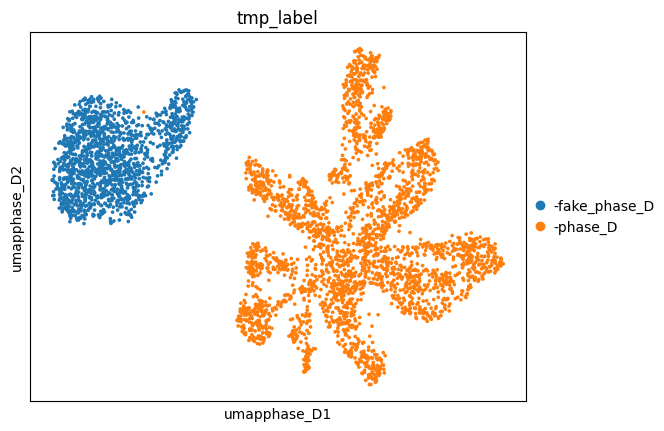

In [135]:
# map clusters to yout ct
mapping_dict = {


    "2": "-fake_phase_D", # ONYL HE,THY SAMPLE
    # Microglia all the rest
}
adata_nn.obs["tmp_label"] = adata_nn.obs[ADATA_NN_LEIDEN_COL_FOR_MAPPING].map(mapping_dict).fillna("-phase_D")

# Add to orignla ct
if "ct_for_deg" not in adata.obs.columns:
    adata.obs["ct_for_deg"] = np.nan
adata.obs["ct_for_deg"] = adata.obs["ct_for_deg"].astype(object)
adata.obs.loc[adata_nn.obs_names, "ct_for_deg"] = adata_nn.obs["tmp_label"] # loc align


print(adata.obs["ct_for_deg"].value_counts())
sc.pl.umap(adata, color="ct_for_deg")
sc.pl.embedding(adata_nn, basis=f"umap{NAME}", color="tmp_label")


# All rest

In [146]:
adata.obs["ct_for_deg"] = (
    adata.obs["ct_for_deg"]
    .astype(object)
    .fillna("-Unassigned")
    .replace("nan", "-Unassigned")
    .astype("category")
)

print(adata.obs["ct_for_deg"].value_counts())

ct_for_deg
Oligodendrocyte            119103
Astrocyte                   49194
Matrix_D1                   34927
-Low_quality                32724
Matrix_D2                   22601
Microglia                   12763
Patch_D1                     9511
OPC                          7936
STR FS PTHLH-PVALB GABA      7233
STR TAC3 GABA                5424
Patch_D2                     4682
Ependymal                    3626
eMSN_D1D2                    3480
-phase_D                     2824
STR SST-CHODL GABA           1547
-fake_phase_D                1456
Fibroblast                   1201
Endothelial_BBB              1143
-Activated_Microglia          990
eMSN_NUDAP                    951
eMSN_StrioMat                 925
non-MSN                       852
Cholinergic GABA              842
VIP GABA                      809
Macrophages                   801
STR RSPO2 GABA                668
Pericyte                      586
-Cycling_Microglia            488
Tcells                        242
COP

# "is neuron"

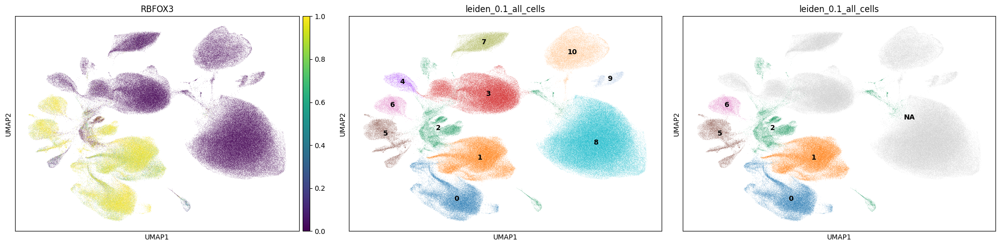

In [148]:
CLUSTERS_ALL_CELLS_COL = "leiden_0.1_all_cells"
CLUSTERS_GROUP_ALL_CELLS =  ["0", "1", "2", "5", "6"]
MMC_ANNOTATION_LEVEL = "Subclass_name"

# to help  picking clusters
fig, ax = plt.subplots(1, 3, figsize=(20,5))
sc.pl.umap(adata, color="RBFOX3", gene_symbols="gene_symbol", ax=ax[0], show=False, legend_loc="on data", layer="log1p_norm", vmax=1)
sc.pl.umap(adata, color=CLUSTERS_ALL_CELLS_COL, ax=ax[1], show=False, legend_loc="on data")
sc.pl.umap(adata, color=CLUSTERS_ALL_CELLS_COL, groups=CLUSTERS_GROUP_ALL_CELLS, ax=ax[2], show=False, legend_loc="on data")
plt.tight_layout(); plt.show()

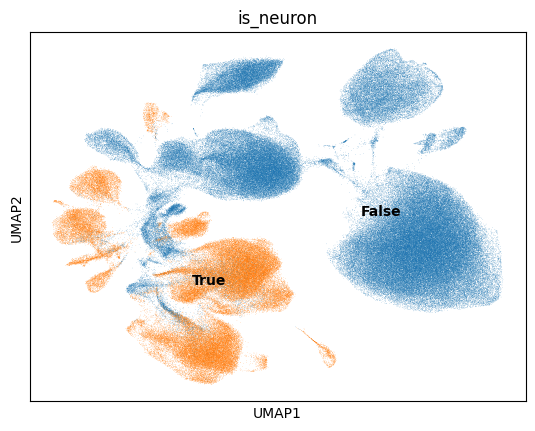

In [149]:
adata.obs["is_neuron"] = adata.obs[CLUSTERS_ALL_CELLS_COL].isin(CLUSTERS_GROUP_ALL_CELLS) & (~adata.obs["ct_for_deg"].str.startswith("-"))
sc.pl.umap(adata, color="is_neuron", legend_loc="on data")


# Save

In [150]:
SAVE_PATH =  f'/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_DEEPDIVE_curated.h5ad'
print(SAVE_PATH)
#print(adata)

/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_DEEPDIVE_curated.h5ad


In [151]:
adata.write_h5ad(SAVE_PATH)

/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


# Reload

In [3]:
adata = sc.read_h5ad(SAVE_PATH)#, backed="r")

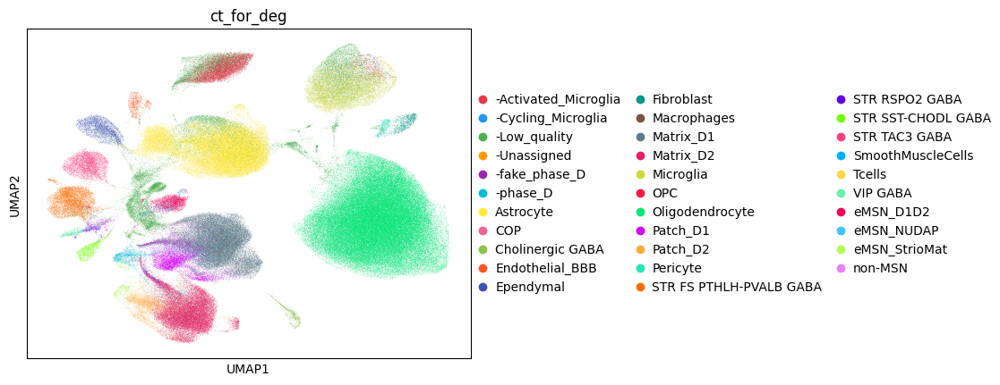

In [152]:
sc.pl.umap(adata, color="ct_for_deg", palette=preprocessing.custom_palette)

# ---

In [ ]:
for ct, group, zone_col in [
        ("Matrix_D1", ["STRd D1 Matrix MSN", "STRv D1 MSN"], "zone"), 
        ("Matrix_D2", ["STRd D2 Matrix MSN", "STRv D2 MSN"], "zone"), 
        ("Patch_D1", ["STRd D1 Striosome MSN"], "zone_4"), 
        ("Patch_D2", ["STRd D2 Striosome MSN"], "zone_4"), 
        ("eMSN_D1D2", ["STR D1D2 Hybrid MSN"], "zone_4"), 
        ("Astrocyte", ["Astrocyte"], "zone_4"), 
    ]:

    print(ct, group)

    mask_group = adata.obs["Group_name"].isin(group)

    adata_sub = adata[mask_group].copy()
    adata_sub_village = adata_sub[adata_sub.obs["experiment"] == "village"].copy()
    display(adata_sub)
    display(adata.obs[zone_col].value_counts())


    fig, axis = plt.subplots(1,2, figsize=(12,6))
    sns.countplot(data=adata_sub.obs, x=zone_col, hue=CONDITION_VARIABLE, ax=axis[0]); axis[0].set_title(ct)
    sns.countplot(data=adata_sub_village.obs, x=zone_col, hue=CONDITION_VARIABLE, ax=axis[1]); axis[1].set_title("Only Village")
    plt.show()


    # lmu.preprocess_common_pipeline(adata_sub, umap_name=f"_check_{ct}", leiden_name=f"_check_{ct}", resolutions = [0.1], integrate_with_harmony=True, batch_key=SAMPLE_VARIABLE)
    # sc.pl.embedding(adata_sub, basis=f"umap_check_{ct}", color=["Group_name", "ct_for_deg", zone_col, CONDITION_VARIABLE], ncols=2, palette=preprocessing.custom_palette)

# Compare Matrix D1 Matthew

In [ ]:
adata.obs["village"] = np.where(adata.obs["experiment"] == "village", adata.obs["reaction"].str.split("_").str[0], np.nan)


display(adata.obs[adata.obs["experiment"] =="village"]["village"].value_counts().head(10))
display(adata.obs[adata.obs["experiment"] =="deepdive"]["DONOR"].value_counts().head(9))
display(adata.obs[adata.obs["experiment"] =="village"]["DONOR"].nunique())

In [ ]:
d1d2_mat = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/from_matthew/STR_D1D2_Hybrid_MSN.h5ad")
print(d1d2_mat)

d1d2 = adata[adata.obs["Group_name"].isin(["STR D1D2 Hybrid MSN"])].copy()
display(d1d2)

In [ ]:
md1_mat = sc.read_h5ad("/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/from_matthew/STR_D1_Matrix_MSN.h5ad")
print(md1_mat)

md1 = adata[adata.obs["Group_name"].isin(["STRd D1 Matrix MSN", "STRv D1 MSN"])].copy()
print(md1)
md1.obs["is_deepdive"].value_counts()

In [ ]:
display(md1_mat.obs)
display(md1.obs)

display(md1.obs[md1.obs["CELL_BARCODE"].isin(set(md1.obs["CELL_BARCODE"]).difference(set(md1_mat.obs["CELL_BARCODE"])))])
display(md1.obs[md1.obs["reaction"].isin(set(md1.obs["reaction"]).difference(set(md1_mat.obs["reaction"])))])